# Estudo de Caso 2: Tempo de Tramitação no 4º JEC de Natal/RN — conciliação obrigatória presencial, remota e rito atual

**Autor:** rafaelcc · **Disciplina:** Ciência de Dados e Estatística aplicadas ao Direito e Políticas Públicas (CDEaDPP) — 2026.2 · **Professor:** Cleuler Barbosa das Neves
**Notebook:** `rafaelcc_ed2.ipynb` (gerado por `src/build_rafaelcc_ed2.py`; não editar à mão)

## Introdução

**O experimento.** O juiz titular do 4º Juizado Especial Cível (JEC) de Natal/RN, Paulo Giovani Militão de Alencar, conduziu, como pesquisa de mestrado profissional (PPGDP/UFG, orientação do Prof. Cleuler), um experimento na própria unidade. Cada ação de conhecimento distribuída ao 4º JEC entre **01/01/2026 e 03/08/2026** foi submetida a um sorteio que definia o rito procedimental:

| Grupo (código) | Rótulo neste notebook | Rótulo na planilha | Descrição |
|---|---|---|---|
| `Controle` | Controle (rito atual, AC opcional) | Rito Atual Ac Opcional | Fluxo vigente em Natal desde a pandemia: citação para contestar, sem audiência de conciliação (AC) inaugural, salvo pedido conjunto das partes |
| `Presencial` | AC presencial obrigatória | Ac Obrigatória Presencial | AC inaugural obrigatória (art. 21 da Lei 9.099/1995), no fórum, conduzida por servidora do CEJUSC |
| `Remota` | AC remota obrigatória | Ac Remota | AC inaugural obrigatória por videoconferência (Teams), conduzida por servidora do gabinete |

Nas audiências, a técnica de conciliação também era sorteada (seis técnicas). A planilha de acompanhamento, alimentada diariamente pela unidade, registra **943 processos** sorteados (944 linhas) com o rito, a ocorrência de acordo na audiência ou fora dela, a técnica, o tipo e a data da sentença. A versão analisada foi **atualizada em 07/10/2026**: os processos ainda sem sentença nessa data estão em tramitação e têm, portanto, tempo **censurado à direita**.

**Variável-alvo.** O **tempo de tramitação**, em dias corridos, da distribuição ao 4º JEC até a sentença (de mérito, sem mérito ou homologatória de acordo).

**Perguntas de pesquisa.**

1. **Curadoria.** Os dados brutos são confiáveis? Que anomalias existem e como tratá-las sem inventar informação?
2. **Efeito sobre o tempo.** A audiência de conciliação obrigatória, presencial ou remota, altera o tempo até a sentença em relação ao rito atual?
3. **Efeito sobre o acordo.** A audiência obrigatória aumenta a proporção de acordos? A modalidade (presencial × remota) importa?
4. **Desenho.** O sorteio produziu grupos comparáveis? Que limitações (censura, redistribuições, híbridas, unidade única) afetam a validade interna e a externa?
5. **Questões do professor.** Respostas às questões 2.2 a 2.12 do roteiro.

**Pipeline de ciência de dados.**

| Parte | Seções | Conteúdo |
|---|---|---|
| I. Curadoria | 1 | Ambiente; formação do dataset bruto; fórmulas e data de corte; tipos e tipologia das variáveis; ausências, duplicidades, número CNJ, grafias, recodificações e desvios de protocolo; dataset *tidy* com tempo e evento; verificações; registro de tratamentos; dicionário e exportação |
| II. Exploratória | 2 | Análise univariada e bivariada com o tempo como alvo; normalidade e ajuste de distribuições; modelo binomial para as proporções |
| III. Testes de hipóteses | 3 | Testes adequados a cada pergunta (qui-quadrado, Fisher, Kruskal-Wallis, Mann-Whitney, Dunn, sequências), com tamanho de efeito e correção de multiplicidade |
| IV. Análise de sobrevivência | 4 | Kaplan-Meier, log-rank, Cox, modelos AFT, riscos competitivos (Aalen-Johansen, Fine-Gray) e tempo médio restrito (RMST) |
| V. Multivariada e regressão | 5 | Modelos com covariáveis (mês de distribuição, origem do processo), regressão logística para o acordo e diagnósticos |
| VI. Questões do professor | 6 | Respostas fundamentadas às questões 2.2 a 2.12 |
| VII. Síntese | 7 | Conclusões, limitações e sugestões para a replicação |

### O notebook do professor

O notebook inicial `estcaso_4jec_natal_rn.ipynb` foi revisado célula a célula (30 problemas catalogados, E1 a E30). Os principais, corrigidos aqui:

- **E1** — `from lifelines import KaplanMeierFitter, logrank_test` falha (a função fica em `lifelines.statistics`), e o `except ImportError` desliga silenciosamente o Kaplan-Meier: a única análise adequada a dados censurados nunca é executada;
- **E7/E14** — os tempos dos processos em tramitação (censurados) são tratados como tempos completos, e a "janela de 218 dias" não corresponde aos dados; a data de referência real é 07/10/2026, fixada aqui;
- **E3** — duplicidades detectadas e não tratadas (há processos redistribuídos que voltaram e foram **sorteados de novo**, inclusive para outro grupo);
- **E4/E5** — o marcador `**` ("não se aplica") e as ausências estruturais são tratados como categorias ou como "Não";
- **E10** — a "Decisão" (redistribuição por prevenção) é contada como sentença;
- **E6/E16** — quatro colunas de duração são a mesma variável, e a matriz de correlação entre elas é tautológica (r = 1);
- **E17–E27** — Kruskal-Wallis, OLS e ajuste de distribuições aplicados a tempos censurados; testes tautológicos (Encerrado × Ativo) e sem tamanho de efeito nem correção de multiplicidade.

Em cada seção, quando a abordagem difere da do notebook do professor, o erro corrigido é indicado pelo código (E*n*).

---

# PARTE I — CURADORIA DOS DADOS

A Parte I transforma a planilha da pesquisadora num dataset analítico (*tidy*: uma linha por processo, uma coluna por variável, um tipo adequado por coluna). O roteiro segue a auditoria completa dos dados brutos, e cada decisão é registrada num **log de tratamentos** exportado ao final. Duas regras valem em toda a Parte I:

1. **O arquivo-fonte nunca é alterado**, e `dados_brutos` preserva exatamente a leitura; todas as transformações ocorrem numa cópia de trabalho.
2. **Nenhuma data ou duração é imputada.** O que falta continua faltando, e os processos sem sentença são tratados como **censurados** na data de corte.

## 1.1 Preparação do ambiente

A primeira célula concentra as importações, os caminhos, as constantes do estudo e a identidade visual que as demais partes do notebook reutilizam:

- **`DATA_CORTE = 07/10/2026`**: data de referência da censura (seção 1.3);
- **`CORES_GRUPO`**: uma cor fixa por grupo, da paleta de Okabe-Ito (segura para daltonismo). A mesma cor representa o mesmo grupo em todos os gráficos;
- **avisos**: só são silenciados os avisos conhecidos e inofensivos (extensões do Excel que o `openpyxl` não lê e avisos de depreciação). O notebook do professor usava `warnings.filterwarnings('ignore')`, que esconde qualquer problema, inclusive o que desligou o Kaplan-Meier (E1).

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import importlib
import platform
import re
import sys
import unicodedata
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, pairwise_logrank_test
import sklearn
import scikit_posthocs as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
from IPython.display import display, Markdown

# Avisos conhecidos e inofensivos (não se usa filterwarnings('ignore') global)
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)

# ---------------------------------------------------------------- caminhos
ARQUIVO_BRUTO = 'ControleDosProcessos_Mestrado_Atualizacao_07.10.2026.xlsx'
_candidatos = [Path.cwd(), Path.cwd() / 'EstudodeCaso2', Path.cwd().parent, Path.cwd().parent / 'EstudodeCaso2']
RAIZ = next((p.resolve() for p in _candidatos if (p / ARQUIVO_BRUTO).exists()), None)
if RAIZ is None:
    raise FileNotFoundError(f'{ARQUIVO_BRUTO} não encontrado. Inicie o kernel na raiz do projeto ou em EstudodeCaso2.')
BRUTO = RAIZ / ARQUIVO_BRUTO
PROC = RAIZ / 'dat' / 'processado'
FIG = RAIZ / 'fig'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- constantes do estudo
DATA_INICIO = pd.Timestamp('2026-01-01')        # primeira distribuição
FIM_RECRUTAMENTO = pd.Timestamp('2026-08-03')   # último sorteio
DATA_CORTE = pd.Timestamp('2026-10-07')         # atualização da planilha = censura administrativa
SEMENTE = 2026
RNG = np.random.default_rng(SEMENTE)

ORDEM_GRUPO = ['Controle', 'Presencial', 'Remota']   # referência = Controle
ROTULO_GRUPO = {'Controle': 'Controle (rito atual, AC opcional)',
                'Presencial': 'AC presencial obrigatória',
                'Remota': 'AC remota obrigatória'}
CORES_GRUPO = {'Controle': '#0072B2', 'Presencial': '#E69F00', 'Remota': '#009E73'}   # Okabe-Ito
ORDEM_DESFECHO = ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição', 'Ativo']
CORES_DESFECHO = {'Homologação': '#009E73', 'Mérito': '#0072B2', 'Sem mérito': '#D55E00',
                  'Redistribuição': '#CC79A7', 'Ativo': '#999999'}
TINTA, TINTA_2, GRADE = '#1a1a1a', '#555555', '#e5e5e5'

plt.rcParams.update({
    'figure.dpi': 100, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': TINTA_2,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.grid': True, 'grid.color': GRADE,
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'font.size': 10, 'legend.frameon': False,
    'axes.prop_cycle': mpl.cycler(color=list(CORES_GRUPO.values())),
})
sns.set_palette(list(CORES_GRUPO.values()))


# ---------------------------------------------------------------- números em pt-BR
def fmt_br(valor, casas=1):
    """Formata número no padrão brasileiro: 1.234,5."""
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return '–'
    return f'{valor:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def pct_br(proporcao, casas=1):
    """Proporção (0–1) como percentual pt-BR: 12,3%."""
    return fmt_br(100 * proporcao, casas) + '%'


def p_br(p):
    """Valor-p em pt-BR, com limite inferior."""
    return '< 0,001' if p < 0.001 else fmt_br(p, 3)


print(f'Python {platform.python_version()} | pasta do estudo: {RAIZ}')
print(f'Data de corte (censura): {DATA_CORTE:%d/%m/%Y}')

Python 3.12.8 | pasta do estudo: C:\Users\MPGO\AulaCleuler\EstudodeCaso2
Data de corte (censura): 07/10/2026


### Versões das bibliotecas e o erro de importação do notebook do professor

A tabela registra as versões usadas (reprodutibilidade; o ambiente é o `uv.lock` do projeto). Em seguida, a célula reproduz o import do notebook do professor. A função `logrank_test` **não** existe no espaço de nomes principal do `lifelines`; ela fica em `lifelines.statistics`. No notebook original, o `ImportError` era capturado por um `except` que fazia `TEM_LIFELINES = False`, e todo o Kaplan-Meier era pulado **mesmo com a biblioteca instalada** (E1).

In [2]:
BIBLIOTECAS = ['pandas', 'numpy', 'scipy', 'statsmodels', 'lifelines', 'sklearn', 'scikit_posthocs',
               'matplotlib', 'seaborn', 'openpyxl', 'nbformat']
versoes = pd.DataFrame(
    [(nome, getattr(importlib.import_module(nome), '__version__', '?')) for nome in BIBLIOTECAS],
    columns=['Biblioteca', 'Versão'])
display(versoes.set_index('Biblioteca').T)

try:
    from lifelines import logrank_test as _teste  # import do notebook do professor
    resultado_import = 'funcionou'
except ImportError as erro:
    resultado_import = f'ImportError: {erro}'
print('from lifelines import logrank_test            ->', resultado_import)
print('from lifelines.statistics import logrank_test ->', logrank_test.__module__, '(correto)')

Biblioteca,pandas,numpy,scipy,statsmodels,lifelines,sklearn,scikit_posthocs,matplotlib,seaborn,openpyxl,nbformat
Versão,3.0.5,2.5.2,1.18.0,0.15.0,0.30.0,1.9.0,0.17.0,3.11.1,0.13.2,3.1.5,5.11.1


from lifelines import logrank_test            -> ImportError: cannot import name 'logrank_test' from 'lifelines' (C:\Users\MPGO\AulaCleuler\.venv\Lib\site-packages\lifelines\__init__.py)
from lifelines.statistics import logrank_test -> lifelines.statistics (correto)


---

## 1.2 Formação do dataset bruto

### 1.2.1 As abas da planilha

O arquivo tem oito abas, mas só uma contém dados por processo. As demais são painéis, tabelas dinâmicas e listas de validação construídas **a partir** da aba `Processos`; servem apenas para conferência (seção 1.13).

In [3]:
livro = openpyxl.load_workbook(BRUTO, data_only=False)   # fórmulas, não valores
PAPEL_ABA = {
    'Processos': 'Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica',
    'Dash1': 'Painel (segmentações/gráficos), sem dados',
    'Dash2': 'Painel (segmentações/gráficos), sem dados',
    'Dash3': 'Painel (segmentações/gráficos), sem dados',
    'Tab_D': 'Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)',
    'Tabelas': 'Resumos com fórmulas (acordos, "eficiência" por rito)',
    'Resumo': 'Questionário de perguntas descritivas (valores vazios no cache)',
    'Lista': 'Listas das validações de dados (valores permitidos nas colunas)',
}
abas = pd.DataFrame([{
    'Aba': ws.title,
    'Visibilidade': 'oculta' if ws.sheet_state != 'visible' else 'visível',
    'Intervalo usado': ws.dimensions,
    'Células preenchidas': sum(c.value is not None for linha in ws.iter_rows() for c in linha),
    'Papel': PAPEL_ABA.get(ws.title, ''),
} for ws in livro.worksheets])
display(abas)

ws = livro['Processos']
print('Tabela Excel na aba Processos:', {nome: ref for nome, ref in ws.tables.items()})
print('Colunas ocultas:', [c for c, d in ws.column_dimensions.items() if d.hidden])
print('Linha 1 (acima do cabeçalho):', [ws.cell(1, c).value for c in range(1, 16)])

,Aba,Visibilidade,Intervalo usado,Células preenchidas,Papel
0,Processos,visível,A2:O946,13317,Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica
1,Dash1,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
2,Dash2,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
3,Dash3,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
4,Tab_D,oculta,A1:BG144,351,"Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)"
5,Tabelas,visível,A2:AL49,623,"Resumos com fórmulas (acordos, ""eficiência"" por rito)"
6,Resumo,visível,A2:C25,25,Questionário de perguntas descritivas (valores vazios no cache)
7,Lista,oculta,A1:I8,26,Listas das validações de dados (valores permitidos nas colunas)


Tabela Excel na aba Processos: {'TAB_DADOS': 'A2:O946'}
Colunas ocultas: ['J', 'M', 'P']
Linha 1 (acima do cabeçalho): [None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]


### 1.2.2 Leitura da aba `Processos`

A linha 1 está vazia e o cabeçalho está na linha 2 (`header=1`). O índice de `dados_brutos` passa a ser o **número da linha no Excel** (`linha_excel`), o que permite rastrear cada tratamento até a célula de origem. `dados_brutos` não é modificado em nenhum momento.

In [4]:
dados_brutos = pd.read_excel(BRUTO, sheet_name='Processos', header=1, engine='openpyxl')
dados_brutos.index = pd.RangeIndex(3, 3 + len(dados_brutos), name='linha_excel')

print(f'{dados_brutos.shape[0]} linhas × {dados_brutos.shape[1]} colunas (linhas 3 a {dados_brutos.index[-1]} do Excel)')
print('Nomes das colunas (repr, para ver espaços):')
print([c for c in dados_brutos.columns])
print(f'Linhas inteiramente vazias: {dados_brutos.isna().all(axis=1).sum()} | '
      f'números de processo distintos: {dados_brutos["NÚMERO DO PROCESSO"].nunique()}')
display(dados_brutos.head(5))

944 linhas × 15 colunas (linhas 3 a 946 do Excel)
Nomes das colunas (repr, para ver espaços):
['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA', 'DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT', 'DURAÇÃO-PROC', ' DURAÇÃO DO PROCESSO', 'STATUS']
Linhas inteiramente vazias: 0 | números de processo distintos: 938


,NÚMERO DO PROCESSO,DT. DISTRIBUIÇÃO,SORTEIO,HÍBRIDA,TEVE ACORDO NA AC?,TÉCNICA,TEVE ACORDO FORA DA AC?,SENTENÇA,DT. SENTENÇA,DURAÇÃO-SENT2,DURAÇÃO-TECN,DURAÇÃO-SORT,DURAÇÃO-PROC,DURAÇÃO DO PROCESSO,STATUS
linha_excel,,,,,,,,,,,,,,,
3,0800001-35.2026.8.20.5004,2026-01-01,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do feito sem julgamento de mérito,2026-01-07,6.0,NaN,6.0,6.0,6 dia(s),Encerrado
4,0800024-78.2026.8.20.5004,2026-01-06,Rito Atual Ac Opcional,Não,Não,**,NaN,NaN,NaT,274.0,NaN,274.0,274.0,274 dia(s),Ativo
5,0808292-43.2025.8.20.5300,2026-01-06,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito sem Julgamento de Mérito,2026-01-09,3.0,NaN,3.0,3.0,3 dia(s),Encerrado
6,0800038-62.2026.8.20.5004,2026-01-07,Ac Obrigatória Presencial,Não,Sim,Desconstrução da Verdade,Não,Extinção do Feito com Homologação do Acordo,2026-02-22,46.0,46.0,46.0,46.0,46 dia(s),Encerrado
7,0800035-10.2026.8.20.5004,2026-01-07,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito com Julgamento de Mérito,2026-02-27,51.0,NaN,51.0,51.0,51 dia(s),Encerrado


**Leitura.**

- **Uma única aba tem dados.** A aba `Processos` (tabela Excel `TAB_DADOS`, intervalo A2:O946) é a fonte de tudo o que vem depois. As abas `Dash1` a `Dash3` estão vazias de dados (só segmentações e gráficos); `Tab_D` e `Lista` estão **ocultas** e contêm as tabelas dinâmicas e as listas de validação; `Tabelas` e `Resumo` são resumos calculados.
- **944 linhas, não 943.** A aba tem 944 linhas de dados (linhas 3 a 946 do Excel), com **938 números de processo distintos**: há números repetidos (seção 1.9). O enunciado fala em 943 processos porque uma linha (920) não tem as fórmulas de duração e de status (seção 1.3).
- **15 colunas, não 11.** Nove são digitadas pela unidade (A a I); seis são calculadas por fórmula (J a O), três delas ocultas (J, M e a coluna vazia P). O nome de uma coluna começa com espaço (`' DURAÇÃO DO PROCESSO'`), detalhe que quebra qualquer código que a procure pelo nome "limpo".

---

## 1.3 Colunas digitadas × colunas calculadas: a data de corte

As colunas J a O da planilha **não são dados**: são fórmulas. Ler as fórmulas (e não apenas os valores) é essencial, porque a duração dos processos sem sentença é calculada com `TODAY()`, uma função **volátil**: cada vez que o arquivo é aberto, o tempo dos processos ativos aumenta, sem que nenhuma informação nova tenha sido coletada. A célula mostra a fórmula de cada coluna calculada e conta quantas linhas têm fórmula.

In [5]:
COLUNAS_CALCULADAS = {'J': 'DURAÇÃO-SENT2', 'K': 'DURAÇÃO-TECN', 'L': 'DURAÇÃO-SORT', 'M': 'DURAÇÃO-PROC',
                      'N': 'DURAÇÃO DO PROCESSO', 'O': 'STATUS'}
ultima = 2 + len(dados_brutos)
formulas = []
for letra, nome in COLUNAS_CALCULADAS.items():
    valores = [ws[f'{letra}{r}'].value for r in range(3, ultima + 1)]
    com_formula = [isinstance(v, str) and v.startswith('=') for v in valores]
    formulas.append({'Coluna': letra, 'Nome': nome,
                     'Linhas com fórmula': sum(com_formula),
                     'Usa TODAY()': 'TODAY()' in str(valores[0]),
                     'Oculta': ws.column_dimensions[letra].hidden,
                     'Fórmula (linha 3)': valores[0]})
with pd.option_context('display.max_colwidth', 140):
    display(pd.DataFrame(formulas))

sem_formula = [r for r in range(3, ultima + 1) if not str(ws[f'M{r}'].value or '').startswith('=')]
print('Linhas sem fórmula na coluna M:', sem_formula)
print('Conteúdo da linha', sem_formula[0], ':', [ws[f'{c}{sem_formula[0]}'].value for c in 'ABCDEFGHI'])

,Coluna,Nome,Linhas com fórmula,Usa TODAY(),Oculta,Fórmula (linha 3)
0,J,DURAÇÃO-SENT2,943,True,True,"=IF(TAB_DADOS[[#This Row],[SENTENÇA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
1,K,DURAÇÃO-TECN,943,True,False,"=IF(TAB_DADOS[[#This Row],[TÉCNICA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
2,L,DURAÇÃO-SORT,943,True,False,"=IF(TAB_DADOS[[#This Row],[SORTEIO]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
3,M,DURAÇÃO-PROC,943,True,True,"=ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3))))"
4,N,DURAÇÃO DO PROCESSO,943,False,False,"=IF(TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]="""","""",TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]&"" dia(s)"")"
5,O,STATUS,943,False,False,"=IF(AND(B3="""",I3=""""),"""",IF(AND(NOT(ISBLANK(B3)),NOT(ISBLANK(I3))),""Encerrado"",""Ativo""))"


Linhas sem fórmula na coluna M: [920]
Conteúdo da linha 920 : ['0813782-27.2026.8.20.5004', datetime.datetime(2026, 7, 29, 0, 0), 'Ac Obrigatória Presencial', None, None, None, None, None, None]


Os **valores em cache** (o que o Excel calculou na última gravação e o que o `pandas` lê) revelam a data em que `TODAY()` foi avaliado: para cada processo ativo, `DT. DISTRIBUIÇÃO + DURAÇÃO-PROC` é essa data. Se ela for única, é a data de corte de fato usada pela pesquisadora.

In [6]:
ativos_bruto = dados_brutos['STATUS'].eq('Ativo')
data_referencia = (dados_brutos.loc[ativos_bruto, 'DT. DISTRIBUIÇÃO']
                   + pd.to_timedelta(dados_brutos.loc[ativos_bruto, 'DURAÇÃO-PROC'], unit='D'))
display(data_referencia.dt.date.value_counts().rename('Processos ativos').to_frame())
assert data_referencia.nunique() == 1 and data_referencia.iloc[0] == DATA_CORTE

props = livro.properties
print(f'Última gravação do arquivo: {props.modified} (por {props.lastModifiedBy}); criado em {props.created:%d/%m/%Y}')
print(f'Sentença mais recente: {dados_brutos["DT. SENTENÇA"].max():%d/%m/%Y} | '
      f'distribuição mais recente: {dados_brutos["DT. DISTRIBUIÇÃO"].max():%d/%m/%Y}')
assert dados_brutos['DT. SENTENÇA'].max() <= DATA_CORTE and dados_brutos['DT. DISTRIBUIÇÃO'].max() <= DATA_CORTE

# As quatro durações são a mesma variável (E6): comparação célula a célula onde não nulas
DURACOES = ['DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT']
iguais = pd.DataFrame([{
    'Coluna': c,
    'Não nulas': int(dados_brutos[c].notna().sum()),
    'Iguais a DURAÇÃO-PROC': int((dados_brutos[c] == dados_brutos['DURAÇÃO-PROC']).sum()),
} for c in DURACOES])
texto_igual = (dados_brutos[' DURAÇÃO DO PROCESSO'].str.extract(r'(\d+)')[0].astype(float)
               == dados_brutos['DURAÇÃO-PROC']).sum()
display(iguais)
print(f'" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em {texto_igual} linhas')

,Processos ativos
2026-10-07,209


Última gravação do arquivo: 2026-10-07 19:57:29 (por pvccr); criado em 28/01/2026
Sentença mais recente: 06/10/2026 | distribuição mais recente: 03/08/2026


,Coluna,Não nulas,Iguais a DURAÇÃO-PROC
0,DURAÇÃO-SENT2,943,943
1,DURAÇÃO-TECN,428,428
2,DURAÇÃO-SORT,943,943


" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em 943 linhas


**Leitura. A data de corte é 07/10/2026, e precisa ser fixada.**

- **Todas as durações vêm de uma fórmula com `TODAY()`.** As 943 linhas com fórmula calculam `ABS(DT. SENTENÇA − DT. DISTRIBUIÇÃO)` quando há sentença e `ABS(TODAY() − DT. DISTRIBUIÇÃO)` quando não há.
- **Os 209 processos ativos apontam para uma única data: 07/10/2026.** É o dia da última gravação do arquivo (07/10/2026, 19h57) e o que está no nome do arquivo. A sentença mais recente é de 06/10/2026 e a última distribuição, de 03/08/2026, coerentes com essa data.
- **Por que fixar.** Se a planilha for aberta e recalculada hoje (12/11/2026), cada processo ativo "ganha" 36 dias sem nenhuma informação nova. O tempo é, por isso, recalculado em Python a partir das datas, com `DATA_CORTE = 07/10/2026`. O acompanhamento real vai de **65 dias** (distribuídos em 03/08) a **279 dias** (distribuídos em 01/01). A "janela de 218 dias" usada no notebook do professor não corresponde aos dados (E7).
- **As quatro colunas de duração são a mesma variável.** `DURAÇÃO-SENT2` e `DURAÇÃO-SORT` coincidem com `DURAÇÃO-PROC` nas 943 linhas; `DURAÇÃO-TECN` coincide nas 428 em que existe (é a mesma duração, apagada onde a técnica é `**`); o texto `"N dia(s)"` repete o número. Elas só serviam de filtro para as tabelas dinâmicas. Por isso a matriz de correlação do notebook do professor dá r = 1 em todos os pares (E6, E16): correlaciona uma variável consigo mesma.
- **O `ABS()` da fórmula esconderia datas trocadas** (sentença anterior à distribuição). A verificação direta nas datas (seção 1.13) mostra que não há nenhum caso.

---

## 1.4 Estrutura do dado bruto: o que o pandas leu

O `dtype` atribuído pelo `pandas` na leitura não é o tipo estatístico da variável. A coluna *tipos Python presentes* mostra o que realmente existe em cada coluna (por exemplo, `str` e `float` juntos indicam texto com células vazias, `NaN`).

In [7]:
def tipos_presentes(serie):
    """Tipos Python efetivamente presentes nas células não nulas, com contagem."""
    contagem = Counter(type(v).__name__ for v in serie.dropna())
    return ', '.join(f'{t} ({n})' for t, n in contagem.most_common())


perfil_bruto = pd.DataFrame({
    'dtype lido': dados_brutos.dtypes.astype(str),
    'tipos Python presentes': dados_brutos.apply(tipos_presentes),
    'não nulos': dados_brutos.notna().sum(),
    'NaN': dados_brutos.isna().sum(),
    'distintos': dados_brutos.nunique(),
    'exemplo (linha 3)': dados_brutos.iloc[0].astype(str).str.slice(0, 45),
})
display(perfil_bruto)

,dtype lido,tipos Python presentes,não nulos,NaN,distintos,exemplo (linha 3)
NÚMERO DO PROCESSO,str,str (944),944,0,938,0800001-35.2026.8.20.5004
DT. DISTRIBUIÇÃO,datetime64[us],Timestamp (944),944,0,190,2026-01-01 00:00:00
SORTEIO,str,str (944),944,0,3,Rito Atual Ac Opcional
HÍBRIDA,str,str (872),872,72,2,Não
TEVE ACORDO NA AC?,str,str (869),869,75,2,Não
TÉCNICA,str,str (867),867,77,7,**
TEVE ACORDO FORA DA AC?,str,str (736),736,208,3,Não
SENTENÇA,str,str (734),734,210,5,Extinção do feito sem julgamento de mérito
DT. SENTENÇA,datetime64[us],Timestamp (734),734,210,179,2026-01-07 00:00:00
DURAÇÃO-SENT2,float64,float (943),943,1,189,6.0


---

## 1.5 Tipologia estatística das variáveis

A escolha de gráficos, medidas e testes depende do **tipo estatístico** de cada variável, não do `dtype`. A tabela classifica as colunas da planilha e indica o tipo `pandas` adequado a cada uma no dataset *tidy*:

- **nominal** → `category` (sem ordem); **ordinal** → `category` ordenada;
- **binária** → `boolean` (o tipo anulável do pandas, que aceita `<NA>` sem virar `object`);
- **quantitativa discreta** (contagem de dias) → `Int64` (inteiro anulável);
- **data** → `datetime64`; **identificador** → `string` (não é medida: não se calcula média de número de processo).

Note-se que o tempo em dias é discreto por registro, mas é tratado como **contínuo** nos modelos de sobrevivência (com empates). As colunas J a O são descartadas: são derivadas por fórmula, redundantes entre si e dependentes de `TODAY()`.

In [8]:
TIPOLOGIA_BRUTA = pd.DataFrame([
    ('NÚMERO DO PROCESSO', 'Identificador', '—', 'string', 'Mantida como `processo` (limpa e validada)'),
    ('DT. DISTRIBUIÇÃO', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Origem do tempo; gera mês, dia da semana, ordem'),
    ('SORTEIO', 'Qualitativa nominal (3 níveis)', 'nominal', 'category', 'Tratamento sorteado → `grupo`'),
    ('HÍBRIDA', 'Qualitativa binária', 'nominal', 'boolean', 'Adesão ao protocolo (pós-sorteio)'),
    ('TEVE ACORDO NA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('TÉCNICA', 'Qualitativa nominal (6 níveis + "**")', 'nominal', 'category', '`**` → AC não realizada (`ac_realizada`)'),
    ('TEVE ACORDO FORA DA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('SENTENÇA', 'Qualitativa nominal (4 níveis)', 'nominal', 'category', 'Tipo de desfecho; define o evento'),
    ('DT. SENTENÇA', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Fim do tempo quando há desfecho'),
    ('DURAÇÃO-SENT2', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-TECN', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: cópia filtrada de DURAÇÃO-PROC'),
    ('DURAÇÃO-SORT', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-PROC', 'Quantitativa discreta (dias)', 'razão', 'Int64', 'Recalculada pelas datas → `tempo` (com censura)'),
    (' DURAÇÃO DO PROCESSO', 'Texto ("N dia(s)")', '—', '—', 'Descartada: DURAÇÃO-PROC em texto'),
    ('STATUS', 'Qualitativa binária', 'nominal', 'boolean', 'Recalculada pela data → `encerrado`'),
], columns=['Coluna bruta', 'Tipo estatístico', 'Escala de medida', 'dtype adequado', 'Decisão'])
TIPOLOGIA_BRUTA.insert(1, 'dtype lido', TIPOLOGIA_BRUTA['Coluna bruta'].map(dados_brutos.dtypes.astype(str)))
display(TIPOLOGIA_BRUTA)

,Coluna bruta,dtype lido,Tipo estatístico,Escala de medida,dtype adequado,Decisão
0,NÚMERO DO PROCESSO,str,Identificador,—,string,Mantida como `processo` (limpa e validada)
1,DT. DISTRIBUIÇÃO,datetime64[us],Data,intervalar (tempo de calendário),datetime64,"Origem do tempo; gera mês, dia da semana, ordem"
2,SORTEIO,str,Qualitativa nominal (3 níveis),nominal,category,Tratamento sorteado → `grupo`
3,HÍBRIDA,str,Qualitativa binária,nominal,boolean,Adesão ao protocolo (pós-sorteio)
4,TEVE ACORDO NA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
5,TÉCNICA,str,"Qualitativa nominal (6 níveis + ""**"")",nominal,category,`**` → AC não realizada (`ac_realizada`)
6,TEVE ACORDO FORA DA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
7,SENTENÇA,str,Qualitativa nominal (4 níveis),nominal,category,Tipo de desfecho; define o evento
8,DT. SENTENÇA,datetime64[us],Data,intervalar (tempo de calendário),datetime64,Fim do tempo quando há desfecho
9,DURAÇÃO-SENT2,float64,Quantitativa discreta (dias),razão,—,"Descartada: fórmula, cópia de DURAÇÃO-PROC"


---

## 1.6 Ausências: `NaN`, `**` e células em branco

A planilha tem **três formas** de "não há valor", que não significam a mesma coisa e não podem ser fundidas:

| Forma | Significado | Exemplo |
|---|---|---|
| `NaN` (célula vazia) | **ainda não informado**: o processo não chegou àquela etapa (quase sempre em tramitação) | `SENTENÇA` vazia num processo ativo |
| `**` | **não se aplica**: a etapa não existe para aquele processo (zero estrutural) | `TÉCNICA = **` no Controle, que não tem audiência |
| texto vazio/espaços | erro de digitação | — |

O notebook do professor tratou `**` como categoria nos gráficos de Pareto e, no Controle, leu "Não" como resposta, quando a pergunta não se aplica (E4, E5).

In [9]:
COLUNAS_DIGITADAS = ['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?',
                     'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA']


def resumo_ausencias(df, colunas):
    linhas = []
    for c in colunas:
        s = df[c]
        texto = s.dropna().astype(str)
        linhas.append({'Coluna': c, 'NaN': int(s.isna().sum()), '"**"': int(texto.eq('**').sum()),
                       'Vazio/espaços': int(texto.str.strip().eq('').sum()),
                       'Válidos': int(s.notna().sum() - texto.eq('**').sum() - texto.str.strip().eq('').sum())})
    return pd.DataFrame(linhas).set_index('Coluna')


display(resumo_ausencias(dados_brutos, COLUNAS_DIGITADAS))

,NaN,"""**""",Vazio/espaços,Válidos
Coluna,,,,
NÚMERO DO PROCESSO,0,0,0,944
DT. DISTRIBUIÇÃO,0,0,0,944
SORTEIO,0,0,0,944
HÍBRIDA,72,0,0,872
TEVE ACORDO NA AC?,75,0,0,869
TÉCNICA,77,515,0,352
TEVE ACORDO FORA DA AC?,208,1,0,735
SENTENÇA,210,0,0,734
DT. SENTENÇA,210,0,0,734


### 1.6.1 Padrões de ausência

Se as ausências dependem da **etapa** do processo, elas aparecem em blocos: quem ainda não teve audiência não tem acordo na AC, técnica, acordo fora nem sentença. A tabela codifica, para cinco colunas, `1` = `NaN` e `0` = preenchido, e cruza o padrão com o status e o grupo sorteado.

In [10]:
COLUNAS_PADRAO = ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']
padrao = dados_brutos[COLUNAS_PADRAO].isna().astype(int).astype(str).agg(''.join, axis=1).rename('padrão')
tabela_padrao = pd.concat([
    pd.crosstab(padrao, dados_brutos['STATUS'].fillna('(vazio)')),
    pd.crosstab(padrao, dados_brutos['SORTEIO']),
], axis=1)
tabela_padrao['Total'] = padrao.value_counts()
tabela_padrao['Linhas (se ≤ 3)'] = padrao.groupby(padrao).apply(
    lambda s: ', '.join(map(str, s.index)) if len(s) <= 3 else '')
display(tabela_padrao.sort_values('Total', ascending=False))
print('Ordem das colunas no padrão:', COLUNAS_PADRAO)

,(vazio),Ativo,Encerrado,Ac Obrigatória Presencial,Ac Remota,Rito Atual Ac Opcional,Total,Linhas (se ≤ 3)
padrão,,,,,,,,
00000,0,0,733,240,225,268,733,
00011,0,132,0,50,36,46,132,
11111,1,71,0,24,48,0,72,
01111,0,3,0,1,2,0,3,"268, 369, 832"
00001,0,2,0,0,2,0,2,"566, 607"
00111,0,1,0,0,1,0,1,249
00100,0,0,1,1,0,0,1,373


Ordem das colunas no padrão: ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']


O mapa abaixo mostra a mesma informação linha a linha, na ordem de chegada dos processos (eixo vertical). Cinza claro = preenchido; laranja = `**` (não se aplica); azul-escuro = `NaN` (não informado).

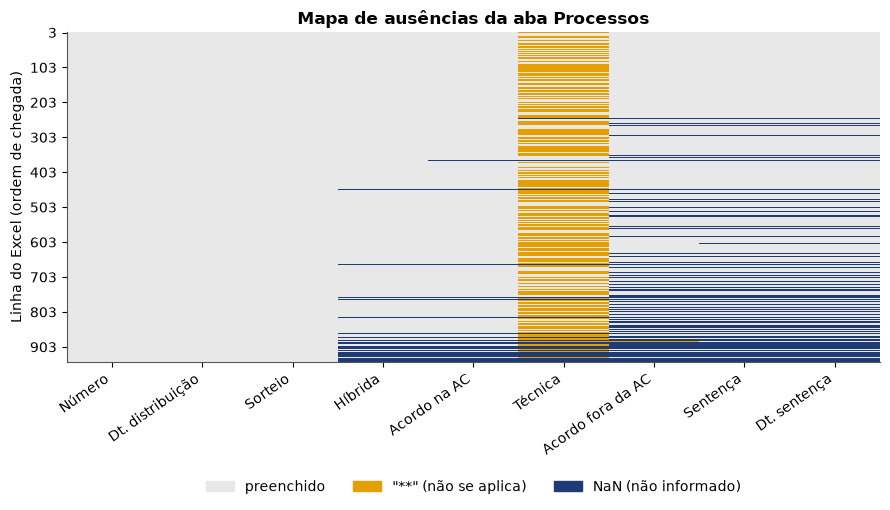

In [11]:
codigo_ausencia = pd.DataFrame({
    c: np.select([dados_brutos[c].isna(), dados_brutos[c].astype(str).eq('**')], [2, 1], 0)
    for c in COLUNAS_DIGITADAS})
fig, ax = plt.subplots(figsize=(9, 5.5))
mapa = mpl.colors.ListedColormap(['#e8e8e8', '#E69F00', '#1f3b73'])
ax.imshow(codigo_ausencia.to_numpy(), aspect='auto', cmap=mapa, interpolation='nearest', vmin=0, vmax=2)
ROTULOS_CURTOS = ['Número', 'Dt. distribuição', 'Sorteio', 'Híbrida', 'Acordo na AC', 'Técnica', 'Acordo fora da AC',
                  'Sentença', 'Dt. sentença']
ax.set_xticks(range(len(COLUNAS_DIGITADAS)), ROTULOS_CURTOS, rotation=35, ha='right')
ax.set_yticks(np.arange(0, len(codigo_ausencia), 100), dados_brutos.index[::100])
ax.set_ylabel('Linha do Excel (ordem de chegada)')
ax.grid(False)
ax.set_title('Mapa de ausências da aba Processos')
legenda = [mpl.patches.Patch(color=c, label=r) for c, r in
           zip(['#e8e8e8', '#E69F00', '#1f3b73'], ['preenchido', '"**" (não se aplica)', 'NaN (não informado)'])]
ax.legend(handles=legenda, loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=3)
plt.tight_layout()
plt.show()

**Leitura. As ausências são estruturais: dependem da etapa em que o processo está.**

- **Não há texto vazio nem espaços soltos**; as ausências são `NaN` (célula vazia) ou o marcador `**`.
- **`**` aparece em duas colunas.** Em `TÉCNICA` (515 linhas) significa que a audiência não foi realizada: todo o Controle e parte dos tratados. Em `ACORDO FORA DA AC?` aparece uma única vez (linha 888), um erro de preenchimento.
- **Os `NaN` formam blocos coerentes com a tramitação:**
  - **733 linhas completas**, todas encerradas;
  - **132 ativos** com audiência já registrada, aguardando o acordo fora e a sentença (padrão `00011`);
  - **72 linhas sem nada após o sorteio** (padrão `11111`): 71 ativos e a linha 920, recém-distribuídos, **todos dos grupos com audiência** (24 Presencial, 48 Remota, 0 Controle). No Controle não há audiência a aguardar, e a unidade já preenche `Não`/`**` na distribuição;
  - **sete linhas com padrões isolados**, listadas na tabela e tratadas nas seções 1.10 e 1.11. A mais relevante é a linha 373: um processo encerrado com a técnica em branco.
- **No mapa, os `NaN` se concentram nas últimas linhas**, as de chegada mais recente. É a assinatura de uma ausência que depende do tempo de acompanhamento, e não de um sorteio ao acaso (não é MCAR).
- **Consequência.** Nenhuma imputação é necessária nem adequada. O desfecho principal (tempo até a sentença) trata a falta de sentença como **censura**. As variáveis de processo (híbrida, técnica, acordo na AC) são analisadas onde se aplicam, com a ausência declarada, e não por exclusão silenciosa de casos incompletos, como fazem os testes do notebook do professor (E5).

---

## 1.7 Cópia de trabalho, nomes das colunas e registro de tratamentos

A partir daqui as transformações acontecem em `trab`, uma cópia de `dados_brutos` com nomes em *snake_case* (minúsculas, sem acento, válidos como identificador Python). As colunas calculadas (J a O) são mantidas na cópia apenas para conferência e descartadas no dataset final.

Cada correção, exclusão ou recodificação é anotada pela função `registrar()` num **log de tratamentos**, com a linha do Excel, o processo, a variável, o valor original, o valor novo, o problema e a justificativa. O código `A`*n* remete ao catálogo de anomalias da auditoria dos dados.

In [12]:
RENOMEAR = {
    'NÚMERO DO PROCESSO': 'numero_bruto', 'DT. DISTRIBUIÇÃO': 'dt_distribuicao', 'SORTEIO': 'sorteio',
    'HÍBRIDA': 'hibrida_bruto', 'TEVE ACORDO NA AC?': 'acordo_ac_bruto', 'TÉCNICA': 'tecnica_bruto',
    'TEVE ACORDO FORA DA AC?': 'acordo_fora_bruto', 'SENTENÇA': 'sentenca_bruto', 'DT. SENTENÇA': 'dt_sentenca',
    'DURAÇÃO-SENT2': 'xl_duracao_sent2', 'DURAÇÃO-TECN': 'xl_duracao_tecn', 'DURAÇÃO-SORT': 'xl_duracao_sort',
    'DURAÇÃO-PROC': 'xl_duracao_proc', ' DURAÇÃO DO PROCESSO': 'xl_duracao_texto', 'STATUS': 'xl_status',
}
trab = dados_brutos.rename(columns=RENOMEAR).copy()
assert set(RENOMEAR) == set(dados_brutos.columns)
assert all(c.isidentifier() and c.isascii() for c in trab.columns)

_registros = []


def registrar(linhas, variavel, valor_novo, problema, tratamento, codigo, valor_original=None):
    """Anota um tratamento para cada linha do Excel informada (valor original lido de dados_brutos)."""
    linhas = [linhas] if np.isscalar(linhas) else list(linhas)
    coluna_bruta = {v: k for k, v in RENOMEAR.items()}.get(variavel)
    for linha in linhas:
        original = valor_original
        if original is None and coluna_bruta is not None:
            original = dados_brutos.at[linha, coluna_bruta]
        _registros.append({'codigo': codigo, 'linha_excel': int(linha),
                           'processo_bruto': dados_brutos.at[linha, 'NÚMERO DO PROCESSO'],
                           'variavel': variavel, 'valor_original': repr(original) if isinstance(original, str) else str(original),
                           'valor_novo': str(valor_novo), 'problema': problema, 'tratamento': tratamento})


def log_tratamentos():
    return pd.DataFrame(_registros)


display(pd.DataFrame({'Coluna original': [repr(k) for k in RENOMEAR], 'Nome na cópia de trabalho': list(RENOMEAR.values())}))

,Coluna original,Nome na cópia de trabalho
0,'NÚMERO DO PROCESSO',numero_bruto
1,'DT. DISTRIBUIÇÃO',dt_distribuicao
2,'SORTEIO',sorteio
3,'HÍBRIDA',hibrida_bruto
4,'TEVE ACORDO NA AC?',acordo_ac_bruto
5,'TÉCNICA',tecnica_bruto
6,'TEVE ACORDO FORA DA AC?',acordo_fora_bruto
7,'SENTENÇA',sentenca_bruto
8,'DT. SENTENÇA',dt_sentenca
9,'DURAÇÃO-SENT2',xl_duracao_sent2


---

## 1.8 Número do processo (CNJ)

O número único segue a Resolução CNJ 65/2008: `NNNNNNN-DD.AAAA.J.TR.OOOO` (sequencial, dígito verificador, ano de ajuizamento, segmento da Justiça, tribunal e órgão de origem). O dígito verificador (DV) é calculado pelo **módulo 97** (ISO 7064): `DD = 98 − (NNNNNNN AAAA J TR OOOO 00 mod 97)`. Validar o DV detecta erros de digitação no número, a chave que permite cruzar a base com o PJe e o DataJud.

A limpeza tem três passos, cada um registrado:

1. remover espaços e quebras de linha nas bordas;
2. remover hífen final digitado por engano;
3. completar o órgão truncado com 3 dígitos, **somente se** o DV confirmar o órgão do estudo (5004 = 4º JEC de Natal).

In [13]:
PADRAO_CNJ = re.compile(r'^(\d{7})-(\d{2})\.(\d{4})\.(\d)\.(\d{2})\.(\d{4})$')


def dv_cnj(sequencial, ano, j, tr, orgao):
    """Dígito verificador CNJ (mod 97, ISO 7064)."""
    return 98 - int(f'{sequencial}{ano}{j}{tr}{orgao}00') % 97


def cnj_valido(numero):
    m = PADRAO_CNJ.fullmatch(str(numero))
    return bool(m) and int(m.group(2)) == dv_cnj(m.group(1), m.group(3), m.group(4), m.group(5), m.group(6))


numero = trab['numero_bruto'].astype('string')
fora = ~numero.map(lambda n: bool(PADRAO_CNJ.fullmatch(n))).astype(bool)
print('Fora do padrão antes da limpeza:', int(fora.sum()), '→ linhas', list(trab.index[fora]))
display(numero[fora].map(repr).rename('valor bruto (repr)').to_frame())

# Passo 1 — espaços e quebras de linha
passo1 = numero.str.strip()
alterado = trab.index[passo1 != numero]
registrar(alterado, 'numero_bruto', '(sem espaços)', 'Espaço ou quebra de linha no fim do número',
          'strip()', 'A7')

# Passo 2 — hífen final
passo2 = passo1.str.replace(r'\s*-\s*$', '', regex=True)
alterado = trab.index[passo2 != passo1]
registrar(alterado, 'numero_bruto', '(sem hífen final)', 'Hífen digitado após o número', 'Sufixo removido', 'A7')

# Passo 3 — órgão truncado (3 dígitos): candidatos que fecham o DV
truncado = passo2.str.match(r'^\d{7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{3}$')
candidatos = {}
for linha in trab.index[truncado]:
    seq, dv, ano, j, tr, _ = re.split(r'[-.]', passo2[linha])
    candidatos[linha] = [o for o in range(5000, 5400) if dv_cnj(seq, ano, j, tr, o) == int(dv)]
display(pd.DataFrame({'Número truncado': passo2[truncado],
                      'Órgãos 5000–5399 com DV válido': pd.Series(candidatos)}))
passo3 = passo2.copy()
for linha, lista in candidatos.items():
    assert 5004 in lista, f'linha {linha}: DV não fecha com 5004'
    passo3[linha] = passo2[linha] + '4'
registrar(list(candidatos), 'numero_bruto', '(órgão 5004)', 'Órgão de origem com 3 dígitos ("500")',
          'Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido', 'A8')

trab['processo'] = passo3
trab['cnj_corrigido'] = trab.index.isin(trab.index[(passo3 != numero.str.strip())])
partes = trab['processo'].str.extract(PADRAO_CNJ)
partes.columns = ['seq', 'dv', 'ano', 'j', 'tr', 'orgao']
trab['dv_valido'] = trab['processo'].map(cnj_valido)
trab['cnj_ano'] = partes['ano'].astype('Int64')
trab['cnj_orgao'] = partes['orgao']
print(f'Após a limpeza: {int(partes["seq"].notna().sum())} no padrão; DV válido em {int(trab["dv_valido"].sum())}; '
      f'J.TR = {sorted((partes["j"] + "." + partes["tr"]).unique())}')
assert trab['dv_valido'].all()

Fora do padrão antes da limpeza: 6 → linhas [55, 377, 443, 453, 692, 771]


,valor bruto (repr)
linha_excel,
55,'0800780-87.2026.8.20.5004-'
377,'0805750-33.2026.8.20.5004\xa0-'
443,'0806633-77.2026.8.20.500'
453,'0806739-39.2026.8.20.500'
692,'0809702-20.2026.8.20.5004 '
771,'0811548-72.2026.8.20.5004\n'


,Número truncado,Órgãos 5000–5399 com DV válido
443,0806633-77.2026.8.20.500,"[5004, 5101, 5198, 5295, 5392]"
453,0806739-39.2026.8.20.500,"[5004, 5101, 5198, 5295, 5392]"


Após a limpeza: 944 no padrão; DV válido em 944; J.TR = ['8.20']


### 1.8.1 Processos de outro órgão ou de ano anterior

O órgão `5004` é o 4º JEC de Natal e o ano esperado é 2026. Números de outro órgão ou de ano anterior indicam processos **ajuizados em outra unidade e redistribuídos** ao 4º JEC: a "data de distribuição" da planilha é a data de chegada à vara, não a do ajuizamento. Eles são mantidos (entraram no sorteio quando chegaram, e o relógio do estudo começa ali), marcados com `origem_externa` para análise de sensibilidade.

In [14]:
trab['origem_externa'] = trab['cnj_orgao'].ne('5004') | trab['cnj_ano'].lt(2026)
display(pd.crosstab([trab['cnj_ano'], trab['cnj_orgao']], trab['sorteio'], margins=True, margins_name='Total'))
registrar(trab.index[trab['origem_externa']], 'numero_bruto', 'origem_externa=True',
          'Número de outro órgão ou de ano anterior (processo redistribuído à vara)',
          'Mantido; flag origem_externa para sensibilidade', 'A9', valor_original='(órgão/ano)')
print(f'origem_externa: {int(trab["origem_externa"].sum())} linhas')

sorteio            Ac Obrigatória Presencial  Ac Remota  Rito Atual Ac Opcional  Total
cnj_ano cnj_orgao                                                                     
2023    5004                               1          0                       0      1
2025    5004                               1          0                       1      2
        5300                               0          0                       1      1
2026    5001                               1          1                       0      2
        5004                             309        312                     311    932
        5106                               1          0                       0      1
        5124                               0          1                       0      1
        5129                               0          0                       1      1
        5300                               3          0                       0      3
Total                                    316        314                     314    944

origem_externa: 12 linhas


---

## 1.9 Duplicidades e reentradas

A unidade experimental é o **processo**: cada um deve aparecer uma vez, com o grupo do seu sorteio. Depois da limpeza do número, há processos com mais de uma linha. A tabela mostra todos, para que a regra de decisão seja verificável:

In [15]:
duplicados = trab[trab['processo'].duplicated(keep=False)].sort_values(['processo', 'dt_distribuicao'])
display(duplicados[['processo', 'dt_distribuicao', 'sorteio', 'tecnica_bruto', 'sentenca_bruto', 'dt_sentenca',
                    'xl_status']])
print(f'{duplicados["processo"].nunique()} números repetidos em {len(duplicados)} linhas; '
      f'{trab["processo"].nunique()} processos distintos')

,processo,dt_distribuicao,sorteio,tecnica_bruto,sentenca_bruto,dt_sentenca,xl_status
linha_excel,,,,,,,
162,0802424-65.2026.8.20.5004,2026-02-13,Ac Obrigatória Presencial,**,Decisão,2026-02-18,Encerrado
164,0802424-65.2026.8.20.5004,2026-02-13,Ac Obrigatória Presencial,NaN,NaN,NaT,Ativo
290,0804436-52.2026.8.20.5004,2026-03-18,Ac Obrigatória Presencial,**,Decisão,2026-03-18,Encerrado
322,0804436-52.2026.8.20.5004,2026-03-24,Ac Obrigatória Presencial,**,Decisão,2026-04-09,Encerrado
475,0804436-52.2026.8.20.5004,2026-04-27,Rito Atual Ac Opcional,**,Decisão,2026-04-27,Encerrado
591,0808905-44.2026.8.20.5004,2026-05-20,Ac Remota,**,Decisão,2026-05-21,Encerrado
607,0808905-44.2026.8.20.5004,2026-05-22,Ac Remota,**,NaN,NaT,Ativo
819,0812314-28.2026.8.20.5004,2026-07-08,Ac Remota,NaN,NaN,NaT,Ativo
822,0812314-28.2026.8.20.5004,2026-07-08,Ac Remota,**,Extinção do Feito com Homologação do Acordo,2026-09-16,Encerrado


5 números repetidos em 11 linhas; 938 processos distintos


Há duas situações diferentes:

- **Duplicata de registro** (A3, A4): a segunda linha é uma cópia vazia ou desatualizada do mesmo processo, no mesmo grupo. Mantê-la criaria um **falso censurado** (por exemplo, a linha 164 ficaria "ativa" por 236 dias, embora o processo tenha sido redistribuído em 5 dias). → excluir a cópia e manter o registro mais antigo/completo.
- **Reentrada após `Decisão`** (A5): o processo saiu por redistribuição, voltou à vara e foi **sorteado de novo**; o `0804436-52` passou de Presencial para Controle. Reentradas violam a unicidade da unidade experimental e contaminam os grupos (E3). → na base primária, por **intenção de tratar**, vale só o **primeiro episódio**, com o grupo do primeiro sorteio. As alternativas (excluir o processo; unir os episódios) ficam para a análise de sensibilidade, a partir do arquivo com todas as linhas.

In [16]:
EXCLUIR_PRIMARIA = {
    164: ('A3', 'Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)'),
    819: ('A3', 'Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho'),
    857: ('A4', 'Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo'),
    322: ('A5', 'Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado'),
    475: ('A5', 'Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo'),
    607: ('A5', 'Reentrada de 0808905-44 um dia após a Decisão; re-sorteado'),
}
# Conferência: toda linha excluída tem o mesmo número que uma linha mantida, e esta é anterior ou igual na data
for linha, (codigo, motivo) in EXCLUIR_PRIMARIA.items():
    mesmos = trab.index[trab['processo'].eq(trab.at[linha, 'processo'])]
    mantidas = [m for m in mesmos if m not in EXCLUIR_PRIMARIA]
    assert len(mantidas) == 1 and trab.at[mantidas[0], 'dt_distribuicao'] <= trab.at[linha, 'dt_distribuicao']
    registrar(linha, 'processo', 'excluída da base primária', motivo,
              f'Excluída; mantida a linha {mantidas[0]} (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)',
              codigo, valor_original=trab.at[linha, 'processo'])

trab['base_primaria'] = ~trab.index.isin(list(EXCLUIR_PRIMARIA))
trab['motivo_exclusao'] = pd.Series({k: f'{v[0]}: {v[1]}' for k, v in EXCLUIR_PRIMARIA.items()},
                                    dtype='string').reindex(trab.index)
trab['duplicado_removido'] = trab['processo'].duplicated(keep=False) & trab['base_primaria']
trab['reentrada'] = trab['processo'].duplicated(keep='first')  # 2º episódio em diante (inclui duplicatas)
assert not trab.loc[trab['base_primaria'], 'processo'].duplicated().any()
print('Base primária:', int(trab['base_primaria'].sum()), 'processos')
display(pd.crosstab(trab['sorteio'], trab['base_primaria'].map({True: 'mantidas', False: 'excluídas'}),
                    margins=True, margins_name='Total'))

Base primária: 938 processos


base_primaria,excluídas,mantidas,Total
sorteio,,,
Ac Obrigatória Presencial,2,314,316
Ac Remota,3,311,314
Rito Atual Ac Opcional,1,313,314
Total,6,938,944


**Leitura.**

- **São 5 números repetidos em 11 linhas**, ou seja, 6 linhas a mais que processos. O notebook do professor contou essas 6 linhas extras como "6 duplicatas" e não as tratou (E3).
- **Três são duplicatas de registro** (linhas 164, 819 e 857): cópias vazias ou desatualizadas do mesmo processo, no mesmo grupo. A linha 164, por exemplo, ficaria "em tramitação" por 236 dias, quando o processo foi redistribuído 5 dias depois de chegar (linha 162).
- **Três são reentradas re-sorteadas** (linhas 322, 475 e 607):
  - o processo `0804436-52` saiu por `Decisão` em 18/03, voltou em 24/03 (Presencial, nova Decisão em 09/04) e voltou de novo em 27/04, quando foi sorteado para o **Controle** (nova Decisão no mesmo dia);
  - o `0808905-44` foi redistribuído em 21/05 e voltou no dia 22/05, sorteado de novo.
- **Lição de desenho.** Um processo que sai e volta não deveria passar por novo sorteio: deveria herdar o grupo original.
- **Base primária: 938 processos** (Controle 313, Presencial 314, Remota 311), cada um com o grupo do primeiro sorteio (intenção de tratar). As 944 linhas ficam preservadas em `ed2_todas_linhas.pkl` para as análises de sensibilidade.

---

## 1.10 Categorias: grafia, partições e recodificações

### 1.10.1 Funções de normalização

Uma variável categórica bem construída é uma **partição** dos casos: exaustiva, disjunta, sem classes vazias e sem sinônimos (a mesma categoria com duas grafias). Três funções garantem isso:

- `limpar_texto` colapsa espaços e quebras de linha e converte texto vazio em `<NA>`;
- `normalizar_chave` gera uma chave de comparação sem acento, em maiúsculas e com espaços simples; duas grafias com a mesma chave são **sinônimos**;
- `para_categoria` aplica um **mapa explícito** (valor original → rótulo) e recusa valores não previstos; `verificar_particao` confere as propriedades com `assert`, de modo que um erro interrompe a execução em vez de passar despercebido.

In [17]:
def limpar_texto(serie):
    """Colapsa espaços/quebras de linha e converte vazio em NA (dtype string)."""
    return serie.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip().replace('', pd.NA)


def normalizar_chave(texto):
    """Chave de comparação: sem acentos, maiúscula, espaços simples (não altera o dado)."""
    if pd.isna(texto):
        return pd.NA
    texto = unicodedata.normalize('NFKD', str(texto))
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r'\s+', ' ', texto).strip().upper()


def para_categoria(serie, mapa, ordem, ordenada=False):
    """Aplica um mapa exaustivo (valor original → rótulo) e devolve dtype category."""
    sem_mapa = sorted(set(serie.dropna().unique()) - set(mapa))
    assert not sem_mapa, f'Valores sem mapeamento: {sem_mapa}'
    rotulos = serie.map(mapa)
    assert set(rotulos.dropna()) <= set(ordem), 'Há rótulos fora da lista de categorias'
    return pd.Series(pd.Categorical(rotulos, categories=ordem, ordered=ordenada), index=serie.index, name=serie.name)


resumo_particoes = []


def verificar_particao(nova, nome, ausentes_permitidos=0):
    """Confere se uma variável category é partição: exaustiva, sem vazias e sem sinônimos."""
    contagem = nova.value_counts(sort=False, dropna=True)
    chaves = pd.Series(contagem.index.astype(str)).map(normalizar_chave)
    resultado = {'Variável': nome, 'Categorias': len(contagem), 'Vazias': int((contagem == 0).sum()),
                 'NA': int(nova.isna().sum()), 'Sinônimos': int(chaves.duplicated().sum()),
                 'Soma = n': int(contagem.sum() + nova.isna().sum()) == len(nova)}
    resultado['Partição válida'] = (resultado['Vazias'] == 0 and resultado['Sinônimos'] == 0
                                    and resultado['NA'] <= ausentes_permitidos and resultado['Soma = n'])
    assert resultado['Partição válida'], f'{nome} não é partição: {resultado}'
    resumo_particoes.append(resultado)
    return contagem


COLUNAS_TEXTO = ['sorteio', 'hibrida_bruto', 'acordo_ac_bruto', 'tecnica_bruto', 'acordo_fora_bruto', 'sentenca_bruto']
diagnostico = []
for c in COLUNAS_TEXTO:
    original = trab[c].astype('string')
    limpo = limpar_texto(trab[c])
    chaves = original.dropna().map(normalizar_chave)
    diagnostico.append({'Variável': c, 'Valores alterados pela limpeza': int((original != limpo).sum()),
                        'Grafias distintas': original.nunique(), 'Chaves distintas': chaves.nunique()})
    trab[c] = limpo
display(pd.DataFrame(diagnostico))

,Variável,Valores alterados pela limpeza,Grafias distintas,Chaves distintas
0,sorteio,0,3,3
1,hibrida_bruto,0,2,2
2,acordo_ac_bruto,0,2,2
3,tecnica_bruto,0,7,7
4,acordo_fora_bruto,0,3,3
5,sentenca_bruto,0,5,4


### 1.10.2 Tipo de sentença: uma variante de caixa e o significado de "Decisão"

`SENTENÇA` tem cinco grafias, mas só quatro chaves: `Extinção do feito sem julgamento de mérito` (minúsculas, 11 casos de janeiro) é a mesma categoria que `Extinção do Feito sem Julgamento de Mérito`. A validação de lista do Excel não distingue maiúsculas, por isso a variante passou.

`Decisão` **não é sentença**. Segundo o pesquisador, é a decisão que remete o processo para redistribuição a outro juízo, por prevenção: o processo **sai da vara** e o seu desfecho deixa de ser observado. Contá-la como sentença, como faz o notebook do professor (E10), encurta artificialmente o tempo dos grupos. Aqui ela vira o desfecho `Redistribuição`, tratado como censura na análise principal e como risco competitivo na complementar (Parte IV).

In [18]:
display(trab['sentenca_bruto'].value_counts(dropna=False).rename_axis('Grafia').to_frame('Linhas')
        .assign(Chave=lambda t: t.index.map(normalizar_chave)))

MAPA_SENTENCA = {
    'Extinção do Feito com Homologação do Acordo': 'Homologação',
    'Extinção do Feito com Julgamento de Mérito': 'Mérito',
    'Extinção do Feito sem Julgamento de Mérito': 'Sem mérito',
    'Extinção do feito sem julgamento de mérito': 'Sem mérito',
    'Decisão': 'Redistribuição',
}
variante = trab['sentenca_bruto'].eq('Extinção do feito sem julgamento de mérito').fillna(False)
registrar(trab.index[variante], 'sentenca_bruto', 'Sem mérito', 'Variante de caixa (minúsculas)',
          'Recodificada para a forma canônica', 'A6')
decisao = trab['sentenca_bruto'].eq('Decisão').fillna(False)
registrar(trab.index[decisao], 'sentenca_bruto', 'Redistribuição',
          '"Decisão" = remessa para redistribuição por prevenção (não é sentença)',
          'Desfecho Redistribuição; evento=0 (censura) e evento_cr=2 (risco competitivo)', 'A-Dec')

desfecho = trab['sentenca_bruto'].map(MAPA_SENTENCA).where(trab['sentenca_bruto'].notna(), 'Ativo')
trab['tipo_desfecho'] = para_categoria(desfecho, {v: v for v in ORDEM_DESFECHO}, ORDEM_DESFECHO)
display(pd.crosstab(trab['sentenca_bruto'].fillna('(vazio)'), trab['tipo_desfecho']))

,Linhas,Chave
Grafia,,
Extinção do Feito com Julgamento de Mérito,341,EXTINCAO DO FEITO COM JULGAMENTO DE MERITO
Extinção do Feito sem Julgamento de Mérito,275,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO
<NA>,210,<NA>
Extinção do Feito com Homologação do Acordo,81,EXTINCAO DO FEITO COM HOMOLOGACAO DO ACORDO
Decisão,26,DECISAO
Extinção do feito sem julgamento de mérito,11,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO


tipo_desfecho,Homologação,Mérito,Sem mérito,Redistribuição,Ativo
sentenca_bruto,,,,,
(vazio),0,0,0,0,210
Decisão,0,0,0,26,0
Extinção do Feito com Homologação do Acordo,81,0,0,0,0
Extinção do Feito com Julgamento de Mérito,0,341,0,0,0
Extinção do Feito sem Julgamento de Mérito,0,0,275,0,0
Extinção do feito sem julgamento de mérito,0,0,11,0,0


### 1.10.3 Grupo sorteado

Os rótulos longos da planilha passam a códigos curtos (`Controle`, `Presencial`, `Remota`), com `Controle` como **categoria de referência** (primeira posição). O rótulo descritivo fica em `grupo_rotulo`, para tabelas e legendas.

In [19]:
MAPA_GRUPO = {'Rito Atual Ac Opcional': 'Controle', 'Ac Obrigatória Presencial': 'Presencial', 'Ac Remota': 'Remota'}
trab['grupo'] = para_categoria(trab['sorteio'], MAPA_GRUPO, ORDEM_GRUPO)
trab['grupo_rotulo'] = para_categoria(trab['grupo'].astype('string'), ROTULO_GRUPO, list(ROTULO_GRUPO.values()))
display(pd.crosstab(trab['sorteio'], trab['grupo']))

grupo,Controle,Presencial,Remota
sorteio,,,
Ac Obrigatória Presencial,0,316,0
Ac Remota,0,0,314
Rito Atual Ac Opcional,314,0,0


### 1.10.4 Respostas Sim/Não, o `**` em "acordo fora" e a técnica

- **`HÍBRIDA`, `TEVE ACORDO NA AC?`, `TEVE ACORDO FORA DA AC?`** → `boolean` (`Sim` = True, `Não` = False, `NaN` = `<NA>`).
- **`**` em "acordo fora" (linha 888, A10):** processo extinto sem mérito em 8 dias, sem homologação → `False`.
- **`TÉCNICA`:** `**` significa que a AC **não foi realizada** (todo o Controle e parte dos tratados); vira `ac_realizada = False` e `tecnica = <NA>`. `NaN` significa "ainda não informado" (processos ativos sem audiência) → `ac_realizada = <NA>`. Essa separação é a que o notebook do professor não fez (E4).
- **Linha 373 (A11):** processo Presencial **encerrado** sem mérito em 1 dia, com técnica vazia; não houve AC → `**`.
- **Linha 249 (A14):** processo Remota ativo com "acordo na AC = Não" e técnica vazia; mantido `<NA>` (não se imputa).

In [20]:
SIM_NAO = {'Sim': True, 'Não': False}
for bruto, novo in [('hibrida_bruto', 'hibrida'), ('acordo_ac_bruto', 'acordo_ac'), ('acordo_fora_bruto', 'acordo_fora')]:
    valores = trab[bruto]
    if bruto == 'acordo_fora_bruto':
        estrela = valores.eq('**').fillna(False)
        registrar(trab.index[estrela], bruto, False, '"**" em acordo fora da AC (desfecho sem mérito, sem homologação)',
                  'Recodificado para Não (False)', 'A10')
        valores = valores.mask(estrela, 'Não')
    assert set(valores.dropna().unique()) <= set(SIM_NAO), (bruto, valores.unique())
    trab[novo] = valores.map(SIM_NAO).astype('boolean')

tecnica = trab['tecnica_bruto'].copy()
linha_373 = trab.index[tecnica.isna() & trab['tipo_desfecho'].ne('Ativo')]
assert list(linha_373) == [373]
registrar(linha_373, 'tecnica_bruto', '**', 'Técnica vazia em processo encerrado (sem mérito em 1 dia)',
          'Recodificada para "**" (AC não realizada)', 'A11')
tecnica[linha_373] = '**'
registrar(249, 'tecnica_bruto', '<NA>', 'Processo ativo com acordo na AC = Não e técnica vazia',
          'Mantido NA (não imputado)', 'A14')

trab['ac_realizada'] = pd.Series(np.where(tecnica.isna(), pd.NA, tecnica.ne('**')), index=trab.index).astype('boolean')
ORDEM_TECNICA = ['Desconstrução da Verdade', 'Parafraseamento', 'Separação de Pessoas e Problemas',
                 'Padrões Objetivos', 'Teoria do Afago ou do Reforço Positivo',
                 'Análise da Comunicação Verbal e Não-Verbal das Partes']
CURTA_TECNICA = dict(zip(ORDEM_TECNICA, ['Desconstrução', 'Parafraseamento', 'Separação', 'Padrões objetivos',
                                         'Afago', 'Comunicação']))
trab['tecnica'] = para_categoria(tecnica.where(tecnica.ne('**')), {t: t for t in ORDEM_TECNICA}, ORDEM_TECNICA)
trab['tecnica_curta'] = para_categoria(trab['tecnica'].astype('string'), CURTA_TECNICA, list(CURTA_TECNICA.values()))

# Acordo em qualquer momento: lógica de Kleene (True se houve algum; False só se ambos False)
trab['acordo'] = trab['acordo_ac'] | trab['acordo_fora']

display(pd.crosstab(trab['tecnica_bruto'].fillna('(NaN)'), trab['ac_realizada'].astype('string').fillna('<NA>'),
                    margins=True, margins_name='Total'))
display(pd.crosstab([trab['acordo_ac'].astype('string').fillna('<NA>'), trab['acordo_fora'].astype('string').fillna('<NA>')],
                    trab['tipo_desfecho']))

ac_realizada,<NA>,False,True,Total
tecnica_bruto,,,,
(NaN),76,1,0,77
**,0,515,0,515
Análise da Comunicação Verbal e Não-Verbal das Partes,0,0,63,63
Desconstrução da Verdade,0,0,47,47
Padrões Objetivos,0,0,67,67
Parafraseamento,0,0,57,57
Separação de Pessoas e Problemas,0,0,60,60
Teoria do Afago ou do Reforço Positivo,0,0,58,58
Total,76,516,352,944


tipo_desfecho          Homologação  Mérito  Sem mérito  Redistribuição  Ativo
acordo_ac acordo_fora                                                        
<NA>      <NA>                   0       0           0               0     75
False     <NA>                   0       0           0               0    133
          False                  0     341         286              26      2
          True                  64       0           0               0      0
True      False                 17       0           0               0      0

**Leitura.**

- **Uma só variante de grafia.** Nas seis colunas categóricas, a limpeza de espaços não alterou nenhum valor, e só `SENTENÇA` tem duas grafias para a mesma chave: 11 sentenças de janeiro escritas em minúsculas, unificadas na categoria `Sem mérito` (275 + 11 = **286**). As demais (grupo, híbrida, acordos, técnica) não têm sinônimos.
- **Desfechos nas 944 linhas:** 341 de mérito, 286 sem mérito, 81 homologações de acordo, 26 redistribuições (`Decisão`) e 210 sem desfecho.
- **Técnica e audiência.** 352 linhas têm técnica registrada (AC realizada), 516 têm `**` (as 515 originais mais a linha 373) e 76 seguem `<NA>`, por não haver ainda informação. As seis técnicas aparecem entre 47 (Desconstrução) e 67 (Padrões objetivos) vezes; o "53,85% de padrões objetivos" do resumo expandido não se reproduz nesta versão dos dados.
- **Acordo e sentença são perfeitamente coerentes.** As 81 homologações correspondem exatamente a 17 acordos na AC e 64 fora dela. Não há acordo marcado sem homologação, nem homologação sem acordo, nem acordo nos dois momentos. Por isso `acordo` (qualquer momento) é igual a "sentença homologatória" sempre que é conhecido.
- **`<NA>` nos acordos só ocorre em processos ativos:** 75 sem nenhuma das duas respostas e 133 com "Não" na AC e o acordo fora ainda em aberto. Para um processo em tramitação, "ainda não houve acordo" não é "não houve acordo", e a variável não é preenchida com `False`.

---

## 1.11 Desvios de protocolo e coerência do desenho

O protocolo define o que é possível em cada grupo. Três verificações:

- **Controle sem audiência (A18):** o grupo de rito atual não deveria ter AC, técnica nem acordo na AC. Se isso se confirma, o contraste real do experimento é "**com AC obrigatória × sem AC**".
- **Híbrida na Remota (A12):** por definição do pesquisador, a híbrida é uma AC *presencial* em que uma parte participou à distância (Res. CNJ 481). Uma híbrida no grupo Remota é incongruente.
- **Híbrida sem AC (A13):** marcar "híbrida = Sim" pressupõe que a audiência ocorreu; com técnica `**`, há contradição.

Os casos são **mantidos no grupo sorteado** (análise por intenção de tratar, ITT) e marcados com `desvio_protocolo` para a análise "conforme tratado". A variável `hibrida` é, ela mesma, **pós-sorteio** (decorre do pedido da parte): é adesão parcial ao rito presencial, não um quarto grupo aleatorizado (E11).

In [21]:
coerencia_grupo = pd.DataFrame({
    'AC realizada': trab.groupby('grupo', observed=True)['ac_realizada'].sum(),
    'Técnica registrada': trab.groupby('grupo', observed=True)['tecnica'].count(),
    'Acordo na AC': trab.groupby('grupo', observed=True)['acordo_ac'].sum(),
    'Acordo fora da AC': trab.groupby('grupo', observed=True)['acordo_fora'].sum(),
    'Híbrida = Sim': trab.groupby('grupo', observed=True)['hibrida'].sum(),
    'Linhas': trab.groupby('grupo', observed=True).size(),
})
display(coerencia_grupo)
assert coerencia_grupo.loc['Controle', ['AC realizada', 'Técnica registrada', 'Acordo na AC', 'Híbrida = Sim']].eq(0).all()

trab['hibrida_remota'] = (trab['hibrida'].fillna(False) & trab['grupo'].eq('Remota')).astype(bool)
trab['hibrida_sem_ac'] = (trab['hibrida'].fillna(False) & trab['ac_realizada'].eq(False).fillna(False)).astype(bool)
trab['desvio_protocolo'] = trab['hibrida_remota'] | trab['hibrida_sem_ac']
registrar(trab.index[trab['hibrida_remota']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Audiência híbrida no grupo Remota (protocolo prevê híbrida só na presencial)',
          'Mantido no grupo sorteado (ITT); flag hibrida_remota', 'A12')
registrar(trab.index[trab['hibrida_sem_ac']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Híbrida = Sim com técnica "**" (AC não realizada): contraditório',
          'Mantido; flag hibrida_sem_ac; consultar a pesquisadora', 'A13')
display(trab.loc[trab['desvio_protocolo'], ['processo', 'grupo', 'hibrida', 'tecnica_bruto', 'tipo_desfecho',
                                            'hibrida_remota', 'hibrida_sem_ac']])

,AC realizada,Técnica registrada,Acordo na AC,Acordo fora da AC,Híbrida = Sim,Linhas
grupo,,,,,,
Controle,0,0,0,21,0,314
Presencial,178,178,9,16,28,316
Remota,174,174,8,27,3,314


,processo,grupo,hibrida,tecnica_bruto,tipo_desfecho,hibrida_remota,hibrida_sem_ac
linha_excel,,,,,,,
318,0804822-82.2026.8.20.5004,Remota,True,Separação de Pessoas e Problemas,Mérito,True,False
433,0806545-39.2026.8.20.5004,Presencial,True,**,Sem mérito,False,True
455,0806829-47.2026.8.20.5004,Presencial,True,**,Homologação,False,True
456,0806797-42.2026.8.20.5004,Remota,True,Teoria do Afago ou do Reforço Positivo,Ativo,True,False
712,0810564-88.2026.8.20.5004,Presencial,True,**,Sem mérito,False,True
832,0812493-59.2026.8.20.5004,Remota,True,<NA>,Ativo,True,False


### 1.11.1 As redistribuições (`Decisão`)

Quando ocorrem as redistribuições? Se quase todas acontecem nos primeiros dias, antes de qualquer audiência, o processo saiu do estudo antes de poder receber o tratamento.

In [22]:
redist = trab[trab['tipo_desfecho'].eq('Redistribuição')].copy()
redist['dias'] = (redist['dt_sentenca'] - redist['dt_distribuicao']).dt.days
print(f'{len(redist)} redistribuições (todas as linhas); na base primária: {int(redist["base_primaria"].sum())}')
display(redist.groupby('grupo', observed=True)['dias'].describe()[['count', 'min', '50%', 'mean', 'max']])
display(redist.loc[redist['ac_realizada'].fillna(False), ['processo', 'grupo', 'tecnica', 'dias']]
        .rename(columns={'dias': 'dias até a Decisão'}))

26 redistribuições (todas as linhas); na base primária: 24


,count,min,50%,mean,max
grupo,,,,,
Controle,6.0,0.0,1.0,4.166667,20.0
Presencial,11.0,0.0,1.0,3.000000,16.0
Remota,9.0,1.0,8.0,25.444444,84.0


,processo,grupo,tecnica,dias até a Decisão
linha_excel,,,,
395,0805907-06.2026.8.20.5004,Remota,Teoria do Afago ou do Reforço Positivo,84
571,0808552-04.2026.8.20.5004,Remota,Padrões Objetivos,74


**Leitura.**

- **O Controle não teve nenhuma audiência.** São 0 audiências, 0 técnicas, 0 acordos na AC e 0 híbridas em 314 processos. O contraste real do experimento é, portanto, "**AC obrigatória × nenhuma AC**", e não "AC obrigatória × AC opcional". O acordo fora da audiência existe nos três grupos (21 no Controle, 16 na Presencial, 27 na Remota) e é o único desfecho de acordo comparável entre os três.
- **Nem todo tratado teve audiência.** Só 178 dos 316 processos da Presencial (56%) e 174 dos 314 da Remota (55%) têm técnica registrada. Os demais foram extintos antes da audiência (`**`) ou ainda a aguardam (`<NA>`). A análise por intenção de tratar (ITT) compara os **grupos sorteados**, não "quem teve audiência", para não quebrar a aleatorização.
- **Desvios de protocolo em 6 processos, todos mantidos no grupo sorteado e sinalizados:**
  - 3 híbridas no grupo **Remota** (linhas 318, 456 e 832), quando a híbrida, por definição, é uma variação da audiência presencial;
  - 3 híbridas na Presencial com técnica `**` (linhas 433, 455 e 712), o que é contraditório. Uma delas (455) terminou em homologação.
- **A híbrida é adesão parcial, não tratamento.** Ela ocorreu em 28 processos da Presencial, a pedido da parte, e não foi sorteada. Uma comparação "híbrida × presencial" é observacional.
- **As redistribuições são quase sempre imediatas.** A mediana é de 1 dia no Controle e na Presencial e de 8 dias na Remota. Só 2 ocorreram depois da audiência: as linhas 395 (84 dias) e 571 (74 dias), ambas da Remota, que puxam a média desse grupo para 25,4 dias. Em geral, o processo sai da vara antes que o tratamento possa agir, e por isso a `Decisão` é censura ou risco competitivo, nunca sentença (E10).

---

## 1.12 O dataset *tidy*: tempo, evento e variáveis derivadas

### 1.12.1 Tempo e evento

A análise de sobrevivência precisa de dois números por processo:

- **`tempo`** — dias corridos da distribuição até o desfecho (`dt_sentenca`), ou até a **data de corte** (07/10/2026) se não houve desfecho. É recalculado pelas datas; as colunas de duração do Excel não são usadas (A1, A17);
- **`evento`** — `1` se o processo foi **sentenciado** (mérito, sem mérito ou homologação de acordo); `0` se está **censurado**: em tramitação na data de corte ou **redistribuído** (sai da vara no dia da Decisão, sem sentença observada).

Duas codificações complementares:

- **`evento_cr`** (riscos competitivos): `0` = censurado (ativo), `1` = sentença, `2` = redistribuição;
- **`causa`** (desfecho específico): `0` = censurado, `1` = homologação, `2` = mérito, `3` = sem mérito, `4` = redistribuição. Permite estudar, por exemplo, o tempo até a homologação de acordo, que é onde a conciliação atua diretamente.

Há processos com tempo **zero** (desfecho no próprio dia da distribuição). Kaplan-Meier e Cox os aceitam; os modelos paramétricos (AFT) exigem tempo positivo, por isso `tempo_pos` substitui 0 por 0,5 dia (convenção documentada, não imputação; A15).

O **acompanhamento** (`followup`) é o tempo entre a distribuição e a data de corte: o máximo que cada processo poderia ser observado. Como a entrada é escalonada (janeiro a agosto), o acompanhamento varia de 65 a 279 dias, e é por isso que a média simples dos tempos, sem tratar a censura, não é um estimador válido (E7, E14).

In [23]:
CODIGO_CAUSA = {'Ativo': 0, 'Homologação': 1, 'Mérito': 2, 'Sem mérito': 3, 'Redistribuição': 4}
CODIGO_CR = {'Ativo': 0, 'Homologação': 1, 'Mérito': 1, 'Sem mérito': 1, 'Redistribuição': 2}
SENTENCAS = ['Homologação', 'Mérito', 'Sem mérito']

fim = trab['dt_sentenca'].fillna(DATA_CORTE)
trab['tempo'] = (fim - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_pos'] = trab['tempo'].astype('float64').mask(trab['tempo'].eq(0), 0.5)
trab['evento'] = trab['tipo_desfecho'].isin(SENTENCAS).astype('Int64')
trab['evento_cr'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CR).astype('Int64')
trab['causa'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CAUSA).astype('Int64')
trab['encerrado'] = trab['dt_sentenca'].notna().astype('boolean')
trab['followup'] = (DATA_CORTE - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_zero'] = trab['tempo'].eq(0).astype('boolean')
trab['sem_formula_excel'] = trab['xl_duracao_proc'].isna().astype('boolean')

registrar(trab.index[trab['tipo_desfecho'].eq('Ativo')], 'xl_duracao_proc', 'tempo = 07/10/2026 − distribuição',
          'Duração dos ativos calculada com TODAY() (volátil)', 'Censurado em DATA_CORTE fixa; evento=0', 'A1')
registrar(trab.index[trab['sem_formula_excel']], 'xl_duracao_proc', 'tempo = 70; evento = 0',
          'Linha sem nenhuma fórmula (STATUS vazio)', 'Mantida: ativo censurado em 07/10/2026 (data de distribuição válida)', 'A2')
registrar(trab.index[trab['tempo_zero']], 'tempo', 'tempo=0; tempo_pos=0,5',
          'Desfecho no próprio dia da distribuição', 'Mantido; tempo_pos=0,5 só para modelos paramétricos', 'A15',
          valor_original='0')

# Conferência com a coluna DURAÇÃO-PROC do Excel (valores em cache)
confere = trab['tempo'].astype('float64').eq(trab['xl_duracao_proc'])
print(f'tempo recalculado = DURAÇÃO-PROC do Excel em {int(confere.sum())} de {len(trab)} linhas; '
      f'divergentes: {list(trab.index[~confere])} (sem fórmula no Excel)')

tempo recalculado = DURAÇÃO-PROC do Excel em 943 de 944 linhas; divergentes: [920] (sem fórmula no Excel)


### 1.12.2 Variáveis de calendário e ordem de chegada

Segundo o pesquisador, o sorteio "seguiu rigorosamente a ordem de chegada" dos processos, e as linhas da planilha estão nessa ordem (a data de distribuição nunca decresce de uma linha para a seguinte). Derivam-se:

- **`ordem_chegada`** — posição do processo na sequência de chegada da base primária (1 = primeiro); variável **ordinal**, usada na questão 2.7;
- **`dia_estudo`** — dias desde 01/01/2026 (tempo de calendário da entrada, quantitativo);
- **`mes_distribuicao`** — mês de entrada (ordinal); como a censura depende do mês de entrada, é a covariável natural de estratificação;
- **`ciclo`** — os "dois ciclos" do resumo expandido: 01/01–28/04 e 29/04–03/08/2026;
- **`dia_semana_distribuicao`** e **`sentenca_fim_semana`** — sentenças em sábado ou domingo sugerem que a data registrada pode ser a de **lançamento** no sistema (ou de mutirão), não a da assinatura (A16).

In [24]:
assert trab['dt_distribuicao'].is_monotonic_increasing, 'linhas fora da ordem cronológica'
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
MESES = {1: 'jan', 2: 'fev', 3: 'mar', 4: 'abr', 5: 'mai', 6: 'jun', 7: 'jul', 8: 'ago'}

trab['dia_estudo'] = (trab['dt_distribuicao'] - DATA_INICIO).dt.days.astype('Int64')
trab['mes_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.month.map(MESES),
                                          categories=list(MESES.values()), ordered=True)
trab['ciclo'] = pd.Categorical(np.where(trab['dt_distribuicao'] <= pd.Timestamp('2026-04-28'), '1º ciclo', '2º ciclo'),
                               categories=['1º ciclo', '2º ciclo'], ordered=True)
trab['dia_semana_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.dayofweek.map(dict(enumerate(DIAS))),
                                                 categories=DIAS, ordered=True)
trab['sentenca_fim_semana'] = pd.Series(pd.NA, index=trab.index, dtype='boolean')
tem_data = trab['dt_sentenca'].notna()
trab.loc[tem_data, 'sentenca_fim_semana'] = trab.loc[tem_data, 'dt_sentenca'].dt.dayofweek.ge(5)
registrar(trab.index[trab['sentenca_fim_semana'].fillna(False)], 'dt_sentenca', '(mantida)',
          'Sentença datada em sábado ou domingo (possível data de lançamento/lote)',
          'Mantida; flag sentenca_fim_semana; limitação a validar no DataJud', 'A16', valor_original='(fim de semana)')

trab['ordem_chegada'] = pd.Series(pd.NA, index=trab.index, dtype='Int64')
trab.loc[trab['base_primaria'], 'ordem_chegada'] = np.arange(1, int(trab['base_primaria'].sum()) + 1)
print('Sentenças em fim de semana:', int(trab['sentenca_fim_semana'].sum()), 'de', int(tem_data.sum()))
display(trab.loc[tem_data].groupby(trab['dt_sentenca'].dt.dayofweek.map(dict(enumerate(DIAS))))
        .size().reindex(DIAS).rename('Sentenças').to_frame().T)

Sentenças em fim de semana: 135 de 734


dt_sentenca,seg,ter,qua,qui,sex,sáb,dom
Sentenças,91,186,149,85,88,70,65


### 1.12.3 Montagem e tipos finais

O dataset final tem uma linha por processo e as colunas na ordem: identificação → calendário → tratamento → processo (audiência, acordo) → desfecho e tempo → *flags* de qualidade. São produzidos dois objetos:

- **`dados_todas`** — as 944 linhas, com `base_primaria` e `motivo_exclusao` (para as análises de sensibilidade);
- **`dados`** — a **base primária** (`base_primaria == True`), usada em todo o restante do notebook.

In [25]:
COLUNAS_TIDY = [
    'processo', 'linha_excel', 'ordem_chegada',
    'dt_distribuicao', 'dia_estudo', 'mes_distribuicao', 'ciclo', 'dia_semana_distribuicao',
    'grupo', 'grupo_rotulo',
    'ac_realizada', 'tecnica', 'tecnica_curta', 'hibrida', 'acordo_ac', 'acordo_fora', 'acordo',
    'tipo_desfecho', 'dt_sentenca', 'encerrado', 'tempo', 'tempo_pos', 'evento', 'evento_cr', 'causa', 'followup',
    'cnj_ano', 'cnj_orgao', 'cnj_corrigido', 'origem_externa', 'duplicado_removido', 'sem_formula_excel',
    'sentenca_fim_semana', 'tempo_zero', 'hibrida_remota', 'hibrida_sem_ac', 'desvio_protocolo',
]
dados_todas = trab.reset_index()[COLUNAS_TIDY + ['base_primaria', 'motivo_exclusao', 'reentrada']].copy()
TIPOS = {
    'processo': 'string', 'linha_excel': 'Int64', 'dt_distribuicao': 'datetime64[ns]',
    'dt_sentenca': 'datetime64[ns]', 'cnj_orgao': 'category',
    'cnj_corrigido': 'boolean', 'origem_externa': 'boolean', 'duplicado_removido': 'boolean',
    'hibrida_remota': 'boolean', 'hibrida_sem_ac': 'boolean', 'desvio_protocolo': 'boolean',
    'base_primaria': 'boolean', 'reentrada': 'boolean', 'motivo_exclusao': 'string',
}
dados_todas = dados_todas.astype(TIPOS)
dados = dados_todas.loc[dados_todas['base_primaria'], COLUNAS_TIDY].reset_index(drop=True)

print(f'dados_todas: {dados_todas.shape} | dados (base primária): {dados.shape}')
display(dados.dtypes.astype(str).rename('dtype').to_frame().T)
display(dados.head(5))

dados_todas: (944, 40) | dados (base primária): (938, 37)


,processo,linha_excel,ordem_chegada,dt_distribuicao,dia_estudo,mes_distribuicao,ciclo,dia_semana_distribuicao,grupo,grupo_rotulo,ac_realizada,tecnica,tecnica_curta,hibrida,acordo_ac,acordo_fora,acordo,tipo_desfecho,dt_sentenca,encerrado,tempo,tempo_pos,evento,evento_cr,causa,followup,cnj_ano,cnj_orgao,cnj_corrigido,origem_externa,duplicado_removido,sem_formula_excel,sentenca_fim_semana,tempo_zero,hibrida_remota,hibrida_sem_ac,desvio_protocolo
dtype,string,Int64,Int64,datetime64[ns],Int64,category,category,category,category,category,boolean,category,category,boolean,boolean,boolean,boolean,category,datetime64[ns],boolean,Int64,float64,Int64,Int64,Int64,Int64,Int64,category,boolean,boolean,boolean,boolean,boolean,boolean,boolean,boolean,boolean


,processo,linha_excel,ordem_chegada,dt_distribuicao,dia_estudo,mes_distribuicao,ciclo,dia_semana_distribuicao,grupo,grupo_rotulo,ac_realizada,tecnica,tecnica_curta,hibrida,acordo_ac,acordo_fora,acordo,tipo_desfecho,dt_sentenca,encerrado,tempo,tempo_pos,evento,evento_cr,causa,followup,cnj_ano,cnj_orgao,cnj_corrigido,origem_externa,duplicado_removido,sem_formula_excel,sentenca_fim_semana,tempo_zero,hibrida_remota,hibrida_sem_ac,desvio_protocolo
0,0800001-35.2026.8.20.5004,3,1,2026-01-01,0,jan,1º ciclo,qui,Controle,"Controle (rito atual, AC opcional)",False,NaN,NaN,False,False,False,False,Sem mérito,2026-01-07,True,6,6.0,1,1,3,279,2026,5004,False,False,False,False,False,False,False,False,False
1,0800024-78.2026.8.20.5004,4,2,2026-01-06,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",False,NaN,NaN,False,False,<NA>,<NA>,Ativo,NaT,False,274,274.0,0,0,0,274,2026,5004,False,False,False,False,<NA>,False,False,False,False
2,0808292-43.2025.8.20.5300,5,3,2026-01-06,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",False,NaN,NaN,False,False,False,False,Sem mérito,2026-01-09,True,3,3.0,1,1,3,274,2025,5300,False,True,False,False,False,False,False,False,False
3,0800038-62.2026.8.20.5004,6,4,2026-01-07,6,jan,1º ciclo,qua,Presencial,AC presencial obrigatória,True,Desconstrução da Verdade,Desconstrução,False,True,False,True,Homologação,2026-02-22,True,46,46.0,1,1,1,273,2026,5004,False,False,False,False,True,False,False,False,False
4,0800035-10.2026.8.20.5004,7,5,2026-01-07,6,jan,1º ciclo,qua,Controle,"Controle (rito atual, AC opcional)",False,NaN,NaN,False,False,False,False,Mérito,2026-02-27,True,51,51.0,1,1,2,273,2026,5004,False,False,False,False,False,False,False,False,False


---

## 1.13 Verificações

### 1.13.1 Asserções de integridade

Cada propriedade que as análises seguintes pressupõem é verificada com `assert`: se alguma falhar, a execução para aqui. Entre elas: unicidade do processo, tempos não negativos e nunca maiores que o acompanhamento, coerência entre `evento`, `evento_cr`, `causa`, `tipo_desfecho` e a data da sentença, e as partições das variáveis categóricas.

In [26]:
n = len(dados)
assert n == 938 and dados['processo'].is_unique
assert dados['grupo'].value_counts().to_dict() == {'Controle': 313, 'Presencial': 314, 'Remota': 311}
assert dados['tempo'].notna().all() and (dados['tempo'] >= 0).all()
assert (dados['tempo'] <= dados['followup']).all() and (dados['followup'] >= 65).all()
assert (dados['dt_sentenca'].dropna() >= dados.loc[dados['dt_sentenca'].notna(), 'dt_distribuicao']).all()
# evento e desfecho
assert (dados['evento'].eq(1) == dados['tipo_desfecho'].isin(SENTENCAS)).all()
assert (dados['evento_cr'].eq(0) == dados['tipo_desfecho'].eq('Ativo')).all()
assert (dados['evento_cr'].eq(2) == dados['tipo_desfecho'].eq('Redistribuição')).all()
assert (dados['encerrado'] == dados['dt_sentenca'].notna()).all()
assert (dados['encerrado'] == dados['evento_cr'].ne(0)).all()
assert (dados.loc[dados['evento_cr'].eq(0), 'tempo'] == dados.loc[dados['evento_cr'].eq(0), 'followup']).all()
assert (dados['causa'].map({0: 'Ativo', 1: 'Homologação', 2: 'Mérito', 3: 'Sem mérito', 4: 'Redistribuição'})
        == dados['tipo_desfecho'].astype(str)).all()
# acordo e audiência
assert (dados['acordo'].fillna(False) == dados['tipo_desfecho'].eq('Homologação')).all()
assert not (dados['acordo_ac'].fillna(False) & dados['acordo_fora'].fillna(False)).any()
assert not dados.loc[dados['grupo'].eq('Controle'), 'ac_realizada'].fillna(False).any()
assert (dados['tecnica'].notna() == dados['ac_realizada'].fillna(False)).all()
assert not (dados['acordo_ac'].fillna(False) & ~dados['ac_realizada'].fillna(False)).any()
# ordem e calendário
assert dados['ordem_chegada'].tolist() == list(range(1, n + 1))
assert dados['dt_distribuicao'].between(DATA_INICIO, FIM_RECRUTAMENTO).all()

for coluna, na in [('grupo', 0), ('grupo_rotulo', 0), ('tipo_desfecho', 0), ('mes_distribuicao', 0),
                   ('ciclo', 0), ('dia_semana_distribuicao', 0), ('tecnica', n), ('tecnica_curta', n)]:
    verificar_particao(dados[coluna], coluna, ausentes_permitidos=na)
display(pd.DataFrame(resumo_particoes))
print('Todas as verificações passaram.')

,Variável,Categorias,Vazias,NA,Sinônimos,Soma = n,Partição válida
0,grupo,3,0,0,0,True,True
1,grupo_rotulo,3,0,0,0,True,True
2,tipo_desfecho,5,0,0,0,True,True
3,mes_distribuicao,8,0,0,0,True,True
4,ciclo,2,0,0,0,True,True
5,dia_semana_distribuicao,7,0,0,0,True,True
6,tecnica,6,0,586,0,True,True
7,tecnica_curta,6,0,586,0,True,True


Todas as verificações passaram.


### 1.13.2 Fluxo dos processos e composição dos desfechos

À maneira de um diagrama CONSORT, a tabela acompanha os processos desde as linhas da planilha até a base primária e a situação na data de corte, por grupo.

In [27]:
def contar(df, grupo):
    sub = df[df['grupo'].eq(grupo)] if grupo != 'Total' else df
    return sub


fluxo = {}
for g in ORDEM_GRUPO + ['Total']:
    todas = contar(dados_todas, g)
    prim = contar(dados, g)
    fluxo[g] = {
        'Linhas na planilha': len(todas),
        'Excluídas (duplicata/reentrada)': int((~todas['base_primaria']).sum()),
        'Base primária': len(prim),
        'Sentença — homologação de acordo': int(prim['causa'].eq(1).sum()),
        'Sentença — mérito': int(prim['causa'].eq(2).sum()),
        'Sentença — sem mérito': int(prim['causa'].eq(3).sum()),
        'Eventos (sentenças)': int(prim['evento'].sum()),
        'Redistribuição (censura / risco competitivo)': int(prim['evento_cr'].eq(2).sum()),
        'Em tramitação em 07/10/2026 (censurado)': int(prim['evento_cr'].eq(0).sum()),
        'Acompanhamento mediano (dias)': fmt_br(float(prim['followup'].median()), 1),
        'origem_externa': int(prim['origem_externa'].sum()),
        'desvio_protocolo': int(prim['desvio_protocolo'].sum()),
    }
fluxo = pd.DataFrame(fluxo).astype(object)
display(fluxo)
assert fluxo.loc['Base primária', 'Total'] == (fluxo.loc['Eventos (sentenças)', 'Total']
                                               + fluxo.loc['Redistribuição (censura / risco competitivo)', 'Total']
                                               + fluxo.loc['Em tramitação em 07/10/2026 (censurado)', 'Total'])

,Controle,Presencial,Remota,Total
Linhas na planilha,314,316,314,944
Excluídas (duplicata/reentrada),1,2,3,6
Base primária,313,314,311,938
Sentença — homologação de acordo,21,25,35,81
Sentença — mérito,162,96,83,341
Sentença — sem mérito,79,109,98,286
Eventos (sentenças),262,230,216,708
Redistribuição (censura / risco competitivo),5,10,9,24
Em tramitação em 07/10/2026 (censurado),46,74,86,206
Acompanhamento mediano (dias),"170,0","162,0","161,0","164,0"


### 1.13.3 Conferência com os números da pesquisadora

As abas `Tab_D` e `Tabelas` e o resumo expandido trazem contagens que podem ser refeitas com o dataset *tidy*. A conferência usa **todas as 944 linhas** (como a pesquisadora) e mostra, ao lado, o valor na base primária. Diferenças em relação ao resumo expandido refletem a data da versão (o texto usou uma extração anterior, com mais processos ativos).

In [28]:
t = dados_todas
conf = pd.DataFrame([
    ('Processos (linhas com STATUS)', '943 (Tab_D)', int(t['linha_excel'].ne(920).sum()), n),
    ('Encerrados (STATUS)', '734 (Tab_D)', int(t['encerrado'].sum()), int(dados['encerrado'].sum())),
    ('Ativos (STATUS preenchido; a base primária inclui a linha 920)', '209 (Tab_D)',
     int((~t['encerrado'] & ~t['sem_formula_excel']).sum()), int((~dados['encerrado']).sum())),
    ('Acordos (homologações)', '81 (Tabelas)', int(t['acordo'].fillna(False).sum()), int(dados['acordo'].fillna(False).sum())),
    ('Acordos na AC — P / R / O', '9 / 8 / 0 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Acordos fora da AC — P / R / O', '16 / 27 / 21 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Sentenciados / ativos (resumo expandido)', '668 / 275 (DOCX)',
     f'{int(t["evento"].sum())} / {int(t["evento_cr"].eq(0).sum())}', f'{int(dados["evento"].sum())} / {int(dados["evento_cr"].eq(0).sum())}'),
], columns=['Indicador', 'Pesquisadora', 'Recalculado (944 linhas)', 'Base primária (938)'])
display(conf.astype(str))

,Indicador,Pesquisadora,Recalculado (944 linhas),Base primária (938)
0,Processos (linhas com STATUS),943 (Tab_D),943,938
1,Encerrados (STATUS),734 (Tab_D),734,732
2,Ativos (STATUS preenchido; a base primária inclui a linha 920),209 (Tab_D),209,206
3,Acordos (homologações),81 (Tabelas),81,81
4,Acordos na AC — P / R / O,9 / 8 / 0 (Tabelas),9 / 8 / 0,9 / 8 / 0
5,Acordos fora da AC — P / R / O,16 / 27 / 21 (Tabelas),16 / 27 / 21,16 / 27 / 21
6,Sentenciados / ativos (resumo expandido),668 / 275 (DOCX),708 / 210,708 / 206


**Leitura.**

- **Todas as asserções passaram.** Isso garante, entre outros pontos:
  - um processo por linha;
  - nenhum tempo negativo (portanto, o `ABS()` do Excel não escondia nada);
  - nenhum tempo maior que o acompanhamento;
  - acompanhamento mínimo de 65 dias;
  - `evento`, `evento_cr`, `causa`, `tipo_desfecho`, `encerrado` e a data da sentença mutuamente coerentes;
  - nenhuma audiência no Controle.

  As oito variáveis categóricas formam partições válidas.
- **Base primária: 938 processos, com 708 sentenças (eventos), 24 redistribuições e 206 em tramitação em 07/10/2026.**

| Grupo | n | Homologação | Mérito | Sem mérito | Redistribuição | Em tramitação |
|---|---|---|---|---|---|---|
| Controle | 313 | 21 | 162 | 79 | 5 | 46 |
| Presencial | 314 | 25 | 96 | 109 | 10 | 74 |
| Remota | 311 | 35 | 83 | 98 | 9 | 86 |

- **A censura é desigual entre os grupos:** 46 processos em tramitação no Controle, 74 na Presencial e 86 na Remota. O acompanhamento mediano é parecido (170, 162 e 161 dias), mas uma censura desigual invalida a comparação de **médias simples** dos tempos, como as do resumo expandido e do notebook do professor. Exige métodos de sobrevivência (Parte IV).
- **Os perfis de desfecho já sugerem diferenças.** O Controle tem mais sentenças de mérito (162) e os grupos com audiência têm mais extinções sem mérito (109 e 98) e mais homologações (25 e 35). É um retrato descritivo, que a Parte III testa formalmente.
- **Os números da pesquisadora são reproduzidos exatamente** com as 944 linhas: 943 com status, 734 encerrados, 209 ativos, 81 acordos, acordos na AC 9 / 8 / 0 e fora da AC 16 / 27 / 21 (P / R / O). Os valores do resumo expandido (668 sentenciados e 275 ativos) não se reproduzem nesta versão da planilha: o texto usou uma extração anterior, com menos desfechos registrados.

---

## 1.14 Log de tratamentos

O log reúne, linha a linha, todas as intervenções feitas sobre os dados brutos. O resumo por código mostra o alcance de cada tratamento; o log completo é exportado em `dat/processado/ed2_log_tratamentos.csv`.

In [29]:
log = log_tratamentos()
resumo_log = (log.groupby(['codigo', 'problema', 'tratamento'], sort=False)
              .agg(linhas=('linha_excel', 'size'),
                   exemplos=('linha_excel', lambda s: ', '.join(map(str, s.head(6))) + (' …' if len(s) > 6 else '')))
              .reset_index())
with pd.option_context('display.max_colwidth', 90):
    display(resumo_log)
print(f'{len(log)} registros no log, {log["linha_excel"].nunique()} linhas distintas do Excel afetadas')

,codigo,problema,tratamento,linhas,exemplos
0,A7,Espaço ou quebra de linha no fim do número,strip(),2,"692, 771"
1,A7,Hífen digitado após o número,Sufixo removido,2,"55, 377"
2,A8,"Órgão de origem com 3 dígitos (""500"")",Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido,2,"443, 453"
3,A9,Número de outro órgão ou de ano anterior (processo redistribuído à vara),Mantido; flag origem_externa para sensibilidade,12,"5, 21, 49, 184, 215, 234 …"
4,A3,"Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)","Excluída; mantida a linha 162 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,164
5,A3,"Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho","Excluída; mantida a linha 822 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,819
6,A4,"Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo","Excluída; mantida a linha 851 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,857
7,A5,Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,322
8,A5,Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,475
9,A5,Reentrada de 0808905-44 um dia após a Decisão; re-sorteado,"Excluída; mantida a linha 591 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,607


455 registros no log, 428 linhas distintas do Excel afetadas


---

## 1.15 Dicionário de variáveis e exportação

### 1.15.1 Dicionário de variáveis

O dicionário descreve cada coluna do dataset *tidy*: significado, tipo estatístico, `dtype`, regra de construção e valores. É exportado junto com os dados e é a referência para as Partes II a VII.

In [30]:
DICIONARIO = [
    ('processo', 'Número CNJ do processo (limpo e validado pelo DV mod 97)', 'Identificador', 'A (NÚMERO DO PROCESSO)'),
    ('linha_excel', 'Linha da aba Processos de origem (rastreabilidade)', 'Identificador', 'posição na planilha'),
    ('ordem_chegada', 'Posição na sequência de chegada (1 = primeiro) na base primária', 'Qualitativa ordinal', 'ordem das linhas'),
    ('dt_distribuicao', 'Data de distribuição ao 4º JEC (início do tempo; = sorteio)', 'Data', 'B'),
    ('dia_estudo', 'Dias desde 01/01/2026 até a distribuição', 'Quantitativa discreta', 'B − 01/01/2026'),
    ('mes_distribuicao', 'Mês da distribuição (jan a ago/2026)', 'Qualitativa ordinal', 'B'),
    ('ciclo', '1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido', 'Qualitativa ordinal', 'B'),
    ('dia_semana_distribuicao', 'Dia da semana da distribuição', 'Qualitativa ordinal', 'B'),
    ('grupo', 'Grupo sorteado: Controle (referência), Presencial, Remota', 'Qualitativa nominal', 'C (SORTEIO)'),
    ('grupo_rotulo', 'Rótulo descritivo do grupo', 'Qualitativa nominal', 'C'),
    ('ac_realizada', 'Audiência de conciliação realizada (técnica registrada); False se "**"; NA se não informado', 'Binária', 'F'),
    ('tecnica', 'Técnica de conciliação sorteada (6 níveis); NA se não houve AC ou não informado', 'Qualitativa nominal', 'F'),
    ('tecnica_curta', 'Rótulo curto da técnica (para gráficos)', 'Qualitativa nominal', 'F'),
    ('hibrida', 'AC presencial com participação remota de uma parte (Res. CNJ 481); pós-sorteio', 'Binária', 'D'),
    ('acordo_ac', 'Acordo obtido na audiência de conciliação', 'Binária', 'E'),
    ('acordo_fora', 'Acordo obtido fora da audiência (petição das partes)', 'Binária', 'G ("**" → False)'),
    ('acordo', 'Acordo em qualquer momento (acordo_ac OU acordo_fora; lógica de Kleene)', 'Binária', 'E, G'),
    ('tipo_desfecho', 'Homologação, Mérito, Sem mérito, Redistribuição (Decisão) ou Ativo', 'Qualitativa nominal', 'H (variantes unificadas)'),
    ('dt_sentenca', 'Data do desfecho (sentença ou Decisão de redistribuição); NaT se ativo', 'Data', 'I'),
    ('encerrado', 'Saiu da vara até 07/10/2026 (sentença ou redistribuição) = STATUS Encerrado', 'Binária', 'I preenchida'),
    ('tempo', 'Dias da distribuição ao desfecho ou, se ativo, até 07/10/2026', 'Quantitativa discreta (tratada como contínua)', 'I − B ou DATA_CORTE − B'),
    ('tempo_pos', 'tempo com 0 substituído por 0,5 dia (só para modelos paramétricos/AFT)', 'Quantitativa contínua', 'tempo'),
    ('evento', '1 = sentença (homologação, mérito, sem mérito); 0 = censurado (ativo ou redistribuído)', 'Binária (0/1)', 'tipo_desfecho'),
    ('evento_cr', '0 = censurado (ativo), 1 = sentença, 2 = redistribuição (risco competitivo)', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('causa', '0 = censurado, 1 = homologação, 2 = mérito, 3 = sem mérito, 4 = redistribuição', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('followup', 'Acompanhamento máximo possível: dias de 07/10/2026 − distribuição', 'Quantitativa discreta', 'DATA_CORTE − B'),
    ('cnj_ano', 'Ano de ajuizamento no número CNJ', 'Quantitativa discreta', 'A'),
    ('cnj_orgao', 'Órgão de origem no número CNJ (5004 = 4º JEC de Natal)', 'Qualitativa nominal', 'A'),
    ('cnj_corrigido', 'Número com hífen final ou órgão truncado corrigido', 'Binária', 'A7/A8'),
    ('origem_externa', 'Órgão ≠ 5004 ou ano < 2026 (processo redistribuído à vara)', 'Binária', 'A9'),
    ('duplicado_removido', 'Registro mantido cujo número tinha outra(s) linha(s), excluída(s) da base primária', 'Binária', 'A3–A5'),
    ('sem_formula_excel', 'Linha sem fórmulas no Excel (linha 920)', 'Binária', 'A2'),
    ('sentenca_fim_semana', 'Desfecho datado em sábado ou domingo; NA se ativo', 'Binária', 'A16'),
    ('tempo_zero', 'Desfecho no próprio dia da distribuição', 'Binária', 'A15'),
    ('hibrida_remota', 'Híbrida = Sim no grupo Remota (incongruente com o protocolo)', 'Binária', 'A12'),
    ('hibrida_sem_ac', 'Híbrida = Sim com técnica "**" (AC não realizada)', 'Binária', 'A13'),
    ('desvio_protocolo', 'hibrida_remota OU hibrida_sem_ac', 'Binária', 'A12/A13'),
]
dicionario = pd.DataFrame(DICIONARIO, columns=['variavel', 'descricao', 'tipo_estatistico', 'origem_regra'])
assert dicionario['variavel'].tolist() == list(dados.columns)
dicionario.insert(2, 'dtype', dicionario['variavel'].map(dados.dtypes.astype(str)))
dicionario['nao_nulos'] = dicionario['variavel'].map(dados.notna().sum())


def valores_resumo(serie):
    if isinstance(serie.dtype, pd.CategoricalDtype):
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts(sort=False).items())[:160]
    if isinstance(serie.dtype, pd.BooleanDtype):
        return f'True: {int(serie.sum())} | False: {int((~serie).sum())} | NA: {int(serie.isna().sum())}'
    if pd.api.types.is_datetime64_any_dtype(serie):
        return f'{serie.min():%d/%m/%Y} a {serie.max():%d/%m/%Y}'
    if pd.api.types.is_numeric_dtype(serie) and serie.nunique() <= 5:
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts().sort_index().items())
    if pd.api.types.is_numeric_dtype(serie):
        return f'mín {serie.min()} | mediana {serie.median()} | máx {serie.max()}'
    return f'{serie.nunique()} distintos'


dicionario['valores'] = dicionario['variavel'].map(lambda v: valores_resumo(dados[v]))
with pd.option_context('display.max_colwidth', 110):
    display(dicionario)

,variavel,descricao,dtype,tipo_estatistico,origem_regra,nao_nulos,valores
0,processo,Número CNJ do processo (limpo e validado pelo DV mod 97),string,Identificador,A (NÚMERO DO PROCESSO),938,938 distintos
1,linha_excel,Linha da aba Processos de origem (rastreabilidade),Int64,Identificador,posição na planilha,938,mín 3 | mediana 473.5 | máx 946
2,ordem_chegada,Posição na sequência de chegada (1 = primeiro) na base primária,Int64,Qualitativa ordinal,ordem das linhas,938,mín 1 | mediana 469.5 | máx 938
3,dt_distribuicao,Data de distribuição ao 4º JEC (início do tempo; = sorteio),datetime64[ns],Data,B,938,01/01/2026 a 03/08/2026
4,dia_estudo,Dias desde 01/01/2026 até a distribuição,Int64,Quantitativa discreta,B − 01/01/2026,938,mín 0 | mediana 115.0 | máx 214
5,mes_distribuicao,Mês da distribuição (jan a ago/2026),category,Qualitativa ordinal,B,938,jan: 103 | fev: 106 | mar: 151 | abr: 137 | mai: 146 | jun: 132 | jul: 157 | ago: 6
6,ciclo,"1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido",category,Qualitativa ordinal,B,938,1º ciclo: 485 | 2º ciclo: 453
7,dia_semana_distribuicao,Dia da semana da distribuição,category,Qualitativa ordinal,B,938,seg: 181 | ter: 181 | qua: 181 | qui: 182 | sex: 157 | sáb: 28 | dom: 28
8,grupo,"Grupo sorteado: Controle (referência), Presencial, Remota",category,Qualitativa nominal,C (SORTEIO),938,Controle: 313 | Presencial: 314 | Remota: 311
9,grupo_rotulo,Rótulo descritivo do grupo,category,Qualitativa nominal,C,938,"Controle (rito atual, AC opcional): 313 | AC presencial obrigatória: 314 | AC remota obrigatória: 311"


### 1.15.2 Exportação

Os arquivos vão para `dat/processado/`:

| Arquivo | Conteúdo | Uso |
|---|---|---|
| `ed2_tidy.pkl` | base primária (938), com todos os `dtypes` preservados (`category` ordenada, `boolean`, `Int64`, `datetime64`) | **leitura nas Partes II a VII** |
| `ed2_tidy.csv` | a mesma base, `;` como separador e vírgula decimal (UTF-8 com BOM, abre no Excel) | consulta humana |
| `ed2_todas_linhas.pkl` | as 944 linhas, com `base_primaria`, `motivo_exclusao` e `reentrada` | análises de sensibilidade |
| `ed2_log_tratamentos.csv` | log de tratamentos (seção 1.14) | auditoria |
| `dicionario_variaveis.csv` | dicionário (seção 1.15.1) | documentação |

O formato pickle é usado porque o ambiente não tem `pyarrow` (Parquet). A leitura de volta é conferida.

In [31]:
ARQ_TIDY = PROC / 'ed2_tidy.pkl'
dados.to_pickle(ARQ_TIDY)
dados_todas.to_pickle(PROC / 'ed2_todas_linhas.pkl')
dados.to_csv(PROC / 'ed2_tidy.csv', sep=';', decimal=',', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
log.to_csv(PROC / 'ed2_log_tratamentos.csv', sep=';', index=False, encoding='utf-8-sig')
dicionario.to_csv(PROC / 'dicionario_variaveis.csv', sep=';', index=False, encoding='utf-8-sig')

pd.testing.assert_frame_equal(pd.read_pickle(ARQ_TIDY), dados)
pd.testing.assert_frame_equal(pd.read_pickle(PROC / 'ed2_todas_linhas.pkl'), dados_todas)
for arquivo in ['ed2_tidy.pkl', 'ed2_tidy.csv', 'ed2_todas_linhas.pkl', 'ed2_log_tratamentos.csv', 'dicionario_variaveis.csv']:
    print(f'{arquivo:28s} {(PROC / arquivo).stat().st_size / 1024:8,.1f} KiB')

ed2_tidy.pkl                    165.1 KiB
ed2_tidy.csv                    233.0 KiB
ed2_todas_linhas.pkl            172.4 KiB
ed2_log_tratamentos.csv          89.3 KiB
dicionario_variaveis.csv          5.7 KiB


**Síntese da Parte I.**

O dataset analítico (`dados`, 938 processos × 37 variáveis) está pronto e documentado. Os tratamentos aplicados, todos registrados no log (455 registros, 428 linhas do Excel afetadas), foram:

| Código | Tratamento | Linhas |
|---|---|---|
| A1 | Censura dos ativos fixada em 07/10/2026; tempo recalculado pelas datas (a fórmula usava `TODAY()`) | 210 |
| A2 | Linha 920 (sem fórmulas, status vazio) mantida como ativa e censurada (70 dias) | 1 |
| A3/A4 | Duplicatas de registro excluídas da base primária | 3 |
| A5 | Reentradas re-sorteadas excluídas da base primária (vale o 1º sorteio) | 3 |
| A6 | Variante de caixa em `SENTENÇA` unificada | 11 |
| A7/A8 | Número CNJ: espaços, hífen final e órgão truncado (5004, confirmado pelo DV) | 6 |
| A9 | Processos de outro órgão ou ano anterior sinalizados (`origem_externa`) | 12 |
| A10 | `**` em "acordo fora" → Não | 1 |
| A11 | Técnica vazia em processo encerrado → `**` (AC não realizada) | 1 |
| A12/A13 | Híbridas incongruentes sinalizadas (`desvio_protocolo`) | 6 |
| A14 | Ausência mantida sem imputação | 1 |
| A15 | Tempo zero mantido; `tempo_pos` = 0,5 dia só para modelos paramétricos | 39 |
| A16 | Sentenças datadas em fim de semana sinalizadas (possível data de lançamento) | 135 |
| Dec. | `Decisão` = redistribuição: censura (`evento = 0`) ou risco competitivo (`evento_cr = 2`) | 26 |

O número CNJ é válido (DV mod 97) em 100% das linhas. A auditoria preliminar apontava 16 processos de origem externa; a contagem refeita aqui é **12**.

**Como as próximas partes devem usar a base.**

- **Desfecho principal:** `tempo` e `evento`, com `grupo` (referência = Controle).
- **Riscos competitivos:** `evento_cr` (redistribuição como causa concorrente) e `causa` (homologação × mérito × sem mérito).
- **Modelos paramétricos:** `tempo_pos`.
- **Estratificação pela data de entrada**, da qual a censura depende: `mes_distribuicao` ou `ciclo`.
- **Questão 2.7:** `ordem_chegada`.
- **Sensibilidade:** excluir `origem_externa` e `desvio_protocolo`, e usar `ed2_todas_linhas.pkl` para as regras alternativas de duplicidade.

**O que a curadoria não resolve.**

- A data de sentença pode refletir lançamentos em lote (135 sentenças em fins de semana).
- O mecanismo exato do sorteio não está documentado.
- As covariáveis previstas no projeto (tipo de ação, valor da causa, número de partes) não foram coletadas.

# PARTE II — ANÁLISE EXPLORATÓRIA: O TEMPO COMO VARIÁVEL-ALVO

A Parte II descreve os dados antes de qualquer inferência sobre o efeito dos ritos. O fio condutor é a **variável-alvo**: o tempo, em dias, da distribuição à sentença. Ela tem uma particularidade que governa tudo o que vem depois: para 230 dos 938 processos (206 ativos e 24 redistribuídos), o tempo até a sentença **não foi observado**; sabe-se apenas que ele é **maior** do que o tempo já decorrido. Por isso, a exploração separa sempre três coisas:

1. o **tempo observado** de cada processo (sentença, redistribuição ou corte em 07/10/2026);
2. o **indicador de evento** (sentença = 1; censura = 0);
3. as estatísticas **condicionais** aos sentenciados, que são legítimas como descrição desse subconjunto, mas enviesadas para tempos curtos como descrição do "tempo de tramitação".

| Seção | Conteúdo | Papel |
|---|---|---|
| 2.1 | A variável-alvo: tempo, evento e censura; por que as médias da pesquisa são enviesadas; entrada escalonada | definir o que se mede |
| 2.2 | Univariada: frequências de todas as categóricas; descritivas, gráficos, *outliers* e tempos zero | conhecer cada variável |
| 2.3 | Normalidade dos tempos dos sentenciados (Shapiro-Wilk, D'Agostino-Pearson, Anderson-Darling, Lilliefors, Jarque-Bera) | justificar métodos não paramétricos |
| 2.4 | Ajuste de distribuições **com censura** (exponencial, Weibull, log-normal, log-logística, gama generalizada, exponencial por partes) | forma do risco; base para os AFT da Parte IV |
| 2.5 | Modelos binomial e multinomial: equilíbrio do sorteio, taxas de acordo, sentenças sem mérito, sorteio das técnicas e sentenças em fim de semana | checar o desenho e as proporções |
| 2.6 | Bivariada: tempo × fatores, tabelas cruzadas, mosaicos, matriz de associação correta e ordem de chegada × tempo | gerar hipóteses para as Partes III a V |
| 2.7 | Síntese exploratória | |

Os testes formais de comparação entre os grupos (qui-quadrado de homogeneidade, Kruskal-Wallis, log-rank etc.) ficam na **Parte III**, e o Kaplan-Meier detalhado, na **Parte IV**. Aqui aparecem apenas os testes que respondem a perguntas **univariadas** (aderência a uma distribuição ou a uma proporção de referência).

In [32]:
if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')

from scipy.special import gammaln
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.graphics.mosaicplot import mosaic
from lifelines import (ExponentialFitter, WeibullFitter, LogNormalFitter, LogLogisticFitter,
                       GeneralizedGammaFitter, PiecewiseExponentialFitter, NelsonAalenFitter)
from lifelines.plotting import qq_plot

# Base de trabalho da Parte II (dados não é alterado)
d2 = dados.copy()
d2['T'] = d2['tempo'].astype(float)          # dias observados (evento ou censura)
d2['E'] = d2['evento'].astype(int)           # 1 = sentença
d2['status'] = np.select([d2['evento_cr'].eq(1), d2['evento_cr'].eq(2)],
                          ['Sentença', 'Redistribuição'], 'Ativo (censurado)')
ORDEM_STATUS = ['Sentença', 'Redistribuição', 'Ativo (censurado)']
CORES_STATUS = {'Sentença': '#333333', 'Redistribuição': '#CC79A7', 'Ativo (censurado)': '#56B4E9'}
sent = d2[d2['E'].eq(1)].copy()              # 708 sentenças: amostra CONDICIONAL
print(f'Processos: {len(d2)} | sentenças: {len(sent)} | redistribuições: {(d2.evento_cr == 2).sum()} | '
      f'ativos: {(d2.evento_cr == 0).sum()}')

Processos: 938 | sentenças: 708 | redistribuições: 24 | ativos: 206


## 2.1 A variável-alvo: tempo, evento e censura

### 2.1.1 Definição

Para cada processo *i*, o tempo de interesse é **T*ᵢ*** = dias da distribuição até a sentença (homologatória, de mérito ou sem mérito). O que se observa, porém, é o par (**tᵢ**, **δᵢ**) (COLOSIMO; GIOLO, 2006, p. 6-12; MORETTIN; SINGER, 2021, p. 243-244):

| Situação em 07/10/2026 | n | tᵢ (coluna `tempo`) | δᵢ (`evento`) | O que se sabe de T*ᵢ* |
|---|---|---|---|---|
| Sentenciado | 708 | data da sentença − data da distribuição | 1 | T*ᵢ* = tᵢ |
| Ativo | 206 | 07/10/2026 − data da distribuição | 0 | T*ᵢ* > tᵢ (**censura à direita**) |
| Redistribuído ("Decisão") | 24 | data da decisão − data da distribuição | 0 | nunca terá sentença no 4º JEC (**risco competitivo**; tratado como censura nesta parte e modelado na Parte IV) |

A censura é **administrativa**: o processo não terminou porque o estudo parou de olhar. Como a distribuição vai de 01/01 a 03/08/2026 (**entrada escalonada**), o seguimento máximo possível (`followup` = 07/10/2026 − distribuição) vai de 65 a 279 dias: um processo de julho só pode exibir uma sentença de até ~98 dias.

### 2.1.2 Por que as médias da pesquisa e do notebook do professor são enviesadas

As médias divulgadas são: **78,46 dias** (geral, n = 943) e **77,50 / 80,87 / 77,00** (Presencial / Remota / Rito atual), das abas `Tab_D`/`Resumo` da planilha e do notebook do professor (E7, E14); e **75,2 dias** (geral) e **74,22 / 76,67 / 74,72** (Presencial / Remota / Rito atual) no resumo expandido, que não diz como as calculou. A célula abaixo reconstitui as duas séries a partir das datas, com as 944 linhas brutas (o que a pesquisadora tinha) e com a base primária (938), e compara com outros recortes. Há três estimadores em jogo, e **nenhum estima a duração média real**:

- **média de todos os tempos observados** ("mista"): é o que a fórmula da planilha produz, pois a duração dos ativos é `TODAY() − distribuição`. Mistura durações completas com tempos parciais (limites inferiores) e com redistribuições (que não são sentença); cresce todo dia, mesmo sem nenhuma sentença nova;
- **média dos sentenciados**: exclui justamente os processos mais longos, que ainda não terminaram; muda quando a data de corte muda;
- **média dos sentenciados até uma data anterior**: idem, com ainda menos seguimento.

In [33]:
brutas = pd.read_pickle(PROC / 'ed2_todas_linhas.pkl')


def media_mista(df, corte):
    # Média "da planilha": duração até o desfecho se já houve desfecho até o corte; senão, corte − distribuição
    df = df[df['dt_distribuicao'].le(corte)]
    enc = df['encerrado'].fillna(False).astype(bool) & df['dt_sentenca'].le(corte)
    t = np.where(enc, (df['dt_sentenca'] - df['dt_distribuicao']).dt.days, (corte - df['dt_distribuicao']).dt.days)
    return t.mean(), int(enc.sum()), int((~enc).sum())


CORTE_RESUMO = pd.Timestamp('2026-09-23')   # data em que a média mista reproduz o resumo expandido (ver abaixo)
linhas = []
for g in [None] + ORDEM_GRUPO:
    sub = d2 if g is None else d2[d2['grupo'].eq(g)]
    sub_b = brutas if g is None else brutas[brutas['grupo'].eq(g)]
    linhas.append({
        'Grupo': 'Todos' if g is None else g, 'n (938)': len(sub),
        'Mista, 944 linhas, corte 07/10 (planilha: 78,46)': media_mista(sub_b, DATA_CORTE)[0],
        'Mista, 938, corte 07/10': sub['T'].mean(),
        'Mista, 944 linhas, corte 23/09 (resumo: 75,2)': media_mista(sub_b, CORTE_RESUMO)[0],
        'Só sentenciados até 07/10 (938)': sub.loc[sub['E'].eq(1), 'T'].mean(),
        'Só sentenciados até 03/08 (938)': sub.loc[sub['E'].eq(1) & sub['dt_sentenca'].le(FIM_RECRUTAMENTO), 'T'].mean(),
        'Seguimento máximo mediano (dias)': sub['followup'].median(),
    })
tab_medias = pd.DataFrame(linhas).set_index('Grupo')
display(tab_medias.round(2))
print('Divulgado na planilha/notebook do professor: 78,46 | Presencial 77,50 | Remota 80,87 | Rito atual 77,00')
print('Divulgado no resumo expandido:               75,2  | Presencial 74,22 | Remota 76,67 | Rito atual 74,72')
_, n_enc, n_atv = media_mista(brutas, CORTE_RESUMO)
print(f'Com corte em {CORTE_RESUMO:%d/%m/%Y} (944 linhas): {n_enc} encerrados e {n_atv} sem desfecho '
      f'(o resumo fala em 668 sentenciados e 275 ativos)')

,n (938),"Mista, 944 linhas, corte 07/10 (planilha: 78,46)","Mista, 938, corte 07/10","Mista, 944 linhas, corte 23/09 (resumo: 75,2)",Só sentenciados até 07/10 (938),Só sentenciados até 03/08 (938),Seguimento máximo mediano (dias)
Grupo,,,,,,,
Todos,938,78.45,78.35,75.15,70.98,55.95,164.0
Controle,313,77.00,77.24,74.74,70.96,58.36,170.0
Presencial,314,77.48,77.17,74.10,69.83,52.95,162.0
Remota,311,80.87,80.65,76.61,72.22,56.52,161.0


Divulgado na planilha/notebook do professor: 78,46 | Presencial 77,50 | Remota 80,87 | Rito atual 77,00
Divulgado no resumo expandido:               75,2  | Presencial 74,22 | Remota 76,67 | Rito atual 74,72
Com corte em 23/09/2026 (944 linhas): 712 encerrados e 232 sem desfecho (o resumo fala em 668 sentenciados e 275 ativos)


O gráfico mostra o mecanismo do viés. Para cada data de corte hipotética entre março e 07/10/2026, calcula-se a média que a pesquisa teria divulgado pelos dois critérios (só os sentenciados até aquela data; ou a média mista da planilha) e a proporção de processos ainda sem sentença. **Se essas médias estimassem a duração real, seriam estáveis**; elas crescem com o corte porque cada semana a mais de observação revela processos longos que antes estavam ocultos (e, na média mista, porque os ativos "envelhecem").

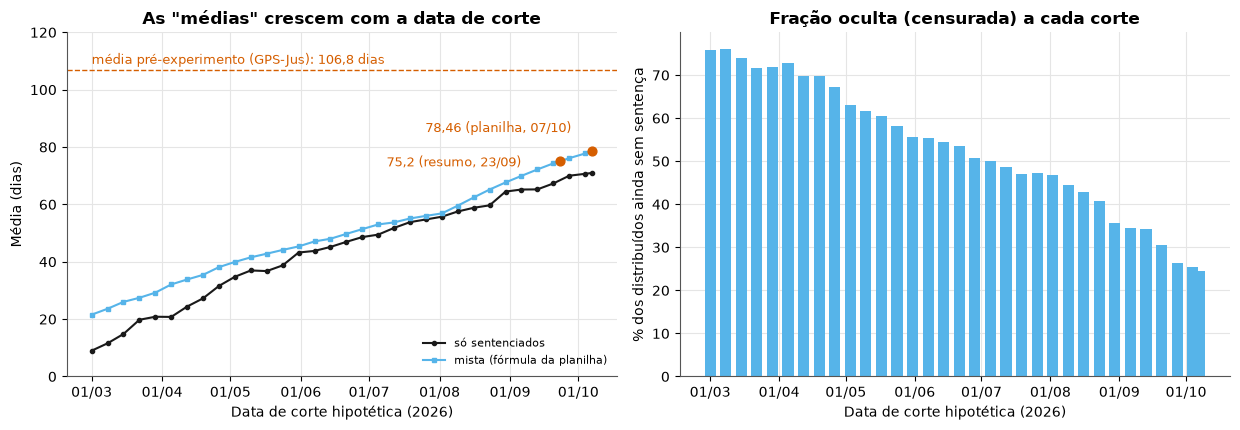

     corte  media_sentenciados  media_mista  n_sent  pct_sem_sentenca
2026-03-01                9.00        21.55      51             0.758
2026-04-26               31.58        38.14     154             0.672
2026-06-28               48.61        51.38     377             0.508
2026-09-20               67.30        74.31     651             0.306
2026-10-07               70.98        78.45     708             0.245


In [34]:
cortes = pd.date_range('2026-03-01', DATA_CORTE, freq='7D').append(pd.DatetimeIndex([DATA_CORTE]))
serie_corte = []
for c in cortes:
    distribuidos = d2['dt_distribuicao'].le(c)
    sentenciados = d2['E'].eq(1) & d2['dt_sentenca'].le(c)
    serie_corte.append({'corte': c, 'media_sentenciados': d2.loc[sentenciados, 'T'].mean(),
                        'media_mista': media_mista(brutas, c)[0], 'n_sent': int(sentenciados.sum()),
                        'pct_sem_sentenca': 1 - sentenciados.sum() / distribuidos.sum()})
serie_corte = pd.DataFrame(serie_corte)

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax[0].plot(serie_corte['corte'], serie_corte['media_sentenciados'], color=TINTA, marker='o', ms=3, label='só sentenciados')
ax[0].plot(serie_corte['corte'], serie_corte['media_mista'], color='#56B4E9', marker='s', ms=3, label='mista (fórmula da planilha)')
ax[0].axhline(106.8, color='#D55E00', ls='--', lw=1)
ax[0].text(serie_corte['corte'].iloc[0], 109, 'média pré-experimento (GPS-Jus): 106,8 dias', color='#D55E00', fontsize=9)
for data, valor, rot, desl in [(CORTE_RESUMO, 75.2, '75,2 (resumo, 23/09)', (-125, -4)),
                               (DATA_CORTE, 78.46, '78,46 (planilha, 07/10)', (-120, 14))]:
    ax[0].scatter([data], [valor], color='#D55E00', zorder=5, s=40)
    ax[0].annotate(rot, (data, valor), xytext=desl, textcoords='offset points', fontsize=9, color='#D55E00')
ax[0].set_ylabel('Média (dias)'); ax[0].legend(loc='lower right', fontsize=8)
ax[0].set_title('As "médias" crescem com a data de corte')
ax[0].set_ylim(0, 120)
ax[1].bar(serie_corte['corte'], 100 * serie_corte['pct_sem_sentenca'], width=5, color='#56B4E9')
ax[1].set_ylabel('% dos distribuídos ainda sem sentença')
ax[1].set_title('Fração oculta (censurada) a cada corte')
for a in ax:
    a.xaxis.set_major_formatter(mpl.dates.DateFormatter('%d/%m'))
    a.set_xlabel('Data de corte hipotética (2026)')
plt.tight_layout()
plt.show()
print(serie_corte.iloc[[0, 8, 17, 29, -1]].round({'media_sentenciados': 2, 'media_mista': 2, 'pct_sem_sentenca': 3}).to_string(index=False))

**Leitura. As médias divulgadas foram reconstituídas, e nenhuma mede a duração dos processos.**

- **78,46 é uma média "mista".** Com as 944 linhas e a fórmula da planilha (sentenciados pela data da sentença, ativos até 07/10/2026), obtém-se 78,45 dias no geral e 77,00 / 77,48 / 80,87 em Controle / Presencial / Remota, contra 77,00 / 77,50 / 80,87 divulgados. É a média de durações completas com tempos parciais de 206 processos ainda ativos.
- **75,2 também é uma média mista, só que com corte anterior.** O resumo expandido não explica o cálculo. A mesma fórmula com corte em **23/09/2026** (véspera da data do arquivo do resumo, 24/09) dá 75,15 dias, e 74,10 / 76,61 / 74,74 por grupo, contra 74,22 / 76,67 / 74,72 publicados. As contagens do resumo (668 sentenciados e 275 ativos) não batem com essa data (712 e 232 na planilha atual), o que sugere que parte das sentenças foi lançada depois, com data retroativa. Logo, a "queda de 106,8 para 75,2 dias" compara a média histórica do GPS-Jus com uma média que mistura processos ainda em curso, e não é evidência de aceleração.
- **A média dos sentenciados é ainda menor e instável.** Em 07/10 ela vale 70,98 dias; até 03/08 eram só 499 sentenças, com média de 55,95 dias. No gráfico, as duas médias sobem quase linearmente com a data de corte: de 9,0 dias (só sentenciados, corte em 01/03) para 70,98 (07/10), enquanto a fração ainda sem sentença cai de 76% para 25%. Um estimador que depende tanto do dia em que se olha não mede uma propriedade dos processos; mede o tempo de observação.
- **A diferença entre os grupos também é artefato.** A Remota parece "mais lenta" na média mista (80,87) porque concentra entradas em julho (seção 2.1.3), e tem mais ativos com tempo parcial. A comparação válida é a das curvas de sobrevivência: a mediana do Kaplan-Meier de todos os processos é de **89 dias** (seção 2.4.2), acima de todas as médias divulgadas.

### 2.1.3 Entrada escalonada e seguimento por mês de distribuição

O seguimento possível depende só da data de distribuição. O painel da esquerda mostra quantos processos de cada grupo entraram por mês (barras verticais agrupadas); o do meio, o seguimento máximo de cada mês; o da direita, a fração de cada mês ainda censurada em 07/10/2026. **Como ler:** se algum grupo concentrar entradas em meses tardios, ele terá, por construção, mais censura e tempos observados mais curtos, sem que isso diga nada sobre o rito.

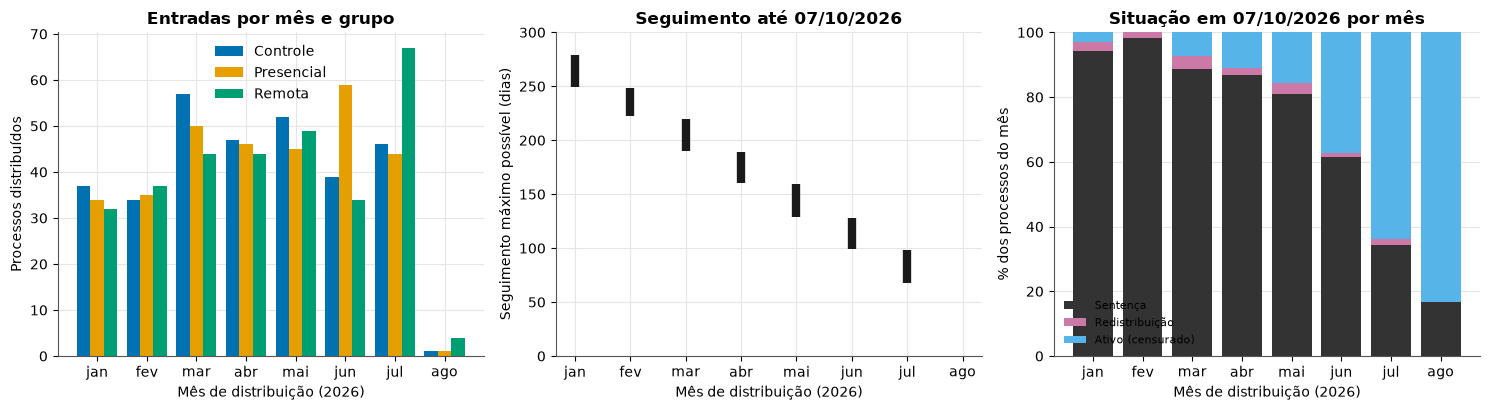

,Controle,Presencial,Remota,seg. mín,seg. máx,% Sentença,% Redistribuição,% Ativo (censurado)
mes_distribuicao,,,,,,,,
jan,37,34,32,249,279,94.2,2.9,2.9
fev,34,35,37,222,248,98.1,1.9,0.0
mar,57,50,44,190,220,88.7,4.0,7.3
abr,47,46,44,160,189,86.9,2.2,10.9
mai,52,45,49,129,159,80.8,3.4,15.8
jun,39,59,34,99,128,61.4,1.5,37.1
jul,46,44,67,68,98,34.4,1.9,63.7
ago,1,1,4,65,65,16.7,0.0,83.3


In [35]:
MESES = list(d2['mes_distribuicao'].cat.categories)
cont_mes = pd.crosstab(d2['mes_distribuicao'], d2['grupo']).reindex(columns=ORDEM_GRUPO)
seg_mes = d2.groupby('mes_distribuicao', observed=True)['followup'].agg(['min', 'max'])
cens_mes = pd.crosstab(d2['mes_distribuicao'], d2['status'], normalize='index').reindex(columns=ORDEM_STATUS)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
x = np.arange(len(MESES)); w = 0.27
for j, g in enumerate(ORDEM_GRUPO):
    ax[0].bar(x + (j - 1) * w, cont_mes[g], width=w, color=CORES_GRUPO[g], label=g)
ax[0].set_xticks(x, MESES); ax[0].set_ylabel('Processos distribuídos'); ax[0].legend()
ax[0].set_title('Entradas por mês e grupo')
ax[1].vlines(x, seg_mes['min'], seg_mes['max'], color=TINTA, lw=6)
ax[1].set_xticks(x, MESES); ax[1].set_ylabel('Seguimento máximo possível (dias)')
ax[1].set_title('Seguimento até 07/10/2026'); ax[1].set_ylim(0, 300)
base = np.zeros(len(MESES))
for s in ORDEM_STATUS:
    ax[2].bar(x, 100 * cens_mes[s], bottom=base, color=CORES_STATUS[s], label=s)
    base += 100 * cens_mes[s].to_numpy()
ax[2].set_xticks(x, MESES); ax[2].set_ylabel('% dos processos do mês'); ax[2].legend(loc='lower left', fontsize=8)
ax[2].set_title('Situação em 07/10/2026 por mês')
for a in ax:
    a.set_xlabel('Mês de distribuição (2026)')
plt.tight_layout()
plt.show()
display(pd.concat([cont_mes, seg_mes.rename(columns={'min': 'seg. mín', 'max': 'seg. máx'}),
                   (100 * cens_mes).round(1).add_prefix('% ')], axis=1))

**Leitura. A entrada escalonada faz do mês de distribuição um determinante da censura.**

- O seguimento possível vai de 249 a 279 dias para os processos de janeiro e de só 68 a 98 dias para os de julho. Por isso a fração ainda ativa em 07/10 cresce com o mês: 2,9% (jan.), 0% (fev.), 7,3% (mar.), 10,9% (abr.), 15,8% (mai.), **37,1% (jun.)**, **63,7% (jul.)** e 83,3% dos 6 processos de agosto.
- **Os grupos não entraram no mesmo ritmo.** Em junho, a Presencial recebeu 59 processos, contra 39 do Controle e 34 da Remota; em julho, a **Remota recebeu 67**, contra 46 e 44. Como esses meses têm seguimento curto, a Presencial e, sobretudo, a Remota carregam mais censura por razões de calendário, e não de rito. A aderência mês a mês é testada na seção 2.5.1.
- **Consequência para a análise:** qualquer comparação ingênua entre grupos (médias, proporção de encerrados, χ² de grupo × situação, como no notebook do professor, E19) confunde o rito com o mês de entrada. O mês entra como covariável ou estrato nas Partes IV e V.

### 2.1.4 Trajetórias individuais (gráfico de nadador / diagrama de Lexis simplificado)

Cada linha horizontal é um processo: começa na data de distribuição e termina na sentença (círculo, colorido pelo tipo de desfecho), na redistribuição (losango) ou na data de corte (seta: censurado). Usa-se uma amostra estratificada de 25 processos por grupo (semente fixa), ordenada pela data de distribuição. **Como ler:** as setas se acumulam nos processos de entrada tardia, e a linha vertical de 07/10/2026 é a "parede" que corta as trajetórias; o comprimento de uma seta é um limite inferior, não uma duração.

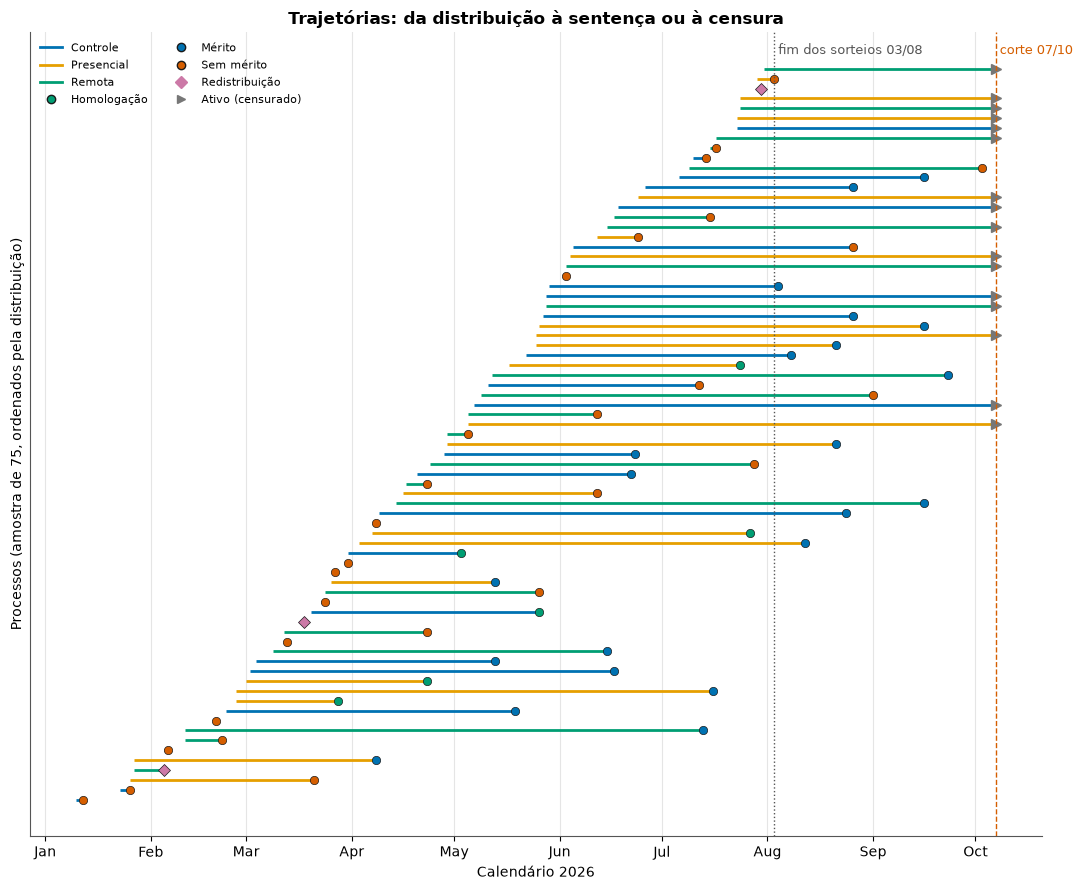

status
Sentença             56
Ativo (censurado)    16
Redistribuição        3


In [36]:
amostra = (d2.groupby('grupo', observed=True).sample(25, random_state=SEMENTE)
              .sort_values('dt_distribuicao').reset_index(drop=True))
fim = amostra['dt_sentenca'].fillna(DATA_CORTE)
fig, ax = plt.subplots(figsize=(11, 9))
for i, r in amostra.iterrows():
    ax.hlines(i, r['dt_distribuicao'], fim[i], color=CORES_GRUPO[r['grupo']], lw=2)
    if r['evento_cr'] == 1:
        ax.plot(fim[i], i, 'o', color=CORES_DESFECHO[r['tipo_desfecho']], ms=6, mec=TINTA, mew=0.5)
    elif r['evento_cr'] == 2:
        ax.plot(fim[i], i, 'D', color=CORES_DESFECHO['Redistribuição'], ms=6, mec=TINTA, mew=0.5)
    else:
        ax.plot(fim[i], i, '>', color='#777777', ms=7)
ax.axvline(DATA_CORTE, color='#D55E00', ls='--', lw=1)
ax.axvline(FIM_RECRUTAMENTO, color=TINTA_2, ls=':', lw=1)
ax.text(DATA_CORTE, len(amostra) + 0.5, ' corte 07/10', color='#D55E00', fontsize=9)
ax.text(FIM_RECRUTAMENTO, len(amostra) + 0.5, ' fim dos sorteios 03/08', color=TINTA_2, fontsize=9)
ax.set_yticks([]); ax.set_ylabel('Processos (amostra de 75, ordenados pela distribuição)')
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%b'))
ax.set_xlabel('Calendário 2026')
ax.set_title('Trajetórias: da distribuição à sentença ou à censura')
leg = ([mpl.lines.Line2D([], [], color=CORES_GRUPO[g], lw=2, label=g) for g in ORDEM_GRUPO] +
       [mpl.lines.Line2D([], [], marker='o', ls='', color=CORES_DESFECHO[k], mec=TINTA, label=k)
        for k in ['Homologação', 'Mérito', 'Sem mérito']] +
       [mpl.lines.Line2D([], [], marker='D', ls='', color=CORES_DESFECHO['Redistribuição'], label='Redistribuição'),
        mpl.lines.Line2D([], [], marker='>', ls='', color='#777777', label='Ativo (censurado)')])
ax.legend(handles=leg, loc='upper left', fontsize=8, ncol=2)
plt.tight_layout()
plt.show()
print(amostra['status'].value_counts().to_string())

**Leitura.** Na amostra de 75 processos (25 por grupo), 56 terminaram em sentença, 3 em redistribuição e 16 seguem ativos. O gráfico deixa visíveis três padrões que as médias escondem:

- **As setas (censurados) se concentram em junho e julho.** Todas encostam na linha de 07/10, e o seu comprimento varia de pouco mais de 60 dias a cerca de 4 meses: são limites inferiores, não durações.
- **Há dois "relógios" nos desfechos.** As extinções sem mérito (círculos laranja) aparecem muitas vezes poucos dias após a distribuição, com segmentos curtíssimos; as sentenças de mérito (azul) aparecem de 2 a 7 meses depois. Essa bimodalidade reaparece no histograma (seção 2.2.3) e na forma do risco (seção 2.4.1).
- **Processos distribuídos no mesmo dia podem ter destinos muito diferentes**, o que mostra a variabilidade individual que os testes e modelos precisam acomodar.

## 2.2 Análise univariada

### 2.2.1 Variáveis categóricas: tabelas de frequência

Para cada variável categórica, a tabela traz a frequência absoluta (n), a relativa (%) e a acumulada (% acum.) sobre os 938 processos, e o % sobre os casos válidos (excluídas as ausências). As ausências **não** são categorias de resposta: são mostradas com o motivo (zero estrutural, "não se aplica", ou processo ativo ainda sem a informação), como determinado na Parte I. A % acumulada só tem leitura substantiva nas variáveis ordinais (mês, dia da semana, ciclo); nas nominais, é a base do gráfico de Pareto.

In [37]:
def para_rotulos(serie, rotulo_na):
    # Converte booleanos em Sim/Não e ausências no rótulo explicativo, preservando a ordem das categorias
    if isinstance(serie.dtype, pd.BooleanDtype):
        s = serie.map({True: 'Sim', False: 'Não'})
        ordem = ['Sim', 'Não']
    elif isinstance(serie.dtype, pd.CategoricalDtype):
        s = serie.astype(object)
        ordem = list(serie.cat.categories)
    else:
        s = serie.astype(object)
        ordem = sorted(s.dropna().unique())
    s = s.where(serie.notna(), rotulo_na)
    if serie.isna().any():
        ordem = ordem + [rotulo_na]
    return pd.Categorical(s, categories=ordem, ordered=True)


def tabela_freq(serie, rotulo_na='NA'):
    cat = para_rotulos(serie, rotulo_na)
    n = pd.Series(cat).value_counts(sort=False)
    validos = n.drop(rotulo_na, errors='ignore')
    tab = pd.DataFrame({'n': n, '%': 100 * n / n.sum()})
    tab['% acum.'] = tab['%'].cumsum()
    tab['% válido'] = (100 * validos / validos.sum()).reindex(tab.index)
    return tab


VARS_CAT = {   # variável: (título, rótulo das ausências)
    'grupo': ('Grupo sorteado', None),
    'mes_distribuicao': ('Mês de distribuição', None),
    'ciclo': ('Ciclo (resumo expandido)', None),
    'dia_semana_distribuicao': ('Dia da semana da distribuição', None),
    'tipo_desfecho': ('Tipo de desfecho em 07/10/2026', None),
    'ac_realizada': ('AC realizada', 'não informado (ativo)'),
    'tecnica_curta': ('Técnica de conciliação', 'sem AC (não se aplica)'),
    'hibrida': ('AC híbrida', 'não informado'),
    'acordo_ac': ('Acordo na AC', 'não informado'),
    'acordo_fora': ('Acordo fora da AC', 'ativo (indefinido)'),
    'acordo': ('Acordo (qualquer momento)', 'ativo (indefinido)'),
    'origem_externa': ('Origem externa (redistribuído à vara)', None),
    'tempo_zero': ('Desfecho no dia da distribuição', None),
    'sentenca_fim_semana': ('Desfecho datado em fim de semana', 'ativo (sem desfecho)'),
    'desvio_protocolo': ('Desvio de protocolo (híbrida na Remota ou sem AC)', None),
    'cnj_corrigido': ('Número CNJ corrigido', None),
    'duplicado_removido': ('Número com linha duplicada removida', None),
}
tabelas_freq = {VARS_CAT[v][0]: tabela_freq(d2[v], VARS_CAT[v][1] or 'NA') for v in VARS_CAT}
tab_freq = pd.concat(tabelas_freq, names=['Variável', 'Categoria'])
with pd.option_context('display.max_rows', 200):
    display(tab_freq.round(1))

n     %  % acum.  % válido
Variável                                          Categoria                                           
Grupo sorteado                                    Controle                313  33.4     33.4      33.4
                                                  Presencial              314  33.5     66.8      33.5
                                                  Remota                  311  33.2    100.0      33.2
Mês de distribuição                               jan                     103  11.0     11.0      11.0
                                                  fev                     106  11.3     22.3      11.3
                                                  mar                     151  16.1     38.4      16.1
                                                  abr                     137  14.6     53.0      14.6
                                                  mai                     146  15.6     68.6      15.6
                                                  jun                     132  14.1     82.6      14.1
                                                  jul                     157  16.7     99.4      16.7
                                                  ago                       6   0.6    100.0       0.6
Ciclo (resumo expandido)                          1º ciclo                485  51.7     51.7      51.7
                                                  2º ciclo                453  48.3    100.0      48.3
Dia da semana da distribuição                     seg                     181  19.3     19.3      19.3
                                                  ter                     181  19.3     38.6      19.3
                                                  qua                     181  19.3     57.9      19.3
                                                  qui                     182  19.4     77.3      19.4
                                                  sex                     157  16.7     94.0      16.7
                                                  sáb                      28   3.0     97.0       3.0
                                                  dom                      28   3.0    100.0       3.0
Tipo de desfecho em 07/10/2026                    Homologação              81   8.6      8.6       8.6
                                                  Mérito                  341  36.4     45.0      36.4
                                                  Sem mérito              286  30.5     75.5      30.5
                                                  Redistribuição           24   2.6     78.0       2.6
                                                  Ativo                   206  22.0    100.0      22.0
AC realizada                                      Sim                     352  37.5     37.5      40.7
                                                  Não                     513  54.7     92.2      59.3
                                                  não informado (ativo)    73   7.8    100.0       NaN
Técnica de conciliação                            Desconstrução            47   5.0      5.0      13.4
                                                  Parafraseamento          57   6.1     11.1      16.2
                                                  Separação                60   6.4     17.5      17.0
                                                  Padrões objetivos        67   7.1     24.6      19.0
                                                  Afago                    58   6.2     30.8      16.5
                                                  Comunicação              63   6.7     37.5      17.9
                                                  sem AC (não se aplica)  586  62.5    100.0       NaN
AC híbrida                                        Sim                      31   3.3      3.3       3.6
                                                  Não                     838  89.3     92.6      96.4
                                                  não infor

**Gráficos de barras verticais.** As variáveis do desenho (grupo e calendário) aparecem primeiro; o rótulo de cada barra é a frequência absoluta. As ausências são desenhadas em cinza claro e com hachura, para não se confundirem com uma categoria de resposta.

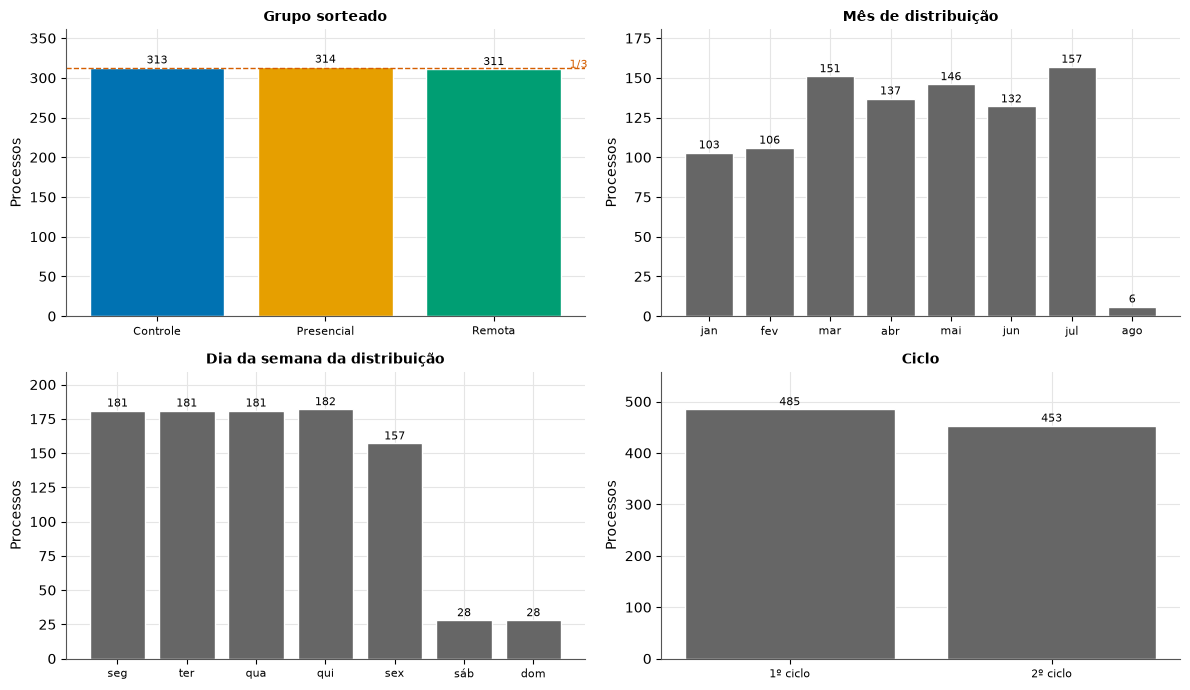

In [38]:
def barras(ax, serie, titulo, rotulo_na='NA', cores=None, rot=0):
    tab = tabela_freq(serie, rotulo_na)
    cores_barras = []
    for k in tab.index:
        if k == rotulo_na:
            cores_barras.append('#dddddd')
        elif cores and k in cores:
            cores_barras.append(cores[k])
        else:
            cores_barras.append('#666666')
    barras_ = ax.bar(range(len(tab)), tab['n'], color=cores_barras, edgecolor='white')
    for b, k in zip(barras_, tab.index):
        if k == rotulo_na:
            b.set_hatch('//'); b.set_edgecolor('#999999')
    ax.bar_label(barras_, labels=[f'{v}' for v in tab['n']], fontsize=8, padding=1)
    ax.set_xticks(range(len(tab)), [str(k) for k in tab.index], rotation=rot, ha='right' if rot else 'center', fontsize=8)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylim(0, tab['n'].max() * 1.15)
    return tab


fig, ax = plt.subplots(2, 2, figsize=(12, 7))
barras(ax[0, 0], d2['grupo'], 'Grupo sorteado', cores=CORES_GRUPO)
ax[0, 0].axhline(len(d2) / 3, color='#D55E00', ls='--', lw=1); ax[0, 0].text(2.45, len(d2) / 3, '1/3', color='#D55E00', fontsize=8)
barras(ax[0, 1], d2['mes_distribuicao'], 'Mês de distribuição')
barras(ax[1, 0], d2['dia_semana_distribuicao'], 'Dia da semana da distribuição')
barras(ax[1, 1], d2['ciclo'], 'Ciclo')
for a in ax.flat:
    a.set_ylabel('Processos')
plt.tight_layout()
plt.show()

**Leitura. O desenho está equilibrado nos grupos, mas não no calendário.**

- **Grupos:** 313 (33,4%), 314 (33,5%) e 311 (33,2%), praticamente 1/3 cada. É um equilíbrio notável, analisado como evidência sobre o mecanismo do sorteio na seção 2.5.1.
- **Mês:** a distribuição não é uniforme. Janeiro e fevereiro têm cerca de 105 processos (recesso forense até 20/01 e mês curto); março a julho, de 132 a 157; agosto, só 6 (o sorteio terminou em 03/08). A % acumulada mostra que metade dos processos entrou até abril (53,0%) e o 2º ciclo (29/04 a 03/08) tem 453 processos (48,3%), contra 485 no 1º.
- **Dia da semana da distribuição:** segunda a quinta têm de 181 a 182 processos cada, sexta tem 157 e sábado e domingo têm 28 cada (3,0%). A distribuição eletrônica do PJe ocorre também nos fins de semana, de modo que essas datas são legítimas.

**Desfecho e técnica: gráficos de Pareto.** Para as duas variáveis nominais com várias categorias, o Pareto ordena as barras da mais para a menos frequente e acrescenta a linha da % acumulada (eixo da direita). Ele responde a "quais categorias concentram os casos". No tipo de desfecho, "Ativo" é mantido porque é uma situação real em 07/10/2026 (ainda sem desfecho), mas é a censura, não um desfecho.

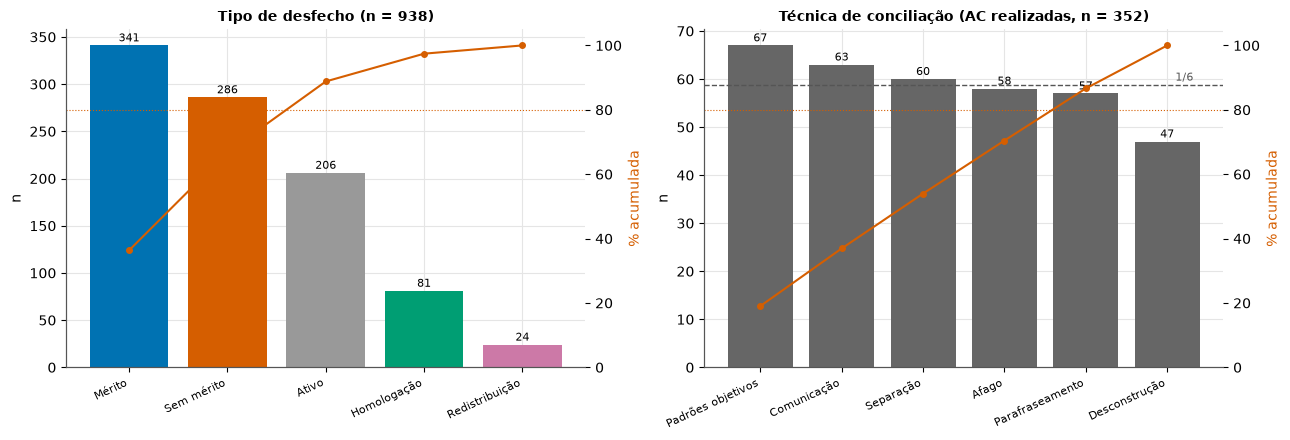

In [39]:
def pareto(ax, serie, titulo, cores=None):
    n = serie.value_counts().sort_values(ascending=False)
    acum = 100 * n.cumsum() / n.sum()
    b = ax.bar(range(len(n)), n.to_numpy(), color=[(cores or {}).get(k, '#666666') for k in n.index])
    ax.bar_label(b, fontsize=8, padding=1)
    ax.set_xticks(range(len(n)), n.index, rotation=25, ha='right', fontsize=8)
    ax.set_ylabel('n'); ax.set_title(titulo, fontsize=10)
    ax2 = ax.twinx()
    ax2.plot(range(len(n)), acum.to_numpy(), color='#D55E00', marker='o', ms=4)
    ax2.set_ylim(0, 105); ax2.set_ylabel('% acumulada', color='#D55E00'); ax2.grid(False)
    ax2.axhline(80, color='#D55E00', ls=':', lw=0.8)
    return n


fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
pareto(ax[0], d2['tipo_desfecho'].astype(str), 'Tipo de desfecho (n = 938)', CORES_DESFECHO)
pareto(ax[1], d2['tecnica_curta'].dropna().astype(str), 'Técnica de conciliação (AC realizadas, n = 352)')
ax[1].axhline(352 / 6, color=TINTA_2, ls='--', lw=1)
ax[1].text(5.1, 352 / 6 + 1, '1/6', fontsize=8, color=TINTA_2)
plt.tight_layout()
plt.show()

**Leitura.**

- **Desfecho.** O Pareto mostra que mérito (341; 36,4%) e sem mérito (286; 30,5%) somam dois terços dos processos; com os 206 ativos (22,0%), chegam a 88,9%. Homologação de acordo (81; 8,6%) e redistribuição (24; 2,6%) são minoritárias. A taxa de 8,6% de homologações tem como denominador os distribuídos, inclusive os ativos; o índice de conciliação com o denominador correto (sentenças) está na seção 2.5.2.
- **Técnica.** Entre as 352 AC realizadas, as seis técnicas aparecem com frequências próximas, de 47 (Desconstrução; 13,4%) a 67 (Padrões objetivos; 19,0%), todas em torno da linha de 1/6 (58,7 audiências). O Pareto é quase plano: são necessárias cinco das seis técnicas para chegar a 80% dos casos. Não há sinal da hegemonia de "padrões objetivos" com 53,85% afirmada no resumo expandido; o teste está na seção 2.5.3.

**Audiência e acordo; indicadores de qualidade.** Painéis de barras verticais para as variáveis binárias. A leitura correta de cada uma depende do denominador: `acordo_ac`, `hibrida` e `tecnica` só têm sentido onde houve AC; `acordo` e `acordo_fora` ficam indefinidos nos ativos (o acordo ainda pode acontecer). Os indicadores da segunda linha são *flags* de curadoria (Parte I), úteis para as análises de sensibilidade.

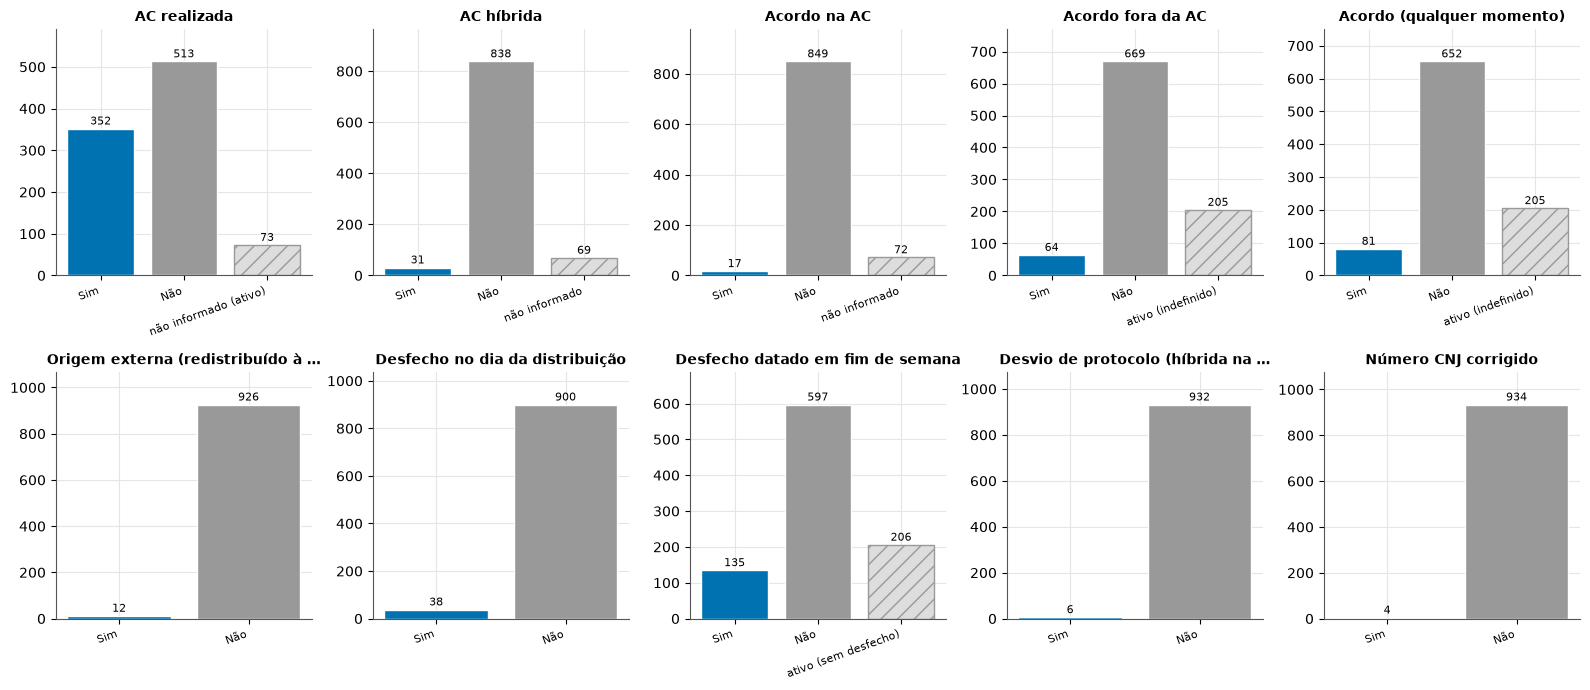

AC realizadas: 352 (Presencial 178, Remota 174); acordo na AC: 17 (4,8% das AC realizadas)
Híbridas: 31, das quais 28 no grupo Presencial
Acordo em qualquer momento: 81 = homologações (81)


In [40]:
painel = ['ac_realizada', 'hibrida', 'acordo_ac', 'acordo_fora', 'acordo',
          'origem_externa', 'tempo_zero', 'sentenca_fim_semana', 'desvio_protocolo', 'cnj_corrigido']
fig, ax = plt.subplots(2, 5, figsize=(16, 7))
for a, v in zip(ax.flat, painel):
    titulo, rot_na = VARS_CAT[v]
    barras(a, d2[v], titulo if len(titulo) < 34 else titulo[:32] + '…', rot_na or 'NA',
           cores={'Sim': '#0072B2', 'Não': '#999999'}, rot=20)
plt.tight_layout()
plt.show()

# Denominadores corretos das taxas de AC e acordo
ac = d2[d2['ac_realizada'].fillna(False).astype(bool)].copy()
print(f'AC realizadas: {len(ac)} (Presencial {(ac.grupo == "Presencial").sum()}, Remota {(ac.grupo == "Remota").sum()}); '
      f'acordo na AC: {int(ac.acordo_ac.sum())} ({pct_br(ac.acordo_ac.mean())} das AC realizadas)')
print(f'Híbridas: {int(d2.hibrida.sum())}, das quais {int((d2.hibrida.fillna(False) & d2.grupo.eq("Presencial")).sum())} no grupo Presencial')
print(f'Acordo em qualquer momento: {int(d2.acordo.sum())} = homologações ({(d2.tipo_desfecho == "Homologação").sum()})')

**Leitura. As taxas só têm sentido com o denominador certo.**

- **AC realizada:** 352 audiências (178 na Presencial e 174 na Remota). Os 513 "Não" incluem os 313 processos do Controle, em que a AC não existe no rito (zero estrutural), e 200 processos tratados em que a AC não ocorreu, em geral porque o processo foi extinto antes (seção 2.5.2). Os 73 sem informação são tratados ativos ainda sem audiência.
- **Acordo na AC:** 17 acordos, isto é, **4,8% das AC realizadas**. Os 1,8% sobre os 938 processos (como no notebook do professor, E30) diluem a taxa com o Controle, que não tem audiência.
- **Acordo fora da AC:** 64, quase quatro vezes os obtidos em audiência; o **acordo em qualquer momento** soma 81, exatamente o número de homologações. Os 205 "ativo (indefinido)" não são "sem acordo": o acordo ainda pode ocorrer.
- **Híbrida:** 31 casos, 28 na Presencial (3,6% dos válidos) e 3 na Remota, estes incongruentes com o protocolo (`desvio_protocolo`, 6 casos ao todo).
- **Indicadores de curadoria:** 12 processos de origem externa (1,3%), 38 desfechos no dia da distribuição (4,1%; seção 2.2.5), 135 desfechos datados em fim de semana (18,4% dos desfechos; seção 2.5.4), 4 números CNJ corrigidos e 5 números com linha duplicada removida. Todos são raros o bastante para análises de sensibilidade sem perda de poder.

### 2.2.2 O tempo: medidas descritivas

As medidas são calculadas em quatro recortes, que **não** são intercambiáveis:

- **Sentenças (n = 708)**: durações completas, mas **condicionais** a ter havido sentença até 07/10/2026. Descrevem os processos já sentenciados, não "o tempo de tramitação" do 4º JEC, porque os processos longos estão sub-representados (ainda ativos).
- **Ativos (n = 206)**: tempo já decorrido até o corte; é um **limite inferior** da duração real.
- **Redistribuições (n = 24)**: tempo até a saída da vara; não é tempo até sentença.
- **Todos os tempos observados (n = 938)**: o que a planilha e o notebook do professor resumiam (E7, E14). Apresentado só para mostrar o que estava sendo calculado; **não estima nenhuma quantidade interpretável**.

Medidas: média, mediana, moda (dia mais frequente), desvio-padrão, variância, coeficiente de variação (CV = DP/média), quantis, intervalo interquartil (IIQ), mínimo, máximo, assimetria e curtose em excesso (estimadores sem viés de Fisher; curtose 0 = normal), MAD (desvio absoluto mediano, escala bruta e reescalada por 1,4826 para comparação com o DP), média aparada a 10% e intervalo de confiança *bootstrap* de 95% da mediana (percentil, 5.000 reamostras, semente fixa).

In [41]:
def descritivas(x, b=5000):
    x = np.asarray(x, dtype=float)
    moda = pd.Series(x).mode()
    q = np.percentile(x, [5, 10, 25, 50, 75, 90, 95])
    boot = stats.bootstrap((x,), np.median, n_resamples=b, confidence_level=0.95, method='percentile',
                           rng=np.random.default_rng(SEMENTE))
    return pd.Series({
        'n': len(x), 'média': x.mean(), 'EP da média': x.std(ddof=1) / np.sqrt(len(x)),
        'mediana': q[3], 'IC95% mediana (inf.)': boot.confidence_interval.low,
        'IC95% mediana (sup.)': boot.confidence_interval.high,
        'moda': moda.iloc[0], 'freq. da moda': int((x == moda.iloc[0]).sum()),
        'desvio-padrão': x.std(ddof=1), 'variância': x.var(ddof=1), 'CV (%)': 100 * x.std(ddof=1) / x.mean(),
        'mínimo': x.min(), 'P5': q[0], 'P10': q[1], 'Q1 (P25)': q[2], 'Q3 (P75)': q[4], 'P90': q[5], 'P95': q[6],
        'máximo': x.max(), 'amplitude': x.max() - x.min(), 'IIQ': q[4] - q[2],
        'assimetria': stats.skew(x, bias=False), 'curtose (excesso)': stats.kurtosis(x, bias=False),
        'MAD': stats.median_abs_deviation(x), 'MAD × 1,4826': stats.median_abs_deviation(x, scale='normal'),
        'média aparada 10%': stats.trim_mean(x, 0.10),
    })


recortes = {'Sentenças (condicional)': sent['T'],
            'Ativos (limite inferior)': d2.loc[d2.evento_cr.eq(0), 'T'],
            'Redistribuições': d2.loc[d2.evento_cr.eq(2), 'T'],
            'Todos os observados (inválido)': d2['T']}
tab_desc = pd.DataFrame({k: descritivas(v) for k, v in recortes.items()})
display(tab_desc.round(2))

,Sentenças (condicional),Ativos (limite inferior),Redistribuições,Todos os observados (inválido)
n,708.00,206.00,24.00,938.00
média,70.98,111.50,11.29,78.35
EP da média,1.83,2.95,4.69,1.66
mediana,73.50,97.00,1.00,80.00
IC95% mediana (inf.),70.00,92.00,1.00,77.00
IC95% mediana (sup.),78.00,107.00,5.00,83.00
moda,1.00,70.00,1.00,1.00
freq. da moda,47.00,8.00,8.00,55.00
desvio-padrão,48.73,42.33,22.99,50.94
variância,2375.09,1792.15,528.74,2594.94


### 2.2.3 O tempo: gráficos

Quatro gráficos complementares, todos em escala linear:

- **(a) Histograma** dos tempos observados, empilhado pela situação (sentença, redistribuição, ativo). Classes de 10 dias. Mostra onde estão os censurados (à direita, porque só se tornam censurados os processos que chegaram ao corte sem sentença).
- **(b) Boxplot vertical** por recorte. A caixa vai de Q1 a Q3, a linha é a mediana, o losango é a média; os "bigodes" vão até 1,5 IIQ.
- **(c) Violino** das sentenças por tipo de desfecho: a largura é a densidade estimada (núcleo gaussiano), o que revela bimodalidade que o boxplot esconde.
- **(d) ECDF** (função de distribuição empírica) das sentenças e dos ativos. **Atenção:** a ECDF das sentenças **não** é 1 − KM; ela ignora os censurados e por isso sobe depressa demais (o KM correto está na Parte IV).

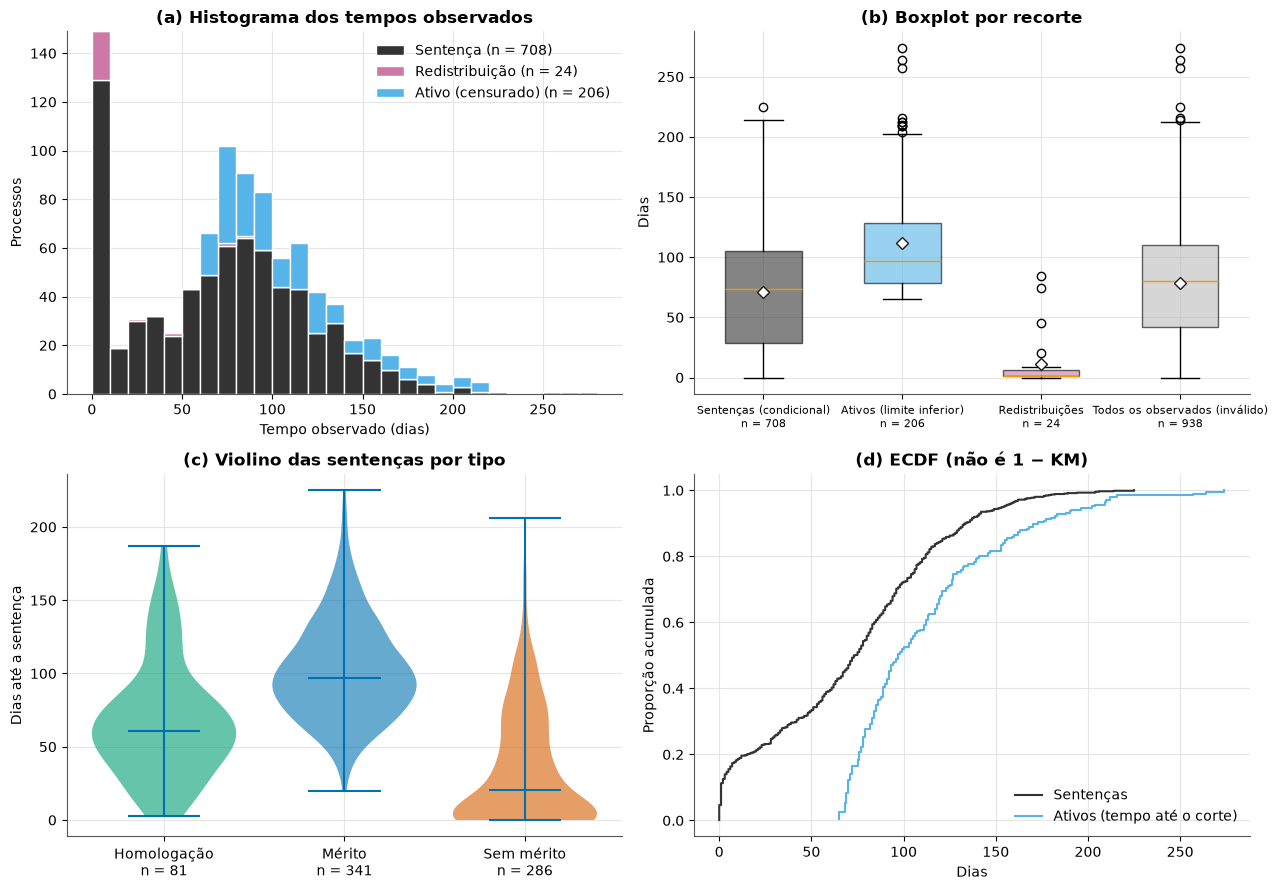

In [42]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
classes = np.arange(0, 290, 10)
base = np.zeros(len(classes) - 1)
for s in ORDEM_STATUS:
    h, _ = np.histogram(d2.loc[d2.status.eq(s), 'T'], bins=classes)
    ax[0, 0].bar(classes[:-1], h, width=10, align='edge', bottom=base, color=CORES_STATUS[s],
                 edgecolor='white', label=f'{s} (n = {d2.status.eq(s).sum()})')
    base += h
ax[0, 0].set_xlabel('Tempo observado (dias)'); ax[0, 0].set_ylabel('Processos'); ax[0, 0].legend()
ax[0, 0].set_title('(a) Histograma dos tempos observados')

dados_box = [recortes[k].to_numpy(float) for k in recortes]
bp = ax[0, 1].boxplot(dados_box, showmeans=True, widths=0.55, patch_artist=True,
                      meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor=TINTA))
for p, c in zip(bp['boxes'], ['#333333', '#56B4E9', '#CC79A7', '#bbbbbb']):
    p.set_facecolor(c); p.set_alpha(0.6)
ax[0, 1].set_xticks(range(1, 5), [f'{k}\nn = {len(v)}' for k, v in recortes.items()], fontsize=8)
ax[0, 1].set_ylabel('Dias'); ax[0, 1].set_title('(b) Boxplot por recorte')

tipos = ['Homologação', 'Mérito', 'Sem mérito']
vp = ax[1, 0].violinplot([sent.loc[sent.tipo_desfecho.eq(t), 'T'] for t in tipos], showmedians=True, widths=0.8)
for corpo, t in zip(vp['bodies'], tipos):
    corpo.set_facecolor(CORES_DESFECHO[t]); corpo.set_alpha(0.6)
ax[1, 0].set_xticks(range(1, 4), [f'{t}\nn = {sent.tipo_desfecho.eq(t).sum()}' for t in tipos])
ax[1, 0].set_ylabel('Dias até a sentença'); ax[1, 0].set_title('(c) Violino das sentenças por tipo')

for nome, serie, cor in [('Sentenças', sent['T'], '#333333'), ('Ativos (tempo até o corte)', d2.loc[d2.evento_cr.eq(0), 'T'], '#56B4E9')]:
    xs = np.sort(serie.to_numpy(float))
    ax[1, 1].step(xs, np.arange(1, len(xs) + 1) / len(xs), where='post', color=cor, label=nome)
ax[1, 1].set_xlabel('Dias'); ax[1, 1].set_ylabel('Proporção acumulada'); ax[1, 1].legend(loc='lower right')
ax[1, 1].set_title('(d) ECDF (não é 1 − KM)')
plt.tight_layout()
plt.show()

**Leitura. A distribuição dos tempos é bimodal, e a censura ocupa a cauda direita.**

- **(a) Histograma.** Há um primeiro pico na classe de 0 a 10 dias (cerca de 130 sentenças e a maior parte das redistribuições), formado por extinções sem mérito e declinações de competência; um vale entre 10 e 50 dias; e uma segunda moda entre 70 e 100 dias. Os ativos (azul) começam em 65 dias e dominam as classes acima de 150 dias: a cauda direita da duração real está **escondida** na censura.
- **(b) Boxplots.** A mediana das sentenças (73,5 dias) fica abaixo da dos ativos (97 dias, que ainda vai crescer). A caixa "todos os observados" (mediana 80) parece uma distribuição comportada, mas é uma mistura sem significado. As redistribuições são quase todas imediatas (mediana de 1 dia).
- **(c) Violinos.** Cada tipo de desfecho tem a sua própria distribuição: mérito centrado perto de 100 dias, homologação perto de 60 e sem mérito com massa concentrada junto de zero e uma cauda até 200 dias. A distribuição global é a soma dessas três.
- **(d) ECDF.** A ECDF das sentenças sobe rapidamente até cerca de 20% nos primeiros dias (as extinções imediatas) e atinge 50% por volta de 73 dias. Por ignorar os 230 censurados, ela superestima a velocidade de encerramento: com censura, a mediana é de 89 dias (Kaplan-Meier, seção 2.4.2).

O **QQ-plot normal** das sentenças compara os quantis observados com os de uma normal de mesma média e desvio-padrão. Pontos sobre a reta indicam normalidade; curvatura em "S" indica caudas diferentes da normal; desvios nas pontas indicam assimetria ou truncamento. Os testes formais de normalidade estão na seção 2.3.

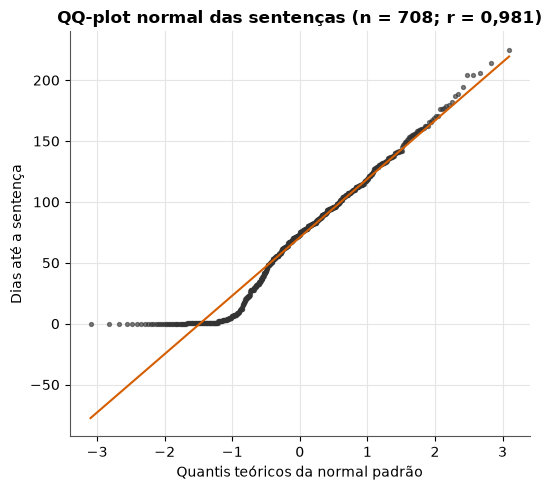

In [43]:
fig, ax = plt.subplots(figsize=(5.5, 5))
(osm, osr), (incl, inter, r) = stats.probplot(sent['T'], dist='norm')
ax.scatter(osm, osr, s=8, color='#333333', alpha=0.6)
ax.plot(osm, inter + incl * osm, color='#D55E00')
ax.set_xlabel('Quantis teóricos da normal padrão'); ax.set_ylabel('Dias até a sentença')
ax.set_title(f'QQ-plot normal das sentenças (n = {len(sent)}; r = {fmt_br(r, 3)})')
plt.tight_layout()
plt.show()

**Leitura das medidas descritivas (tabela da seção 2.2.2) e do QQ-plot.**

- **Sentenças (n = 708, condicional):** média 70,98 dias (EP 1,83), mediana 73,5 (IC95% *bootstrap* 70,0 a 78,0), moda 1 dia (47 sentenças), desvio-padrão 48,7, CV 68,7%, IIQ 76,25 (Q1 = 29, Q3 = 105,25), P90 = 133, máximo 225. A assimetria (0,21) e a curtose em excesso (−0,56) são próximas de zero, mas isso **não** indica normalidade: a distribuição é bimodal e truncada pela janela de observação, e a cauda direita foi cortada pela censura (exatamente o equívoco de leitura do notebook do professor, E15). O MAD reescalado (54,1) é maior que o desvio-padrão (48,7), sinal de distribuição "achatada" (platicúrtica), e não de caudas pesadas; a média aparada a 10% (68,9) fica perto da média.
- **Ativos (n = 206):** o tempo já decorrido vai de 65 a 274 dias (mediana 97). São limites inferiores: a duração final será maior.
- **Redistribuições (n = 24):** mediana de 1 dia e média de 11,3; quase todas são declinações imediatas.
- **Todos os observados (n = 938):** média 78,35 e mediana 80. Não estimam nada (mistura de durações completas, parciais e de saídas da vara).
- **QQ-plot.** Os pontos formam um "patamar" horizontal na cauda esquerda (os tempos próximos de zero, muito mais frequentes do que uma normal admitiria, e sem valores negativos possíveis) e, no centro e na cauda direita, acompanham a reta com curvatura leve. O desvio é de forma (bimodalidade e limite inferior em zero), e é testado formalmente na seção 2.3.

### 2.2.4 Valores atípicos (regra do IIQ)

Pela regra de Tukey, é atípico o valor fora de [Q1 − 1,5·IIQ; Q3 + 1,5·IIQ]. A regra é aplicada às sentenças (durações completas). **Nenhum valor é removido**: um processo de 220 dias não é erro de medida, é uma duração legítima, e justamente a cauda longa é o que interessa à gestão do acervo. Remover "outliers" de uma variável de tempo encurtaria artificialmente as durações. A conferência de datas (Parte I, seção 1.13) já descartou erros de registro (sentença anterior à distribuição etc.).

In [44]:
q1, q3 = sent['T'].quantile([0.25, 0.75])
iiq = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iiq, q3 + 1.5 * iiq
atipicos = sent[(sent['T'] < lim_inf) | (sent['T'] > lim_sup)]
print(f'Sentenças: Q1 = {fmt_br(q1)}, Q3 = {fmt_br(q3)}, IIQ = {fmt_br(iiq)}; cercas = [{fmt_br(lim_inf)}; {fmt_br(lim_sup)}] dias')
print(f'Atípicos: {len(atipicos)} ({pct_br(len(atipicos) / len(sent))})')
display(atipicos[['processo', 'grupo', 'dt_distribuicao', 'dt_sentenca', 'tempo', 'tipo_desfecho', 'mes_distribuicao']]
        .sort_values('tempo', ascending=False))
# Os mesmos limites aplicados aos tempos dos ativos (só para referência: são limites inferiores)
ativos_acima = d2[d2.evento_cr.eq(0) & (d2['T'] > lim_sup)]
print(f'Ativos com tempo já decorrido acima da cerca superior: {len(ativos_acima)} '
      f'(seriam atípicos certos se sentenciados hoje)')

Sentenças: Q1 = 29,0, Q3 = 105,2, IIQ = 76,2; cercas = [-85,4; 219,6] dias
Atípicos: 1 (0,1%)


,processo,grupo,dt_distribuicao,dt_sentenca,tempo,tipo_desfecho,mes_distribuicao
19,0800248-16.2026.8.20.5004,Controle,2026-01-12,2026-08-25,225,Mérito,jan


Ativos com tempo já decorrido acima da cerca superior: 3 (seriam atípicos certos se sentenciados hoje)


**Leitura.** Com Q1 = 29,0 e Q3 = 105,2 dias, as cercas de Tukey são −85,4 e 219,6 dias. Há **um único valor atípico** entre as 708 sentenças: um processo do Controle distribuído em 12/01/2026 e julgado no mérito em 25/08/2026, após 225 dias. Ele é mantido: é uma duração plausível para um processo contencioso, e não um erro de data. Três processos ativos já ultrapassaram a cerca superior; quando forem sentenciados, serão atípicos "certos". Isso mostra que a raridade de atípicos entre os sentenciados é, em parte, produto da censura: os processos longos ainda não terminaram. Remover atípicos numa variável de tempo seria eliminar justamente a informação de maior interesse para a gestão.

### 2.2.5 Tempos zero

Há processos com desfecho **no próprio dia da distribuição** (`tempo` = 0). Eles não são erro: o juízo pode indeferir a inicial, homologar desistência imediata ou declinar a competência no mesmo dia. A tabela mostra que tipo de desfecho são, em que grupo e se a AC chegou a ocorrer. Nos modelos paramétricos (seção 2.4), que exigem T > 0, esses tempos são substituídos por 0,5 dia (`tempo_pos`); nos não paramétricos, o zero é mantido.

In [45]:
zeros = d2[d2['T'].eq(0)]
print(f'Tempos zero: {len(zeros)} ({pct_br(len(zeros) / len(d2))} dos processos; '
      f'{int(zeros.E.sum())} sentenças = {pct_br(zeros.E.sum() / len(sent))} das sentenças)')
display(pd.crosstab([zeros['tipo_desfecho'].astype(str)], zeros['grupo'], margins=True, margins_name='Total'))
display(pd.crosstab(zeros['origem_externa'], zeros['ac_realizada'].astype(str), margins=True, margins_name='Total')
        .rename_axis(index='origem externa', columns='AC realizada'))
# Até 7 dias: extinções "imediatas"
ate7 = sent[sent['T'].le(7)]
print(f'Sentenças em até 7 dias: {len(ate7)}; tipo: {ate7.tipo_desfecho.astype(str).value_counts().to_dict()}')

Tempos zero: 38 (4,1% dos processos; 33 sentenças = 4,7% das sentenças)


grupo,Controle,Presencial,Remota,Total
tipo_desfecho,,,,
Redistribuição,1,4,0,5
Sem mérito,7,13,13,33
Total,8,17,13,38


AC realizada,False,Total
origem externa,,
False,37,37
True,1,1
Total,38,38


Sentenças em até 7 dias: 123; tipo: {'Sem mérito': 121, 'Homologação': 2}


**Leitura.** Há **38 processos com desfecho no próprio dia da distribuição** (4,1%): 33 sentenças sem mérito (4,7% das sentenças; 7 no Controle, 13 na Presencial e 13 na Remota) e 5 redistribuições. Em nenhum deles houve AC, e só um tem origem externa. São atos imediatos do juízo, típicos de indeferimento da inicial, desistência ou extinção por incompetência, e não erros de registro. Somando os primeiros 7 dias, são 123 sentenças, 121 delas sem mérito. Esse bloco de extinções precoces explica o pico inicial do histograma e do risco (seção 2.4.1) e é maior nos grupos com AC obrigatória (seção 2.5.2). Nos modelos paramétricos, os zeros recebem 0,5 dia; a escolha afeta só o primeiro dia da curva.

## 2.3 Normalidade dos tempos dos sentenciados

**A pergunta certa e a pergunta pedida.** Num problema de sobrevivência, a normalidade da amostra *condicional* dos sentenciados **não** é a questão relevante: os métodos da Parte IV (Kaplan-Meier, log-rank, Cox) não supõem nenhuma distribuição, e os paramétricos (seção 2.4) se escolhem pela verossimilhança com censura. O teste é feito porque o roteiro o pede e porque ele **justifica** o uso de testes não paramétricos (Kruskal-Wallis, Mann-Whitney) quando a Parte III comparar os tempos dos sentenciados. O notebook do professor testou uma subamostra arbitrária de 500 casos e misturou censurados com eventos (E22); aqui se usam todas as 708 sentenças, no total e por grupo.

**Hipóteses** (para cada amostra): H0: os tempos até a sentença vêm de uma distribuição normal; H1: não vêm.

| Teste | O que mede | Gráfico correspondente |
|---|---|---|
| Shapiro-Wilk | correlação entre os dados ordenados e os quantis normais esperados | QQ-plot (linha 1) |
| Anderson-Darling | distância quadrática ponderada entre ECDF e normal, com mais peso nas caudas | QQ-plot (linha 1) |
| D'Agostino-Pearson (K²) | combina assimetria e curtose padronizadas | histograma com a normal ajustada (linha 2) |
| Jarque-Bera | idem, pela assimetria e curtose amostrais (assintótico) | histograma com a normal ajustada (linha 2) |
| Lilliefors | maior distância vertical entre ECDF e normal com parâmetros estimados (KS corrigido) | ECDF × Φ (linha 3) |

**Pressupostos:** observações independentes (sorteio individual; ver ressalvas na Parte VI, 2.3); variável contínua: o tempo em dias tem **empates** (muitos processos com o mesmo número de dias), o que, com n grande, já basta para rejeitar a normalidade em testes de ECDF. Com n de 200 a 700, os testes têm poder para detectar desvios pequenos: a decisão deve olhar o gráfico, não só o p-valor. A correção de Holm é aplicada à família de 20 testes (5 testes × 4 amostras).

In [46]:
def testes_normalidade(x):
    x = np.asarray(x, dtype=float)
    sw = stats.shapiro(x)
    dp = stats.normaltest(x)
    ad = stats.anderson(x, 'norm', method=stats.MonteCarloMethod(n_resamples=9999, rng=np.random.default_rng(SEMENTE)))
    li_stat, li_p = lilliefors(x, dist='norm', pvalmethod='approx')
    jb = stats.jarque_bera(x)
    return [('Shapiro-Wilk', 'W', sw.statistic, sw.pvalue),
            ("D'Agostino-Pearson", 'K²', dp.statistic, dp.pvalue),
            ('Anderson-Darling', 'A²', ad.statistic, ad.pvalue),
            ('Lilliefors', 'D', li_stat, li_p),
            ('Jarque-Bera', 'JB', jb.statistic, jb.pvalue)]


AMOSTRAS_NORM = {'Todas as sentenças': sent['T']} | {g: sent.loc[sent.grupo.eq(g), 'T'] for g in ORDEM_GRUPO}
linhas = []
for nome, x in AMOSTRAS_NORM.items():
    for teste, simb, est, p in testes_normalidade(x):
        linhas.append({'Amostra': nome, 'n': len(x), 'Teste': teste, 'Estatística': f'{simb} = {fmt_br(est, 3)}', 'p': p})
tab_norm = pd.DataFrame(linhas)
tab_norm['p (Holm)'] = multipletests(tab_norm['p'], method='holm')[1]
tab_norm['Decisão (5%)'] = np.where(tab_norm['p (Holm)'] < 0.05, 'rejeita H0', 'não rejeita H0')
tab_norm['p'] = tab_norm['p'].map(p_br); tab_norm['p (Holm)'] = tab_norm['p (Holm)'].map(p_br)
display(tab_norm.set_index(['Amostra', 'Teste']))
print('Anderson-Darling: p-valor por Monte Carlo (9.999 amostras normais com parâmetros estimados; mínimo 0,0001); '
      'Lilliefors: p-valor pela aproximação analítica de Dallal-Wilkinson.')

n  Estatística        p p (Holm)    Decisão (5%)
Amostra            Teste                                                                 
Todas as sentenças Shapiro-Wilk        708    W = 0,960  < 0,001  < 0,001      rejeita H0
                   D'Agostino-Pearson  708  K² = 23,178  < 0,001  < 0,001      rejeita H0
                   Anderson-Darling    708   A² = 6,423  < 0,001    0,001      rejeita H0
                   Lilliefors          708    D = 0,083  < 0,001  < 0,001      rejeita H0
                   Jarque-Bera         708  JB = 14,741  < 0,001    0,005      rejeita H0
Controle           Shapiro-Wilk        262    W = 0,962  < 0,001  < 0,001      rejeita H0
                   D'Agostino-Pearson  262   K² = 6,167    0,046    0,137  não rejeita H0
                   Anderson-Darling    262   A² = 2,125  < 0,001    0,001      rejeita H0
                   Lilliefors          262    D = 0,065    0,010    0,039      rejeita H0
                   Jarque-Bera         262   JB = 6,095    0,047    0,137  não rejeita H0
Presencial         Shapiro-Wilk        230    W = 0,943  < 0,001  < 0,001      rejeita H0
                   D'Agostino-Pearson  230  K² = 35,151  < 0,001  < 0,001      rejeita H0
                   Anderson-Darling    230   A² = 3,548  < 0,001    0,001      rejeita H0
                   Lilliefors          230    D = 0,105  < 0,001  < 0,001      rejeita H0
                   Jarque-Bera         230  JB = 10,441    0,005    0,032      rejeita H0
Remota             Shapiro-Wilk        216    W = 0,958  < 0,001  < 0,001      rejeita H0
                   D'Agostino-Pearson  216   K² = 9,709    0,008    0,039      rejeita H0
                   Anderson-Darling    216   A² = 2,406  < 0,001    0,001      rejeita H0
                   Lilliefors          216    D = 0,086  < 0,001    0,005      rejeita H0
                   Jarque-Bera         216   JB = 4,563    0,102    0,137  não rejeita H0

Anderson-Darling: p-valor por Monte Carlo (9.999 amostras normais com parâmetros estimados; mínimo 0,0001); Lilliefors: p-valor pela aproximação analítica de Dallal-Wilkinson.


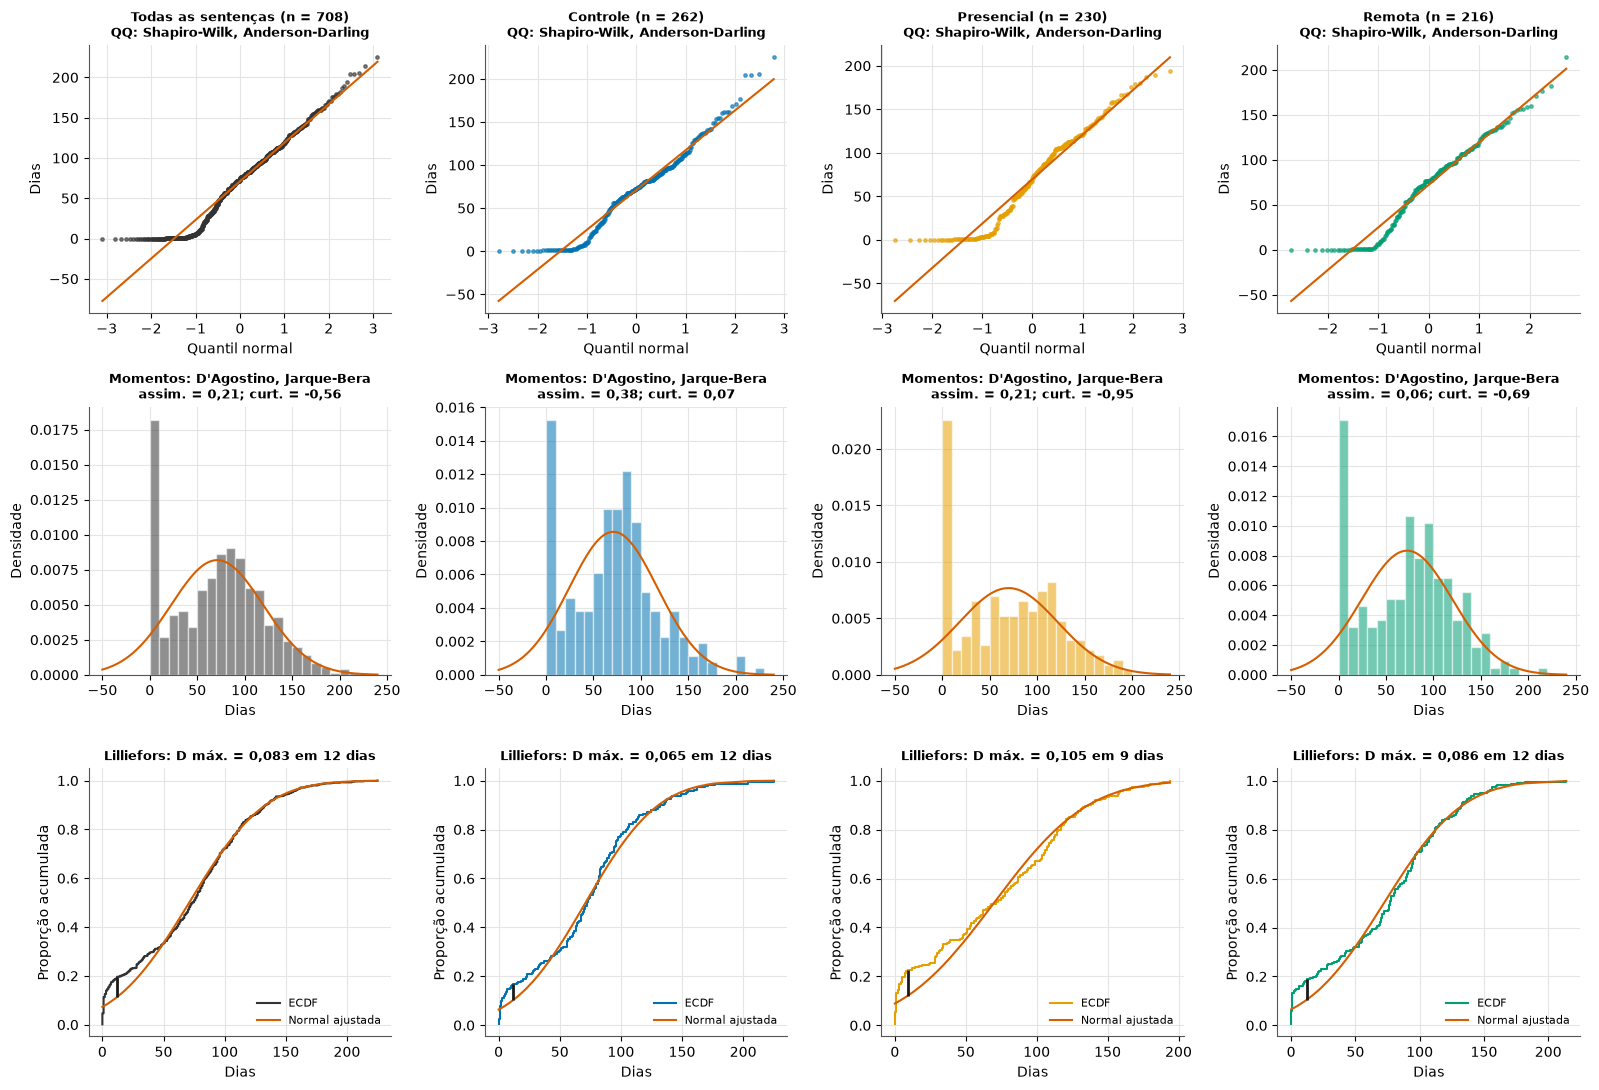

In [47]:
cores_amostra = {'Todas as sentenças': '#333333'} | CORES_GRUPO
fig, ax = plt.subplots(3, 4, figsize=(16, 11))
for j, (nome, x) in enumerate(AMOSTRAS_NORM.items()):
    x = x.to_numpy(float); cor = cores_amostra[nome]
    (osm, osr), (incl, inter, r) = stats.probplot(x, dist='norm')
    ax[0, j].scatter(osm, osr, s=6, color=cor, alpha=0.6)
    ax[0, j].plot(osm, inter + incl * osm, color='#D55E00')
    ax[0, j].set_title(f'{nome} (n = {len(x)})\nQQ: Shapiro-Wilk, Anderson-Darling', fontsize=9)
    ax[0, j].set_xlabel('Quantil normal'); ax[0, j].set_ylabel('Dias')
    ax[1, j].hist(x, bins=np.arange(0, 240, 10), density=True, color=cor, alpha=0.55, edgecolor='white')
    grade = np.linspace(-50, 240, 300)
    ax[1, j].plot(grade, stats.norm.pdf(grade, x.mean(), x.std(ddof=1)), color='#D55E00')
    ax[1, j].set_title(f'Momentos: D\'Agostino, Jarque-Bera\nassim. = {fmt_br(stats.skew(x, bias=False), 2)}; '
                       f'curt. = {fmt_br(stats.kurtosis(x, bias=False), 2)}', fontsize=9)
    ax[1, j].set_xlabel('Dias'); ax[1, j].set_ylabel('Densidade')
    xs = np.sort(x); ecdf = np.arange(1, len(xs) + 1) / len(xs)
    fi = stats.norm.cdf(xs, x.mean(), x.std(ddof=1))
    k = np.argmax(np.abs(ecdf - fi))
    ax[2, j].step(xs, ecdf, where='post', color=cor, label='ECDF')
    ax[2, j].plot(xs, fi, color='#D55E00', label='Normal ajustada')
    ax[2, j].vlines(xs[k], min(ecdf[k], fi[k]), max(ecdf[k], fi[k]), color=TINTA, lw=2)
    ax[2, j].set_title(f'Lilliefors: D máx. = {fmt_br(abs(ecdf[k] - fi[k]), 3)} em {fmt_br(xs[k], 0)} dias', fontsize=9)
    ax[2, j].set_xlabel('Dias'); ax[2, j].set_ylabel('Proporção acumulada'); ax[2, j].legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

**Leitura. A normalidade é rejeitada, como se esperava, e a rejeição se deve à forma da distribuição, não a um detalhe.**

- **Total das sentenças (n = 708):** os cinco testes rejeitam H0 após Holm (Shapiro-Wilk W = 0,960; D'Agostino K² = 23,2; Anderson-Darling A² = 6,42; Lilliefors D = 0,083; Jarque-Bera JB = 14,7; todos com p ajustado ≤ 0,005).
- **Por grupo:** de 20 testes, 17 rejeitam. Os únicos que não rejeitam são os baseados em momentos (D'Agostino e Jarque-Bera) no Controle e o Jarque-Bera na Remota. Isso é coerente com os gráficos: a assimetria e a curtose desses grupos estão perto de zero (Controle: 0,38 e 0,07; Remota: 0,06 e −0,69), e os testes de momentos não "veem" a bimodalidade. Shapiro-Wilk, Anderson-Darling e Lilliefors, que comparam a forma inteira, rejeitam em todos os grupos.
- **Gráficos.** Os QQ-plots mostram o mesmo patamar junto de zero em todos os grupos (a massa de extinções precoces); os histogramas mostram o pico em 0 a 10 dias separado da moda principal; e a maior distância entre a ECDF e a normal (Lilliefors) está sempre entre 9 e 12 dias, exatamente na transição entre os dois "relógios".
- **Consequências.** (i) A comparação dos tempos dos sentenciados na Parte III deve usar testes não paramétricos (Kruskal-Wallis, Mann-Whitney), e não ANOVA ou teste t; (ii) mais importante, a pergunta relevante para os dados censurados não é a normalidade, mas a forma da função de sobrevivência e do risco, examinada na seção 2.4; (iii) o teste do notebook do professor em uma subamostra de 500 casos com censurados misturados (E22), com Shapiro-Wilk rejeitando e D'Agostino não, refletia essa mesma diferença entre testes de forma e testes de momentos, e não uma ambiguidade dos dados.

## 2.4 Ajuste de distribuições ao tempo **com censura**

**Por que com censura.** O notebook do professor ajustou Weibull, gama, log-normal e exponencial por máxima verossimilhança aos 943 tempos como se fossem todos completos, descartou os zeros e deixou o parâmetro de locação livre (E25). Com censura, a verossimilhança correta é (COLOSIMO; GIOLO, 2006, cap. 3):

L(θ) = ∏ f(tᵢ; θ)^δᵢ · S(tᵢ; θ)^(1 − δᵢ),

em que os sentenciados contribuem com a densidade e os censurados, com a probabilidade de durar **mais** do que o tempo observado. Usa-se `tempo_pos` (zeros → 0,5 dia) e `evento` (redistribuição como censura; a alternativa de riscos competitivos fica para a Parte IV).

**Modelos** (COLOSIMO; GIOLO, 2006, p. 70-81; MORETTIN; SINGER, 2021, p. 246):

| Modelo | Parâmetros | Forma do risco h(t) |
|---|---|---|
| Exponencial | 1 | constante |
| Weibull | 2 | monótona (crescente se ρ > 1) |
| Log-normal | 2 | sobe e depois desce |
| Log-logística | 2 | monótona decrescente ou sobe e desce |
| Gama generalizada | 3 | contém as anteriores (exceto a log-logística) como casos particulares |
| Exponencial por partes | 7 | constante em cada janela (0-15, 15-30, 30-60, 60-90, 90-120, 120-150, > 150 dias): estimativa quase não paramétrica da forma do risco |

**Seleção:** (i) AIC e BIC (menor é melhor; o BIC penaliza mais os parâmetros); (ii) **teste da razão de verossimilhanças (TRV)** dos modelos encaixados na gama generalizada: TRV = 2[log L(gama gen.) − log L(modelo)] ~ χ² com g.l. = diferença de parâmetros (COLOSIMO; GIOLO, 2006, p. 93-94, 100-101). H0: o modelo mais simples é suficiente; H1: a gama generalizada ajusta melhor. A log-logística não é encaixada e só se compara por AIC; (iii) gráficos (p. 96-99).

In [48]:
T_pos = d2['tempo_pos'].astype(float).to_numpy()
E_ev = d2['E'].to_numpy()
n_obs = len(T_pos)
MODELOS = {'Exponencial': ExponentialFitter(), 'Weibull': WeibullFitter(), 'Log-normal': LogNormalFitter(),
           'Log-logística': LogLogisticFitter(), 'Gama generalizada': GeneralizedGammaFitter(),
           'Exponencial por partes': PiecewiseExponentialFitter(breakpoints=[15, 30, 60, 90, 120, 150])}
ajustes = {nome: f.fit(T_pos, E_ev, label=nome) for nome, f in MODELOS.items()}


def mediana_modelo(f, p=0.5):
    # Tempo t com S(t) = p (raiz numérica; o median_survival_time_ do lifelines falha com o numpy atual)
    from scipy.optimize import brentq
    return brentq(lambda t: float(f.survival_function_at_times(np.array([t])).iloc[0]) - p, 1e-6, 5000)


linhas = []
for nome, f in ajustes.items():
    k = len(f.params_)
    linhas.append({'Modelo': nome, 'parâmetros': k, 'log L': f.log_likelihood_, 'AIC': f.AIC_,
                   'BIC': k * np.log(n_obs) - 2 * f.log_likelihood_,
                   'mediana S(t)=0,5 (dias)': mediana_modelo(f),
                   'S(90) (prob. sem sentença aos 90 d)': float(f.survival_function_at_times(np.array([90.0])).iloc[0])})
tab_ajuste = pd.DataFrame(linhas).set_index('Modelo')
tab_ajuste['ΔAIC'] = tab_ajuste['AIC'] - tab_ajuste['AIC'].min()
display(tab_ajuste.round(3))

gg = ajustes['Gama generalizada']
print('Parâmetros da gama generalizada:', gg.params_.round(4).to_dict())
trv = []
for nome, gl in [('Exponencial', 2), ('Weibull', 1), ('Log-normal', 1)]:
    est = 2 * (gg.log_likelihood_ - ajustes[nome].log_likelihood_)
    trv.append({'H0 (modelo encaixado)': nome, 'TRV': est, 'g.l.': gl, 'p': stats.chi2.sf(est, gl)})
tab_trv = pd.DataFrame(trv)
tab_trv['p (Holm)'] = multipletests(tab_trv['p'], method='holm')[1]
display(tab_trv.assign(**{'p': tab_trv['p'].map(p_br), 'p (Holm)': tab_trv['p (Holm)'].map(p_br)}).round(2))

,parâmetros,log L,AIC,BIC,"mediana S(t)=0,5 (dias)",S(90) (prob. sem sentença aos 90 d),ΔAIC
Modelo,,,,,,,
Exponencial,1,-3995.055,7992.109,7996.953,71.968,0.420,209.574
Weibull,2,-3994.962,7993.925,8003.612,71.610,0.420,211.389
Log-normal,2,-4149.788,8303.576,8313.264,62.644,0.421,521.041
Log-logística,2,-4095.338,8194.676,8204.364,76.210,0.454,412.141
Gama generalizada,3,-3916.826,7839.652,7854.183,75.859,0.434,57.116
Exponencial por partes,7,-3884.268,7782.536,7816.442,88.223,0.490,0.000


Parâmetros da gama generalizada: {'mu_': 4.963, 'ln_sigma_': -0.5932, 'lambda_': 2.451}


,H0 (modelo encaixado),TRV,g.l.,p,p (Holm)
0,Exponencial,156.46,2,"< 0,001","< 0,001"
1,Weibull,156.27,1,"< 0,001","< 0,001"
2,Log-normal,465.92,1,"< 0,001","< 0,001"


**Gráficos de adequação.** Cada teste ou critério tem o seu gráfico:

1. **QQ-plots para dados censurados** (`lifelines.plotting.qq_plot`): quantis do modelo contra quantis do KM; pontos sobre a diagonal = bom ajuste. Disponível para os quatro modelos de dois parâmetros ou menos.
2. **Ŝ_KM(t) × Ŝ_modelo(t)** (COLOSIMO; GIOLO, 2006, p. 96-97): para cada tempo de evento, a sobrevivência estimada pelo KM contra a do modelo; o modelo adequado fica perto de y = x. É o gráfico que acompanha o TRV.
3. **Sobreposição das curvas S(t)** paramétricas ao Kaplan-Meier (descendente, com IC de 95%). É só uma verificação visual: a análise do KM, por grupo, está na Parte IV.

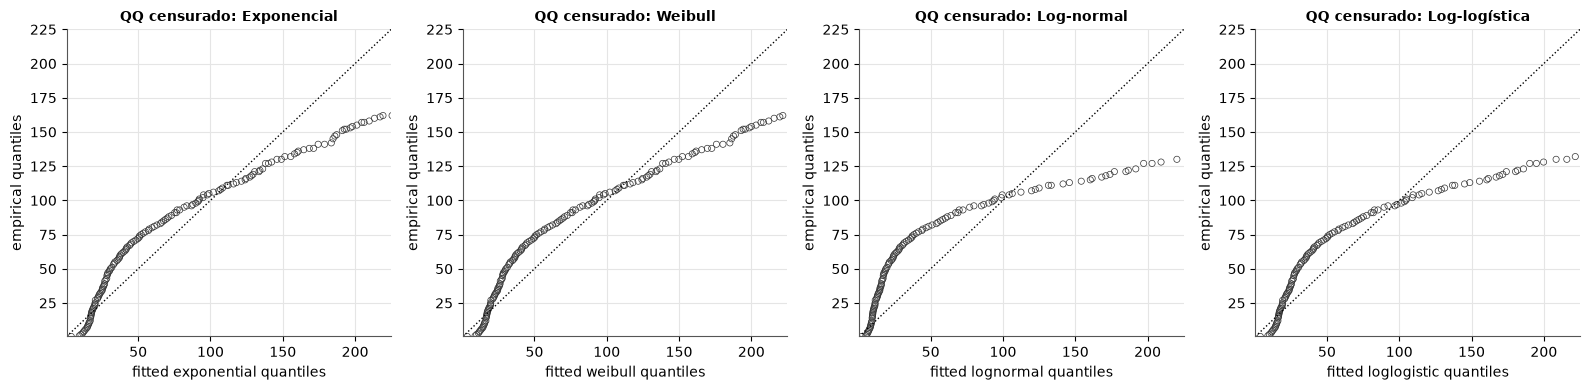

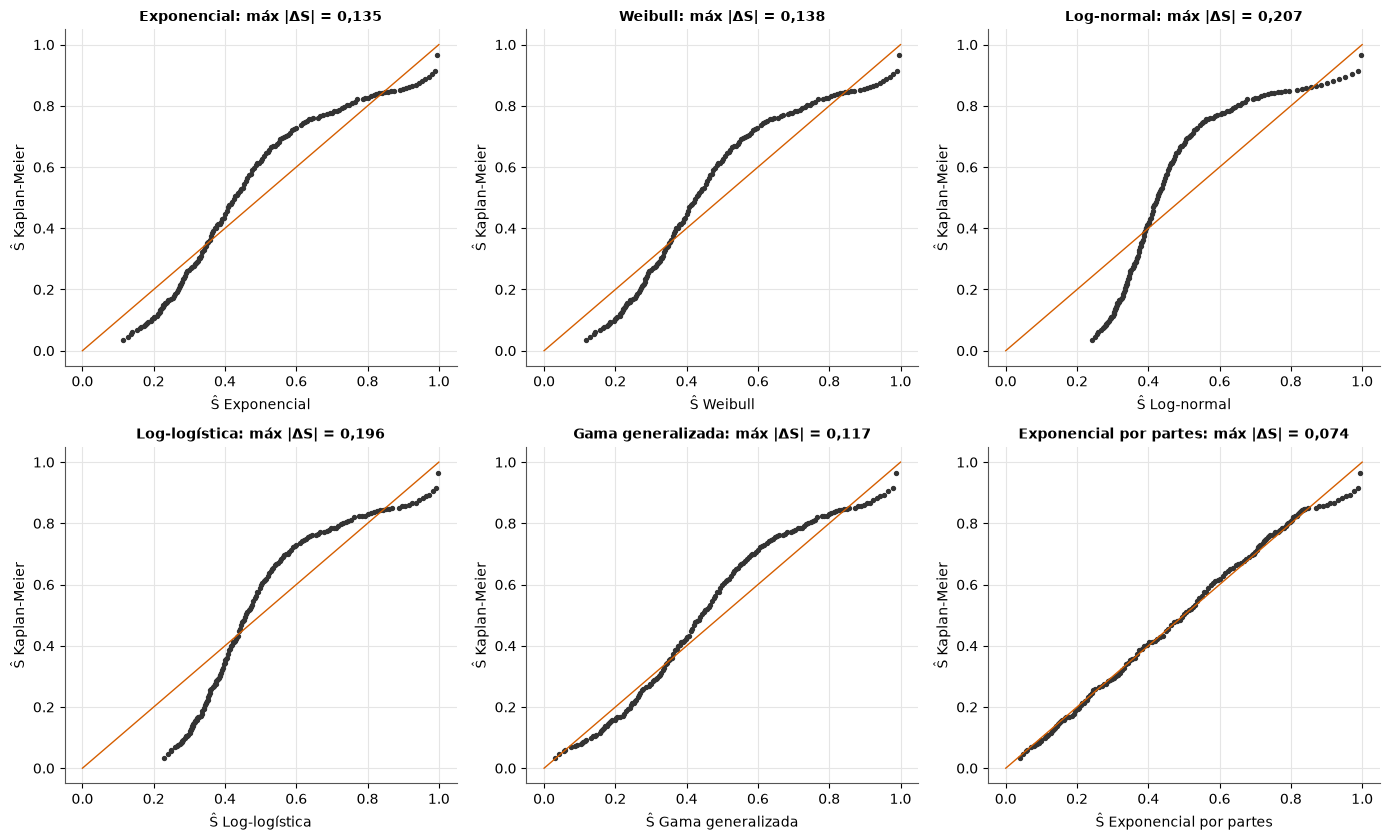

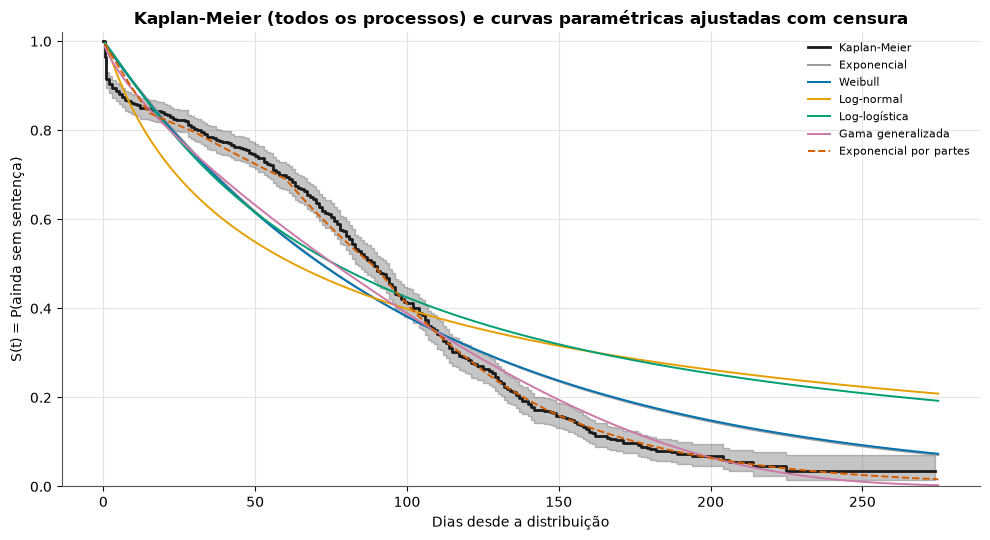

In [49]:
kmf_total = KaplanMeierFitter().fit(T_pos, E_ev, label='Kaplan-Meier')
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, nome in zip(ax, ['Exponencial', 'Weibull', 'Log-normal', 'Log-logística']):
    qq_plot(ajustes[nome], ax=a, scatter_color='#333333')
    a.set_title(f'QQ censurado: {nome}', fontsize=10)
plt.tight_layout()
plt.show()

t_ev = np.sort(np.unique(T_pos[E_ev == 1]))
s_km = kmf_total.survival_function_at_times(t_ev).to_numpy()
fig, ax = plt.subplots(2, 3, figsize=(14, 8.5))
for a, (nome, f) in zip(ax.flat, ajustes.items()):
    s_mod = f.survival_function_at_times(t_ev).to_numpy()
    a.scatter(s_mod, s_km, s=8, color='#333333')
    a.plot([0, 1], [0, 1], color='#D55E00', lw=1)
    a.set_xlabel(f'Ŝ {nome}'); a.set_ylabel('Ŝ Kaplan-Meier')
    a.set_title(f'{nome}: máx |ΔS| = {fmt_br(np.max(np.abs(s_mod - s_km)), 3)}', fontsize=10)
plt.tight_layout()
plt.show()

CORES_MOD = {'Exponencial': '#999999', 'Weibull': '#0072B2', 'Log-normal': '#E69F00', 'Log-logística': '#009E73',
             'Gama generalizada': '#CC79A7', 'Exponencial por partes': '#D55E00'}
fig, ax = plt.subplots(figsize=(10, 5.5))
kmf_total.plot_survival_function(ax=ax, color=TINTA, lw=2, ci_show=True)
grade = np.linspace(0.5, 275, 400)
for nome, f in ajustes.items():
    ax.plot(grade, f.survival_function_at_times(grade), color=CORES_MOD[nome], lw=1.4,
            ls='--' if nome == 'Exponencial por partes' else '-', label=nome)
ax.set_xlabel('Dias desde a distribuição'); ax.set_ylabel('S(t) = P(ainda sem sentença)')
ax.set_title('Kaplan-Meier (todos os processos) e curvas paramétricas ajustadas com censura')
ax.set_ylim(0, 1.02); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Leitura. Nenhuma distribuição paramétrica usual descreve bem o tempo até a sentença; a forma do risco é não monótona.**

- **Critérios de informação.** A exponencial por partes (7 parâmetros) tem o menor AIC (7.782,5) e o menor BIC (7.816,4). Entre os paramétricos, a gama generalizada é a melhor (AIC 7.839,7; ΔAIC = 57), seguida de longe pela exponencial (7.992,1) e pela Weibull (7.993,9), que são praticamente o mesmo modelo (o parâmetro de forma da Weibull é ≈ 1). A log-logística (8.194,7) e a log-normal (8.303,6) são as piores.
- **TRV.** A gama generalizada rejeita os três modelos encaixados: contra a exponencial, TRV = 156,5 com 2 g.l.; contra a Weibull, 156,3 com 1 g.l.; contra a log-normal, 465,9 com 1 g.l. (todos p < 0,001, também após Holm). O parâmetro λ estimado (2,45) está longe tanto de 1 (Weibull) quanto de 0 (log-normal) (COLOSIMO; GIOLO, 2006, p. 93-94).
- **Gráficos.** Os QQ-plots com censura e os gráficos Ŝ_KM × Ŝ_modelo têm a forma de "S" em todos os modelos de 2 parâmetros: o maior afastamento entre o KM e o modelo é de 0,135 (exponencial), 0,138 (Weibull), 0,196 (log-logística) e 0,207 (log-normal). A gama generalizada reduz para 0,117, e só a exponencial por partes acompanha o KM de perto (0,074). Na sobreposição de curvas, os modelos de 2 parâmetros cruzam o KM: subestimam S(t) entre 20 e 100 dias e a superestimam depois de 120 dias.
- **Medianas implícitas.** A exponencial por partes dá 88,2 dias, próxima da mediana do KM (89); os demais modelos dão de 62,6 (log-normal) a 76,2 (log-logística). Um modelo mal especificado erra, portanto, a quantidade mais importante para a gestão.
- **Consequência.** Os modelos AFT da Parte IV devem ser lidos com cautela e acompanhados de diagnóstico (Cox-Snell); as conclusões principais devem vir de métodos que não impõem forma ao risco (Kaplan-Meier, log-rank, Cox, RMST).

### 2.4.1 Forma da função de risco

A função de risco h(t) é a taxa instantânea de sentença entre os processos ainda sem sentença no dia *t*. Comparam-se: o risco estimado por Nelson-Aalen suavizado (núcleo de 15 dias; não paramétrico), o da exponencial por partes (degraus) e os dos modelos paramétricos. **Como ler:** um risco crescente significa que, quanto mais antigo o processo, maior a chance de ser sentenciado no dia seguinte (fila que anda); um pico no início indica extinções precoces; um risco que cai na cauda indica processos "travados".

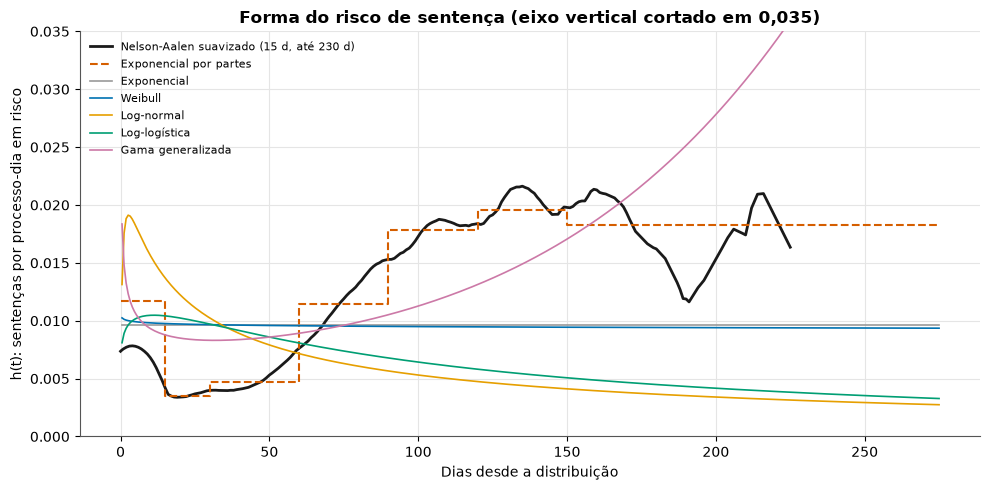

,janela (dias),risco diário,meia-vida na janela (dias)
0,0–15,0.0117,59.2572
1,15–30,0.0035,198.6076
2,30–60,0.0047,146.0906
3,60–90,0.0114,60.5666
4,90–120,0.0178,38.9085
5,120–150,0.0196,35.4309
6,150–275,0.0183,37.9278


In [50]:
naf = NelsonAalenFitter().fit(T_pos, E_ev)
h_suave = naf.smoothed_hazard_(bandwidth=15)
pwe = ajustes['Exponencial por partes']
fig, ax = plt.subplots(figsize=(10, 5))
h_suave = h_suave[h_suave.index <= 230]   # o núcleo perde suporte na cauda (poucos processos em risco)
ax.plot(h_suave.index, h_suave.iloc[:, 0], color=TINTA, lw=2, label='Nelson-Aalen suavizado (15 d, até 230 d)')
cortes_pwe = [0] + [float(b) for b in pwe.breakpoints if np.isfinite(b)] + [275]
taxas = 1 / pwe.summary.loc[[p for p in pwe.summary.index if p.startswith('lambda_')], 'coef'].to_numpy()
ax.step(cortes_pwe, list(taxas) + [taxas[-1]], where='post', color='#D55E00', ls='--', lw=1.5, label='Exponencial por partes')
for nome in ['Exponencial', 'Weibull', 'Log-normal', 'Log-logística', 'Gama generalizada']:
    ax.plot(grade, ajustes[nome].hazard_at_times(grade), color=CORES_MOD[nome], lw=1.2, label=nome)
ax.set_xlabel('Dias desde a distribuição'); ax.set_ylabel('h(t): sentenças por processo-dia em risco')
ax.set_title('Forma do risco de sentença (eixo vertical cortado em 0,035)'); ax.set_ylim(0, 0.035)
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()
tab_pwe = pd.DataFrame({'janela (dias)': [f'{a:g}–{b:g}' for a, b in zip(cortes_pwe[:-1], cortes_pwe[1:])],
                        'risco diário': taxas, 'meia-vida na janela (dias)': np.log(2) / taxas})
display(tab_pwe.round(4))

**Leitura. O risco de sentença tem três fases.**

1. **0 a 15 dias: pico inicial** (≈ 0,0117 sentença por processo-dia), produzido pelas extinções imediatas sem mérito e pelas redistribuições;
2. **15 a 60 dias: vale** (0,0035 a 0,0047), o período em que o processo "espera" a citação, a contestação ou a pauta da audiência; quase ninguém é sentenciado;
3. **depois de 60 dias: subida e platô** (0,0114 entre 60 e 90 dias; 0,018 a 0,020 após 90 dias), quando os processos chegam à conclusão para sentença. Nesse platô, a meia-vida é de 35 a 39 dias: metade dos processos ainda sem sentença aos 90 dias é sentenciada em pouco mais de um mês.

Essa forma em "banheira invertida e depois subida" não pertence a nenhuma família padrão: a exponencial e a Weibull impõem um risco constante (≈ 0,0097); a log-normal e a log-logística, um risco que cai depois do início (o oposto do observado); e a gama generalizada capta a subida, mas a extrapola sem limite após 150 dias. Juridicamente, o vale entre 15 e 60 dias é o tempo processual mínimo do contraditório (citação, prazo de defesa e, nos tratados, a audiência). É nesse trecho que a AC obrigatória pode alongar o rito, o que se verifica na seção 2.6.1 e na Parte IV. Quando os riscos de dois grupos mudam de ordem ao longo do tempo, o log-rank perde poder, o que justifica testes ponderados e o RMST na Parte IV.

### 2.4.2 Comparação: ajuste ingênuo só com os sentenciados (`scipy.stats`)

Para mostrar o que muda, ajustam-se as mesmas famílias (exponencial, Weibull, gama, log-normal e log-logística, todas com locação fixa em zero, `floc = 0`) **apenas às 708 sentenças**, como se fossem a população. O teste de Kolmogorov-Smirnov (H0: as sentenças seguem a distribuição ajustada) é exibido com a ressalva de que, com parâmetros estimados nos mesmos dados, o p-valor do KS é conservador (é o problema que o Lilliefors corrige para a normal). O ponto principal é a **mediana implícita**: o ajuste só nos sentenciados descreve a distribuição *condicional* e subestima a duração, porque ignora os 230 processos que ainda não terminaram. O ajuste com censura (seção 2.4) é o correto.

,log L,AIC,KS D,KS p,mediana (só sentenças),mediana (ajuste com censura),ΔAIC
Família,,,,,,,
Exponencial,-3725.984,7453.969,0.183,"< 0,001",49.214,71.968,5.123
Weibull,-3725.277,7454.554,0.175,"< 0,001",50.508,71.610,5.708
Gama,-3722.423,7448.846,0.198,"< 0,001",46.736,NaN,0.000
Log-normal,-3912.890,7829.780,0.247,"< 0,001",36.644,62.644,380.934
Log-logística,-3876.719,7757.437,0.175,"< 0,001",51.538,76.210,308.591


Mediana empírica das sentenças: 73,5 dias | mediana do KM (todos, com censura): 89,0 dias


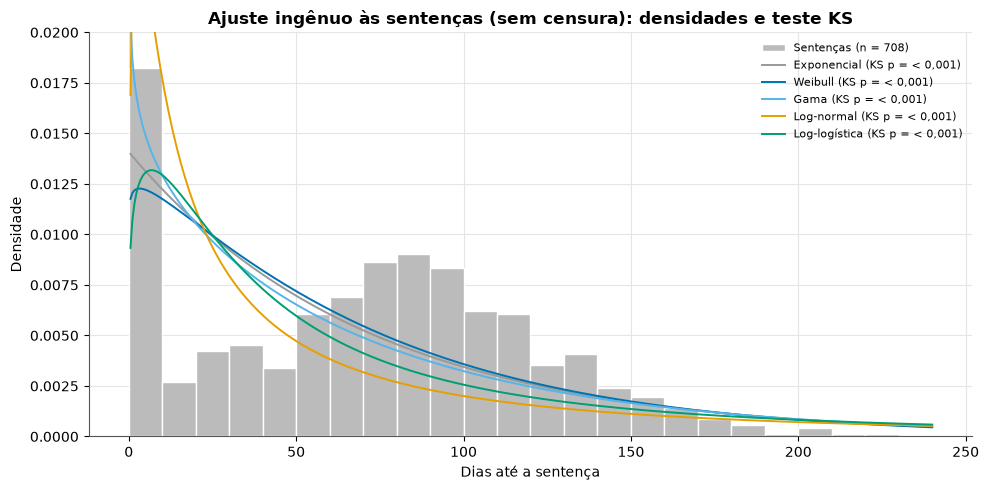

In [51]:
x_sent = sent['tempo_pos'].to_numpy(float)
FAMILIAS = {'Exponencial': stats.expon, 'Weibull': stats.weibull_min, 'Gama': stats.gamma,
            'Log-normal': stats.lognorm, 'Log-logística': stats.fisk}
linhas, dens = [], {}
for nome, dist in FAMILIAS.items():
    par = dist.fit(x_sent, floc=0)
    ll = dist.logpdf(x_sent, *par).sum()
    k = len(par) - 1
    ks = stats.kstest(x_sent, dist.cdf, args=par)
    mediana_cens = mediana_modelo(ajustes[nome]) if nome in ajustes else np.nan
    linhas.append({'Família': nome, 'log L': ll, 'AIC': 2 * k - 2 * ll, 'KS D': ks.statistic, 'KS p': ks.pvalue,
                   'mediana (só sentenças)': dist.median(*par), 'mediana (ajuste com censura)': mediana_cens})
    dens[nome] = (dist, par)
tab_scipy = pd.DataFrame(linhas).set_index('Família')
tab_scipy['ΔAIC'] = tab_scipy['AIC'] - tab_scipy['AIC'].min()
display(tab_scipy.round(3).assign(**{'KS p': tab_scipy['KS p'].map(p_br)}))
print(f'Mediana empírica das sentenças: {fmt_br(np.median(x_sent))} dias | '
      f'mediana do KM (todos, com censura): {fmt_br(kmf_total.median_survival_time_)} dias')

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(x_sent, bins=np.arange(0, 240, 10), density=True, color='#bbbbbb', edgecolor='white', label='Sentenças (n = 708)')
grade2 = np.linspace(0.5, 240, 400)
for nome, (dist, par) in dens.items():
    ax.plot(grade2, dist.pdf(grade2, *par), lw=1.4, color=CORES_MOD.get(nome, '#56B4E9'),
            label=f'{nome} (KS p = {p_br(tab_scipy.loc[nome, "KS p"])})')
ax.set_ylim(0, 0.02)
ax.set_xlabel('Dias até a sentença'); ax.set_ylabel('Densidade'); ax.legend(fontsize=8)
ax.set_title('Ajuste ingênuo às sentenças (sem censura): densidades e teste KS')
plt.tight_layout()
plt.show()

**Leitura. Ajustar só os sentenciados produz distribuições "mais rápidas" do que a realidade.**

- Entre os ajustes ingênuos, a gama tem o menor AIC (7.448,8), com a exponencial e a Weibull a menos de 6 pontos; a log-normal e a log-logística ficam muito atrás. Mas **todas** são rejeitadas pelo KS (p < 0,001; D de 0,175 a 0,247), mesmo sendo esse p-valor conservador: nenhuma família unimodal acomoda o pico em zero e a moda em 80 a 100 dias.
- **O viés de seleção aparece nas medianas.** As medianas implícitas dos ajustes só com sentenças vão de 36,6 (log-normal) a 51,5 dias (log-logística); com censura, as mesmas famílias dão de 62,6 a 76,2 dias, e a mediana do KM é de 89 dias. Desprezar os 230 processos não sentenciados subestima a mediana em 15 a 50 dias.
- É por isso que o ajuste do notebook do professor (E25), feito como se todos os tempos fossem completos e sem os zeros, não serve para descrever a duração: ele descreve, no máximo, a distribuição condicional dos processos que já terminaram.

## 2.5 Modelos binomial e multinomial: o desenho e as proporções

Esta seção usa o modelo **binomial** (uma proporção) e o **multinomial** (várias categorias com probabilidades fixadas) para responder a perguntas univariadas sobre o desenho e sobre as taxas. Em cada caso: a hipótese, o teste, o IC e o gráfico. Os ICs de proporção são o **exato de Clopper-Pearson** (conservador, cobertura ≥ 95%) e o **de Wilson** (cobertura mais próxima de 95%, recomendado para proporções pequenas); o IC de Wald (p ± 1,96·EP) é evitado porque falha justamente nas taxas de acordo, próximas de zero.

### 2.5.1 (a) O sorteio produziu grupos equilibrados demais?

**Pergunta.** Se cada processo fosse sorteado de forma independente com probabilidade 1/3 para cada grupo (**aleatorização simples**), os tamanhos dos grupos seguiriam uma multinomial(n; 1/3, 1/3, 1/3). Divisões como **316/314/314** (as 944 linhas brutas) ou **313/314/311** (a base primária de 938) são compatíveis com isso?

- **Teste usual (cauda direita):** qui-quadrado de aderência, H0: p = (1/3, 1/3, 1/3); H1: algum grupo tem probabilidade diferente. Responde "os grupos são desiguais demais?".
- **Teste de "bom demais" (cauda esquerda):** P(X² ≤ X²_obs | H0), calculada **exatamente**, somando a probabilidade multinomial de todas as divisões (a, b, c) com a + b + c = n tão ou mais equilibradas que a observada. Um valor muito pequeno significa que, sob aleatorização simples, uma divisão tão equilibrada seria improvável, o que é evidência de **aleatorização restrita** (em blocos, urna sem reposição ou alternância), compatível com a informação de que o sorteio "seguiu rigorosamente a ordem de chegada" (questão 2.7).

A aleatorização restrita não é um defeito: é prática recomendada para equilibrar os grupos. Mas ela precisa ser documentada, porque (i) muda a análise da sequência (teste de corridas, Parte III) e (ii) se os blocos forem pequenos e conhecidos, o próximo grupo fica previsível.

In [52]:
def multinomial_exato(contagens, p=None):
    # Probabilidades exatas, sob multinomial(n; p), de X² <= X²_obs (cauda esquerda) e X² >= X²_obs (direita); k = 3
    contagens = np.asarray(contagens); n = int(contagens.sum())
    p = np.full(3, 1 / 3) if p is None else np.asarray(p)
    esp = n * p
    x2_obs = ((contagens - esp) ** 2 / esp).sum()
    esq = dir_ = 0.0
    for a in range(n + 1):
        b = np.arange(n - a + 1); c = n - a - b
        x2 = (a - esp[0]) ** 2 / esp[0] + (b - esp[1]) ** 2 / esp[1] + (c - esp[2]) ** 2 / esp[2]
        lp = (gammaln(n + 1) - gammaln(a + 1) - gammaln(b + 1) - gammaln(c + 1)
              + a * np.log(p[0]) + b * np.log(p[1]) + c * np.log(p[2]))
        pr = np.exp(lp)
        esq += pr[x2 <= x2_obs + 1e-9].sum()
        dir_ += pr[x2 >= x2_obs - 1e-9].sum()
    return x2_obs, esq, dir_


divisoes = {'944 linhas brutas': brutas['grupo'].value_counts().reindex(ORDEM_GRUPO).to_numpy(),
            '938 processos (base primária)': d2['grupo'].value_counts().reindex(ORDEM_GRUPO).to_numpy()}
linhas = []
for nome, cont in divisoes.items():
    x2, esq, dir_ = multinomial_exato(cont)
    linhas.append({'Base': nome, 'Controle': cont[0], 'Presencial': cont[1], 'Remota': cont[2],
                   'esperado (n/3)': cont.sum() / 3, 'X²': x2, 'p qui-quadrado (dir.)': stats.chi2.sf(x2, 2),
                   'p exato (dir.)': dir_, 'P(divisão tão equilibrada) exata (esq.)': esq,
                   'amplitude máx − mín': cont.max() - cont.min()})
tab_equilibrio = pd.DataFrame(linhas).set_index('Base')
display(tab_equilibrio.round(4))

# Monte Carlo: distribuição da amplitude (máx − mín) sob aleatorização simples
sim = RNG.multinomial(len(d2), [1 / 3] * 3, size=200_000)
amp_sim = sim.max(axis=1) - sim.min(axis=1)
x2_sim = ((sim - len(d2) / 3) ** 2 / (len(d2) / 3)).sum(axis=1)
amp_obs = tab_equilibrio.loc['938 processos (base primária)', 'amplitude máx − mín']
print(f'Monte Carlo (200.000 sorteios simples de 938): P(amplitude ≤ {amp_obs}) = {fmt_br((amp_sim <= amp_obs).mean(), 4)}; '
      f'amplitude mediana = {np.median(amp_sim):.0f} processos; P90 = {np.percentile(amp_sim, 90):.0f}')

,Controle,Presencial,Remota,esperado (n/3),X²,p qui-quadrado (dir.),p exato (dir.),P(divisão tão equilibrada) exata (esq.),amplitude máx − mín
Base,,,,,,,,,
944 linhas brutas,314,316,314,314.6667,0.0085,0.9958,0.9974,0.0052,2
938 processos (base primária),313,314,311,312.6667,0.0149,0.9926,0.9947,0.0105,3


Monte Carlo (200.000 sorteios simples de 938): P(amplitude ≤ 3) = 0,0106; amplitude mediana = 28 processos; P90 = 51


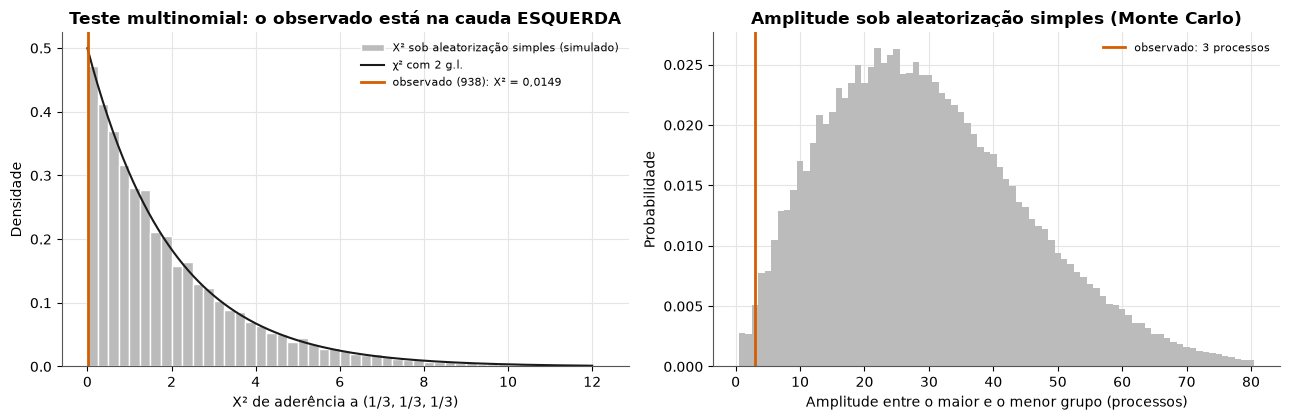

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].hist(x2_sim, bins=np.arange(0, 12.5, 0.25), density=True, color='#bbbbbb', edgecolor='white',
           label='X² sob aleatorização simples (simulado)')
g = np.linspace(0.001, 12, 300)
ax[0].plot(g, stats.chi2.pdf(g, 2), color=TINTA, label='χ² com 2 g.l.')
x2_938 = tab_equilibrio.loc['938 processos (base primária)', 'X²']
ax[0].axvline(x2_938, color='#D55E00', lw=2, label=f'observado (938): X² = {fmt_br(x2_938, 4)}')
ax[0].set_xlabel('X² de aderência a (1/3, 1/3, 1/3)'); ax[0].set_ylabel('Densidade'); ax[0].legend(fontsize=8)
ax[0].set_title('Teste multinomial: o observado está na cauda ESQUERDA')
v, c = np.unique(amp_sim, return_counts=True)
m = v <= 80
ax[1].bar(v[m], c[m] / len(amp_sim), width=1, color='#bbbbbb')
ax[1].axvline(amp_obs, color='#D55E00', lw=2, label=f'observado: {amp_obs} processos')
ax[1].set_xlabel('Amplitude entre o maior e o menor grupo (processos)'); ax[1].set_ylabel('Probabilidade')
ax[1].set_title('Amplitude sob aleatorização simples (Monte Carlo)'); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**O equilíbrio ao longo da sequência.** Se o equilíbrio vier de blocos pequenos, a diferença entre o número acumulado de processos de cada grupo e k/3 (após os k primeiros processos) fica sempre pequena; numa aleatorização simples, ela oscila como um passeio aleatório (da ordem de √k); numa **urna sem reposição** com totais fixados (permutação aleatória de uma lista equilibrada), ela oscila no meio e volta a zero no fim. Calcula-se D = máx_k máx_g |N_g(k) − k/3| e compara-se com 5.000 simulações de cada mecanismo. Em paralelo, o teste de aderência a 1/3 é aplicado **mês a mês** (p exato multinomial, cauda direita, com Holm para 8 meses): blocos pequenos produziriam equilíbrio também dentro dos meses.

D observado = 20,0 processos
Aleatorização simples: D mediano = 21,7; P(D ≤ D_obs) = 0,4156
Urna sem reposição (totais fixos): D mediano = 14,7; P(D ≤ D_obs) = 0,9000


,Controle,Presencial,Remota,n,X²,p exato,p (Holm)
Mês,,,,,,,
jan,37,34,32,103,0.3689,0.8457,1.0000
fev,34,35,37,106,0.1321,0.9546,1.0000
mar,57,50,44,151,1.6821,0.4410,1.0000
abr,47,46,44,137,0.1022,0.9646,1.0000
mai,52,45,49,146,0.5068,0.7889,1.0000
jun,39,59,34,132,7.9545,0.0182,0.1456
jul,46,44,67,157,6.2038,0.0444,0.3108
ago,1,1,4,6,3.0000,0.3827,1.0000


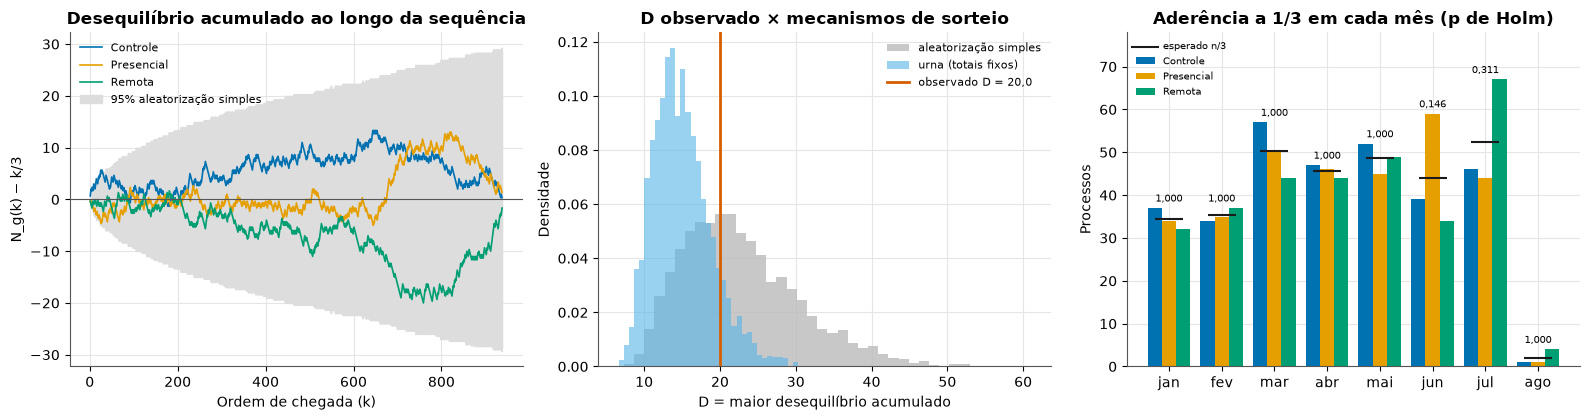

In [54]:
seq = d2.sort_values('ordem_chegada')['grupo'].astype(str).to_numpy()
ind = np.stack([(seq == g) for g in ORDEM_GRUPO], axis=1).astype(float)
k = np.arange(1, len(seq) + 1)[:, None]
desvio_obs = ind.cumsum(axis=0) - k / 3
D_obs = np.abs(desvio_obs).max()

n_sim = 5000
rng_seq = np.random.default_rng(SEMENTE)
sim_simples = rng_seq.integers(0, 3, size=(n_sim, len(seq)))
sim_urna = np.array([rng_seq.permutation(np.repeat([0, 1, 2], [313, 314, 311])) for _ in range(n_sim)])
def estat_D(sims):
    out = np.empty(len(sims))
    for g in range(3):
        dev = np.abs(np.cumsum(sims == g, axis=1) - np.arange(1, sims.shape[1] + 1) / 3).max(axis=1)
        out = dev if g == 0 else np.maximum(out, dev)
    return out
D_simples, D_urna = estat_D(sim_simples), estat_D(sim_urna)
print(f'D observado = {fmt_br(D_obs, 1)} processos')
print(f'Aleatorização simples: D mediano = {fmt_br(np.median(D_simples), 1)}; P(D ≤ D_obs) = {fmt_br((D_simples <= D_obs).mean(), 4)}')
print(f'Urna sem reposição (totais fixos): D mediano = {fmt_br(np.median(D_urna), 1)}; P(D ≤ D_obs) = {fmt_br((D_urna <= D_obs).mean(), 4)}')

linhas = []
for mes in MESES:
    cont = cont_mes.loc[mes].to_numpy()
    x2, _, p_dir = multinomial_exato(cont)
    linhas.append({'Mês': mes, 'Controle': cont[0], 'Presencial': cont[1], 'Remota': cont[2], 'n': cont.sum(),
                   'X²': x2, 'p exato': p_dir})
tab_mes_gof = pd.DataFrame(linhas).set_index('Mês')
tab_mes_gof['p (Holm)'] = multipletests(tab_mes_gof['p exato'], method='holm')[1]
display(tab_mes_gof.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for j, g in enumerate(ORDEM_GRUPO):
    ax[0].plot(k[:, 0], desvio_obs[:, j], color=CORES_GRUPO[g], lw=1.2, label=g)
env = np.percentile(np.abs(np.cumsum(sim_simples == 0, axis=1) - np.arange(1, len(seq) + 1) / 3), 95, axis=0)
ax[0].fill_between(k[:, 0], -env, env, color='#dddddd', label='95% aleatorização simples')
ax[0].axhline(0, color=TINTA_2, lw=0.8)
ax[0].set_xlabel('Ordem de chegada (k)'); ax[0].set_ylabel('N_g(k) − k/3'); ax[0].legend(fontsize=8)
ax[0].set_title('Desequilíbrio acumulado ao longo da sequência')
ax[1].hist(D_simples, bins=40, color='#bbbbbb', density=True, alpha=0.8, label='aleatorização simples')
ax[1].hist(D_urna, bins=40, color='#56B4E9', density=True, alpha=0.6, label='urna (totais fixos)')
ax[1].axvline(D_obs, color='#D55E00', lw=2, label=f'observado D = {fmt_br(D_obs, 1)}')
ax[1].set_xlabel('D = maior desequilíbrio acumulado'); ax[1].set_ylabel('Densidade'); ax[1].legend(fontsize=8)
ax[1].set_title('D observado × mecanismos de sorteio')
x = np.arange(len(MESES)); w = 0.27
for j, g in enumerate(ORDEM_GRUPO):
    ax[2].bar(x + (j - 1) * w, tab_mes_gof[g], width=w, color=CORES_GRUPO[g], label=g)
ax[2].scatter(x, tab_mes_gof['n'] / 3, marker='_', s=400, color=TINTA, label='esperado n/3', zorder=5)
for xi, mes in zip(x, MESES):
    ax[2].text(xi, tab_mes_gof.loc[mes, ORDEM_GRUPO].max() + 1.5, p_br(tab_mes_gof.loc[mes, 'p (Holm)']),
               ha='center', fontsize=7)
ax[2].set_ylim(0, 78)
ax[2].set_xticks(x, MESES); ax[2].set_ylabel('Processos'); ax[2].legend(fontsize=7, loc='upper left')
ax[2].set_title('Aderência a 1/3 em cada mês (p de Holm)')
plt.tight_layout()
plt.show()

**Leitura. A divisão dos grupos é equilibrada demais para um sorteio simples, mas a sequência não tem a regularidade de blocos pequenos.**

- **Cauda direita (o teste usual):** X² = 0,0085 (944 linhas) e 0,0149 (938) com p ≈ 0,99: nenhum sinal de desequilíbrio.
- **Cauda esquerda ("bom demais"):** sob aleatorização simples, a probabilidade exata de uma divisão tão equilibrada quanto 314/316/314 é de **0,52%**, e quanto 313/314/311, de **1,05%**. Por Monte Carlo, a diferença entre o maior e o menor grupo seria ≤ 3 processos em só 1,06% dos sorteios; a diferença típica seria de 28 processos (P90 = 51). Isso é evidência de **aleatorização restrita**: algum mecanismo garantiu totais iguais.
- **Mas não blocos pequenos.** O desequilíbrio acumulado ao longo da ordem de chegada chega a D = 20 processos. Esse valor é típico tanto da aleatorização simples (mediana 21,7; P(D ≤ 20) = 0,42) quanto de uma urna com totais fixos (mediana 14,7; P(D ≤ 20) = 0,90). Com blocos de 3 ou 6, D nunca passaria de 2 a 4. O gráfico mostra a Remota acumulando um déficit de quase 20 processos até a posição 800 e **recuperando-o de uma vez no fim** (julho: 67 Remotas contra 46 e 44).
- **Mês a mês:** a aderência a 1/3 só é marginal em junho (Presencial 59; p exato = 0,018) e julho (Remota 67; p = 0,044), e nenhuma resiste à correção de Holm (0,146 e 0,311).
- **Leitura conjunta.** O padrão é compatível com um sorteio sem reposição a partir de totais preestabelecidos (por exemplo, uma lista equilibrada embaralhada no sorteio.com.br) ou com uma compensação deliberada no fim do período. As duas hipóteses preservam a validade da comparação, mas precisam ser **documentadas**: a segunda tornaria a alocação de julho parcialmente previsível. Como julho também é o mês de seguimento mais curto, a concentração de Remotas nele reforça a necessidade de ajustar pelo mês (Partes IV e V). O teste de corridas da sequência é feito na Parte III.

### 2.5.2 (b) Taxas de acordo: modelo binomial com referência externa

**Referência documentada.** O resumo expandido informa que o índice de conciliação do 4º JEC no GPS-Jus "sempre oscilou em torno de 13 a 14%, estando atualmente no patamar de **13,3%**", antes do experimento, e que o índice nacional dos JECs era **17,22%** em dez./2025. O índice de conciliação do CNJ é **sentenças homologatórias de acordo ÷ total de sentenças**; portanto, a comparação legítima usa o mesmo denominador: homologações entre as sentenças proferidas (não entre os processos distribuídos, como no resumo expandido, que dava 8,06%).

**Testes** (binomial exato bilateral, um por linha):

1. **Homologações / sentenças**, no total e por grupo. H0: p = 0,133 (patamar histórico da unidade); H1: p ≠ 0,133. Pergunta: o índice de conciliação durante o experimento difere do patamar histórico? Ressalva: só as sentenças até 07/10 entram; como os acordos tendem a encerrar processos mais cedo, o índice pode cair à medida que as sentenças de mérito dos ativos forem proferidas.
2. **Acordos na AC / AC realizadas**, por grupo de tratamento. H0: p = 0,133; H1: p ≠ 0,133. Pergunta: a audiência, sozinha, alcança o patamar histórico de conciliação da unidade? É uma comparação de ordem de grandeza (os denominadores são diferentes: audiências × sentenças), mas é a pergunta que o desenho do experimento implicitamente faz.

Holm dentro de cada família (4 e 3 testes). A comparação **entre** grupos (Fisher, qui-quadrado) é da Parte III.

,k,n,p̂,H0: p,IC95% Clopper-Pearson,IC95% Wilson,p,p (Holm)
Proporção,,,,,,,,
Homologações/sentenças — Todos,81,708,"11,4%","13,3%","9,2% a 14,0%","9,3% a 14,0%","0,150","0,451"
Homologações/sentenças — Controle,21,262,"8,0%","13,3%","5,0% a 12,0%","5,3% a 11,9%","0,011","0,042"
Homologações/sentenças — Presencial,25,230,"10,9%","13,3%","7,2% a 15,6%","7,5% a 15,6%","0,331","0,456"
Homologações/sentenças — Remota,35,216,"16,2%","13,3%","11,6% a 21,8%","11,9% a 21,7%","0,228","0,456"
Acordo na AC/AC realizadas — P + R,17,352,"4,8%","13,3%","2,8% a 7,6%","3,0% a 7,6%","< 0,001","< 0,001"
Acordo na AC/AC realizadas — Presencial,9,178,"5,1%","13,3%","2,3% a 9,4%","2,7% a 9,3%","< 0,001","< 0,001"
Acordo na AC/AC realizadas — Remota,8,174,"4,6%","13,3%","2,0% a 8,9%","2,3% a 8,8%","< 0,001","< 0,001"


Para comparação: acordos/processos distribuídos (denominador do resumo expandido) = 81/938 = 8,6% (inclui ativos no denominador)


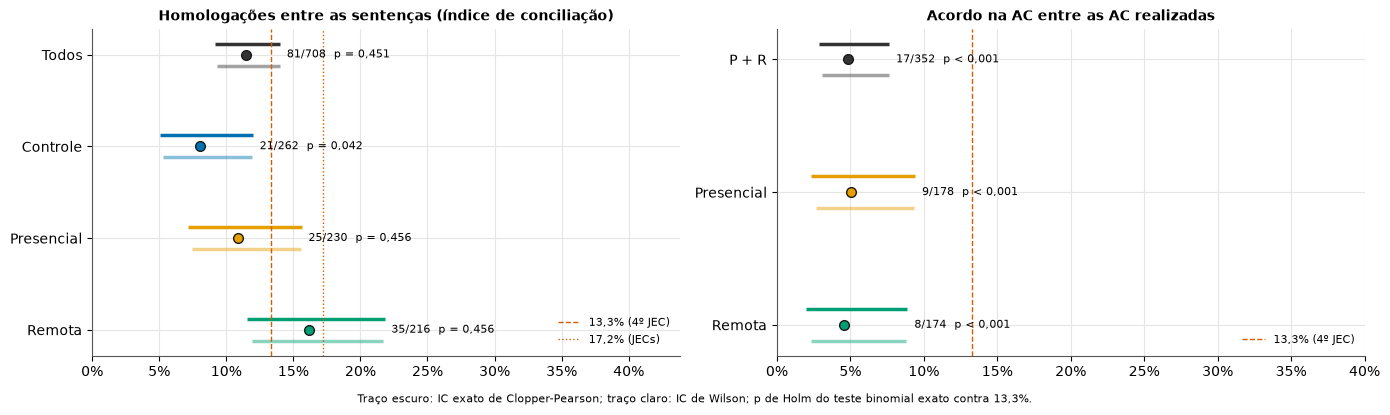

In [55]:
P0_UNIDADE, P0_NACIONAL = 0.133, 0.1722

def linha_binomial(rotulo, k, n, p0):
    bt = stats.binomtest(int(k), int(n), p0)
    cp = bt.proportion_ci(confidence_level=0.95, method='exact')
    wi = bt.proportion_ci(confidence_level=0.95, method='wilson')
    return {'Proporção': rotulo, 'k': int(k), 'n': int(n), 'p̂': k / n, 'H0: p': p0,
            'IC95% Clopper-Pearson': (cp.low, cp.high), 'IC95% Wilson': (wi.low, wi.high), 'p': bt.pvalue}

fam1 = []
for g in [None] + ORDEM_GRUPO:
    s = sent if g is None else sent[sent.grupo.eq(g)]
    fam1.append(linha_binomial(f'Homologações/sentenças — {"Todos" if g is None else g}',
                               s.tipo_desfecho.eq('Homologação').sum(), len(s), P0_UNIDADE))
fam2 = []
for g in [None, 'Presencial', 'Remota']:
    s = ac if g is None else ac[ac.grupo.eq(g)]
    fam2.append(linha_binomial(f'Acordo na AC/AC realizadas — {"P + R" if g is None else g}',
                               s.acordo_ac.sum(), len(s), P0_UNIDADE))
tab_bin = []
for fam in (fam1, fam2):
    t = pd.DataFrame(fam)
    t['p (Holm)'] = multipletests(t['p'], method='holm')[1]
    tab_bin.append(t)
tab_bin = pd.concat(tab_bin, ignore_index=True)

def fmt_ic(ic):
    return f'{pct_br(ic[0])} a {pct_br(ic[1])}'

display(tab_bin.assign(**{'p̂': tab_bin['p̂'].map(pct_br), 'H0: p': tab_bin['H0: p'].map(pct_br),
                          'IC95% Clopper-Pearson': tab_bin['IC95% Clopper-Pearson'].map(fmt_ic),
                          'IC95% Wilson': tab_bin['IC95% Wilson'].map(fmt_ic),
                          'p': tab_bin['p'].map(p_br), 'p (Holm)': tab_bin['p (Holm)'].map(p_br)}).set_index('Proporção'))
print(f'Para comparação: acordos/processos distribuídos (denominador do resumo expandido) = '
      f'{int(d2.acordo.sum())}/{len(d2)} = {pct_br(d2.acordo.sum() / len(d2))} (inclui ativos no denominador)')

def p_txt(p):
    return 'referência' if pd.isna(p) else ('p < 0,001' if p < 0.001 else f'p = {p_br(p)}')


def forest(ax, tab, refs, titulo, cores):
    y = np.arange(len(tab))[::-1]
    for yi, (_, r), c in zip(y, tab.iterrows(), cores):
        ax.hlines(yi + 0.12, *r['IC95% Clopper-Pearson'], color=c, lw=2.5)
        ax.hlines(yi - 0.12, *r['IC95% Wilson'], color=c, lw=2.5, alpha=0.45)
        ax.plot(r['p̂'], yi, 'o', color=c, ms=7, mec=TINTA)
        ax.text(r['IC95% Clopper-Pearson'][1] + 0.005, yi, f"{r['k']}/{r['n']}  {p_txt(r['p (Holm)'])}", va='center', fontsize=8)
    for valor, rot, ls in refs:
        ax.axvline(valor, color='#D55E00', ls=ls, lw=1, label=rot)
    ax.legend(fontsize=8, loc='lower right')
    ax.set_yticks(y, [s.split('— ')[-1] for s in tab['Proporção']])
    ax.set_xlim(0, max(0.3, tab['IC95% Clopper-Pearson'].map(lambda c: c[1]).max() + 0.12) + 0.1)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
    ax.set_title(titulo, fontsize=10)

cores_fam1 = ['#333333'] + [CORES_GRUPO[g] for g in ORDEM_GRUPO]
cores_fam2 = ['#333333', CORES_GRUPO['Presencial'], CORES_GRUPO['Remota']]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
forest(ax[0], tab_bin.iloc[:4], [(P0_UNIDADE, '13,3% (4º JEC)', '--'), (P0_NACIONAL, '17,2% (JECs)', ':')],
       'Homologações entre as sentenças (índice de conciliação)', cores_fam1)
forest(ax[1], tab_bin.iloc[4:], [(P0_UNIDADE, '13,3% (4º JEC)', '--')],
       'Acordo na AC entre as AC realizadas', cores_fam2)
fig.text(0.5, -0.02, 'Traço escuro: IC exato de Clopper-Pearson; traço claro: IC de Wilson; p de Holm do teste binomial exato contra 13,3%.',
         ha='center', fontsize=8)
plt.tight_layout()
plt.show()

**Leitura. O índice de conciliação durante o experimento não difere do patamar histórico; a audiência, sozinha, fica muito abaixo dele.**

- **Índice de conciliação (homologações ÷ sentenças).** No total, 81 de 708 sentenças, ou **11,4%** (IC95% de Clopper-Pearson: 9,2% a 14,0%), compatível com os 13,3% históricos da unidade (p = 0,150; Holm 0,451). Por grupo: Controle **8,0%** (5,0% a 12,0%), abaixo do patamar (p = 0,011; Holm 0,042); Presencial 10,9% (7,2% a 15,6%) e Remota **16,2%** (11,6% a 21,8%), ambas compatíveis com 13,3% (Holm 0,456). Nenhum grupo atinge com segurança o índice nacional dos JECs (17,2%). O IC de Wilson é praticamente igual ao exato em todos os casos.
- **Acordo na AC (acordos ÷ AC realizadas):** 17 de 352, ou **4,8%** (2,8% a 7,6%); Presencial 5,1% (9/178) e Remota 4,6% (8/174), todos muito abaixo de 13,3% (p < 0,001). A comparação de denominadores (audiências × sentenças) é imperfeita, mas a ordem de grandeza é inequívoca: **a audiência inaugural produz cerca de um acordo a cada 20 sessões**.
- **Leitura jurídica.** O que distingue a Remota é o acordo **fora** da audiência (27 dos 35), e não a AC. A hipótese do projeto ("a audiência obrigatória aumenta os índices de conciliação") tem, por ora, apoio fraco e indireto: os grupos tratados têm índice nominalmente maior que o Controle, mas a diferença entre grupos é testada na Parte III, e, como os acordos encerram os processos mais cedo, o índice entre as sentenças já proferidas tende a cair quando as sentenças de mérito dos ativos chegarem. A taxa de 8,06% do resumo expandido (acordos ÷ distribuídos) mistura essa questão com a censura.

**Sentenças sem mérito.** O Controle tem proporcionalmente mais sentenças de mérito e menos extinções sem mérito que os grupos com AC obrigatória. A hipótese jurídica é a do **art. 51, I, da Lei 9.099/1995**: o processo é extinto sem resolução do mérito quando o autor deixa de comparecer a qualquer das audiências. Com a AC obrigatória, surge uma oportunidade de extinção que o rito atual (sem audiência inaugural) não oferece.

**Teste** (binomial exato bilateral): tomando a proporção de sentenças sem mérito do Controle como **referência fixa** (o rito atual), H0: p_grupo = p_Controle; H1: p_grupo ≠ p_Controle, para Presencial e Remota (Holm, 2 testes). Ao fixar a taxa do Controle, ignora-se a sua incerteza; o teste de duas amostras (Fisher/qui-quadrado), que a considera, está na Parte III. A tabela seguinte descreve, nos grupos tratados, a relação entre a extinção sem mérito e a realização da AC.

,k,n,p̂,H0: p,IC95% Clopper-Pearson,IC95% Wilson,p,p (Holm)
Proporção,,,,,,,,
Sem mérito/sentenças — Controle (referência),79,262,"30,2%","30,2%","24,7% a 36,1%","24,9% a 36,0%",–,–
Sem mérito/sentenças — Presencial,109,230,"47,4%","30,2%","40,8% a 54,1%","41,0% a 53,8%","< 0,001","< 0,001"
Sem mérito/sentenças — Remota,98,216,"45,4%","30,2%","38,6% a 52,3%","38,9% a 52,0%","< 0,001","< 0,001"


tipo_desfecho                Homologação  Mérito  Sem mérito  mediana dias (sem mérito)
grupo      AC                                                                          
Presencial AC não realizada           11       2          89                        5.0
           AC realizada               14      94          20                       75.5
Remota     AC não realizada           16       2          63                        6.0
           AC realizada               19      81          35                       81.0

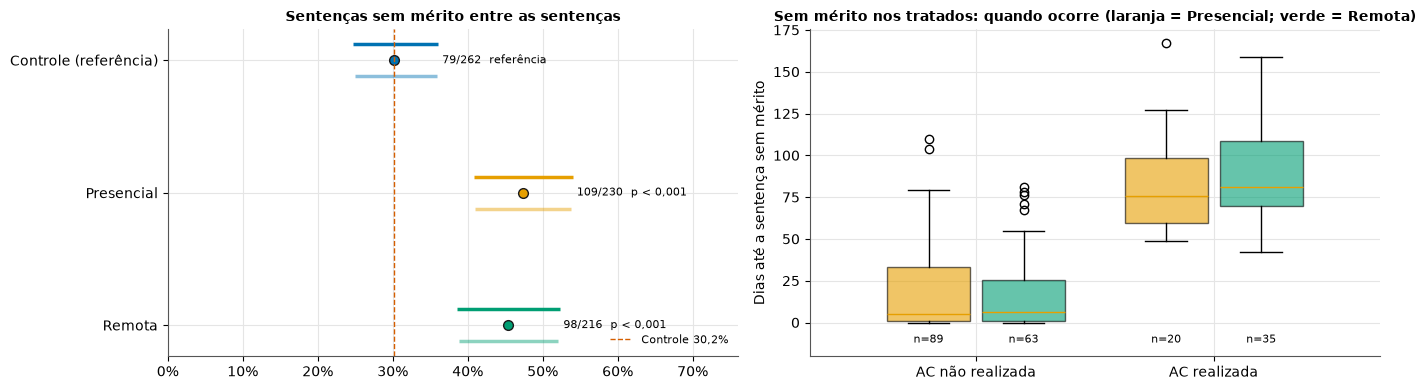

In [56]:
p_ctrl = sent[sent.grupo.eq('Controle')].tipo_desfecho.eq('Sem mérito').mean()
linhas = [linha_binomial(f'Sem mérito/sentenças — Controle (referência)',
                         sent[sent.grupo.eq('Controle')].tipo_desfecho.eq('Sem mérito').sum(),
                         sent.grupo.eq('Controle').sum(), p_ctrl)]
for g in ['Presencial', 'Remota']:
    s = sent[sent.grupo.eq(g)]
    linhas.append(linha_binomial(f'Sem mérito/sentenças — {g}', s.tipo_desfecho.eq('Sem mérito').sum(), len(s), p_ctrl))
tab_sm = pd.DataFrame(linhas)
tab_sm['p (Holm)'] = np.r_[np.nan, multipletests(tab_sm['p'].iloc[1:], method='holm')[1]]
tab_sm.loc[0, 'p'] = np.nan
display(tab_sm.assign(**{'p̂': tab_sm['p̂'].map(pct_br), 'H0: p': tab_sm['H0: p'].map(pct_br),
                         'IC95% Clopper-Pearson': tab_sm['IC95% Clopper-Pearson'].map(fmt_ic),
                         'IC95% Wilson': tab_sm['IC95% Wilson'].map(fmt_ic),
                         'p': tab_sm['p'].map(lambda v: '–' if pd.isna(v) else p_br(v)),
                         'p (Holm)': tab_sm['p (Holm)'].map(lambda v: '–' if pd.isna(v) else p_br(v))}).set_index('Proporção'))

trat = sent[sent.grupo.isin(['Presencial', 'Remota'])].copy()
trat['AC'] = trat['ac_realizada'].map({True: 'AC realizada', False: 'AC não realizada'}).fillna('não informado')
tab_sm_ac = pd.crosstab([trat['grupo'].astype(str), trat['AC']], trat['tipo_desfecho'].astype(str))
tab_sm_ac = tab_sm_ac.reindex(columns=['Homologação', 'Mérito', 'Sem mérito'])
tab_sm_ac['mediana dias (sem mérito)'] = trat[trat.tipo_desfecho.eq('Sem mérito')].groupby(['grupo', 'AC'], observed=True)['T'].median()
display(tab_sm_ac)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
forest(ax[0], tab_sm, [(p_ctrl, f'Controle {pct_br(p_ctrl)}', '--')], 'Sentenças sem mérito entre as sentenças',
       [CORES_GRUPO[g] for g in ORDEM_GRUPO])
for g, desloc in [('Presencial', -0.2), ('Remota', 0.2)]:
    s = trat[trat.grupo.eq(g) & trat.tipo_desfecho.eq('Sem mérito')]
    for i, rot in enumerate(['AC não realizada', 'AC realizada']):
        v = s.loc[s.AC.eq(rot), 'T']
        bpx = ax[1].boxplot([v], positions=[i + desloc], widths=0.35, patch_artist=True)
        bpx['boxes'][0].set_facecolor(CORES_GRUPO[g]); bpx['boxes'][0].set_alpha(0.6)
        ax[1].text(i + desloc, -12, f'n={len(v)}', ha='center', fontsize=8)
ax[1].set_xticks([0, 1], ['AC não realizada', 'AC realizada']); ax[1].set_ylim(-20, None)
ax[1].set_ylabel('Dias até a sentença sem mérito')
ax[1].set_title('Sem mérito nos tratados: quando ocorre (laranja = Presencial; verde = Remota)', fontsize=10)
plt.tight_layout()
plt.show()

**Leitura. Os grupos com AC obrigatória têm uma fração muito maior de sentenças sem mérito, e o excesso está nas extinções precoces.**

- **Proporções.** Sem mérito: Controle **30,2%** das sentenças (79/262; IC95% 24,7% a 36,1%); Presencial **47,4%** (109/230; 40,8% a 54,1%); Remota **45,4%** (98/216; 38,6% a 52,3%). Contra a taxa do Controle tomada como referência, as duas diferenças são muito significativas (p < 0,001 após Holm), e os ICs dos tratados nem tocam o do Controle. São 15 a 17 pontos percentuais a mais: o maior efeito observado em toda a exploração.
- **Quando ocorrem.** Nos tratados, a maioria das extinções sem mérito acontece **sem que a AC tenha ocorrido**: 89 na Presencial e 63 na Remota, com mediana de **5 e 6 dias**. Nos processos com AC realizada, as extinções sem mérito são 20 e 35, com mediana de 75,5 e 81 dias, compatíveis com a extinção na própria audiência ou depois dela.
- **Leitura jurídica.** A hipótese do art. 51, I, da Lei 9.099/1995 (ausência do autor à audiência) explica bem o segundo grupo (55 casos), mas não o primeiro: extinções com 5 a 6 dias de distribuição ocorrem **antes** de qualquer audiência. Elas sugerem que a designação de uma audiência presencial ou remota obrigatória leva parte dos autores a **desistir logo no início** (ou que o despacho inicial dos tratados gera mais indeferimentos e emendas não cumpridas), ao passo que no rito atual o processo segue direto para a citação. Isso altera a composição dos desfechos e, com ela, o tempo médio (seção 2.6.1). O motivo de cada extinção precisa ser conferido no PJe; o teste de duas amostras está na Parte III, e a análise por tipo de desfecho (riscos competitivos), na Parte IV.

### 2.5.3 (c) O sorteio das técnicas de conciliação

**Pergunta.** O protocolo previa o sorteio da técnica em cada audiência. O resumo expandido lista **5** técnicas e afirma que "padrões objetivos" foi a mais usada, com **53,85%**; o professor anotou: "53,85%??? o esperado era 1/5 = 20,0%". O projeto, os apêndices e a planilha têm **6** técnicas (a sexta é "análise da comunicação verbal e não-verbal das partes"). Logo, sob sorteio uniforme, o esperado é **1/6 ≈ 16,7%** para cada uma.

**Testes:**

1. Qui-quadrado de aderência e p exato multinomial por Monte Carlo (200.000 sorteios, estatística X²). H0: as 6 técnicas têm probabilidade 1/6; H1: alguma difere. No total das AC realizadas e em cada grupo (Holm, 3 testes).
2. Binomial exato para "padrões objetivos": H0: p = 1/6 e H0: p = 0,5385 (o valor do resumo expandido).
3. Uma versão com 5 técnicas (1/5), excluída "comunicação verbal e não-verbal", para mostrar o que acontece com o valor esperado do professor.

In [57]:
TECNICAS = list(d2['tecnica_curta'].cat.categories)
def gof_uniforme(cont, n_mc=200_000, semente=SEMENTE):
    cont = np.asarray(cont); n = cont.sum(); kcat = len(cont); esp = n / kcat
    x2 = ((cont - esp) ** 2 / esp).sum()
    sim = np.random.default_rng(semente).multinomial(n, [1 / kcat] * kcat, size=n_mc)
    x2_sim = ((sim - esp) ** 2 / esp).sum(axis=1)
    return x2, stats.chi2.sf(x2, kcat - 1), (x2_sim >= x2 - 1e-9).mean()

linhas = []
for rot, s in [('AC realizadas (P + R)', ac), ('Presencial', ac[ac.grupo.eq('Presencial')]), ('Remota', ac[ac.grupo.eq('Remota')])]:
    cont = s['tecnica_curta'].value_counts().reindex(TECNICAS).to_numpy()
    x2, p_chi, p_mc = gof_uniforme(cont)
    linhas.append({'Amostra': rot, 'n': cont.sum(), **dict(zip(TECNICAS, cont)), 'X² (5 g.l.)': x2,
                   'p qui-quadrado': p_chi, 'p exato (Monte Carlo)': p_mc})
tab_tec = pd.DataFrame(linhas).set_index('Amostra')
tab_tec['p MC (Holm)'] = multipletests(tab_tec['p exato (Monte Carlo)'], method='holm')[1]
display(tab_tec.round(4))

cont5 = ac.loc[ac.tecnica_curta.ne('Comunicação'), 'tecnica_curta'].value_counts().reindex([t for t in TECNICAS if t != 'Comunicação'])
x2_5, p5, p5_mc = gof_uniforme(cont5.to_numpy())
print(f'Versão com 5 técnicas (sem "Comunicação", n = {cont5.sum()}): X² = {fmt_br(x2_5, 2)} (4 g.l.), p = {p_br(p5)}, p MC = {p_br(p5_mc)}')

k_po, n_ac = int(ac.tecnica_curta.eq('Padrões objetivos').sum()), len(ac)
for p0, rot in [(1 / 6, '1/6'), (1 / 5, '1/5'), (0.5385, '53,85%')]:
    bt = stats.binomtest(k_po, n_ac, p0)
    ci = bt.proportion_ci(method='wilson')
    print(f'Padrões objetivos: {k_po}/{n_ac} = {pct_br(k_po / n_ac)} (Wilson {pct_br(ci.low)} a {pct_br(ci.high)}); '
          f'H0: p = {rot} → p = {p_br(bt.pvalue)}')

,n,Desconstrução,Parafraseamento,Separação,Padrões objetivos,Afago,Comunicação,X² (5 g.l.),p qui-quadrado,p exato (Monte Carlo),p MC (Holm)
Amostra,,,,,,,,,,,
AC realizadas (P + R),352,47,57,60,67,58,63,3.9091,0.5626,0.5665,1.0
Presencial,178,25,28,30,32,25,38,4.0899,0.5365,0.5417,1.0
Remota,174,22,29,30,35,33,25,4.0690,0.5395,0.5453,1.0


Versão com 5 técnicas (sem "Comunicação", n = 289): X² = 3,58 (4 g.l.), p = 0,466, p MC = 0,472
Padrões objetivos: 67/352 = 19,0% (Wilson 15,3% a 23,5%); H0: p = 1/6 → p = 0,225
Padrões objetivos: 67/352 = 19,0% (Wilson 15,3% a 23,5%); H0: p = 1/5 → p = 0,690
Padrões objetivos: 67/352 = 19,0% (Wilson 15,3% a 23,5%); H0: p = 53,85% → p = < 0,001


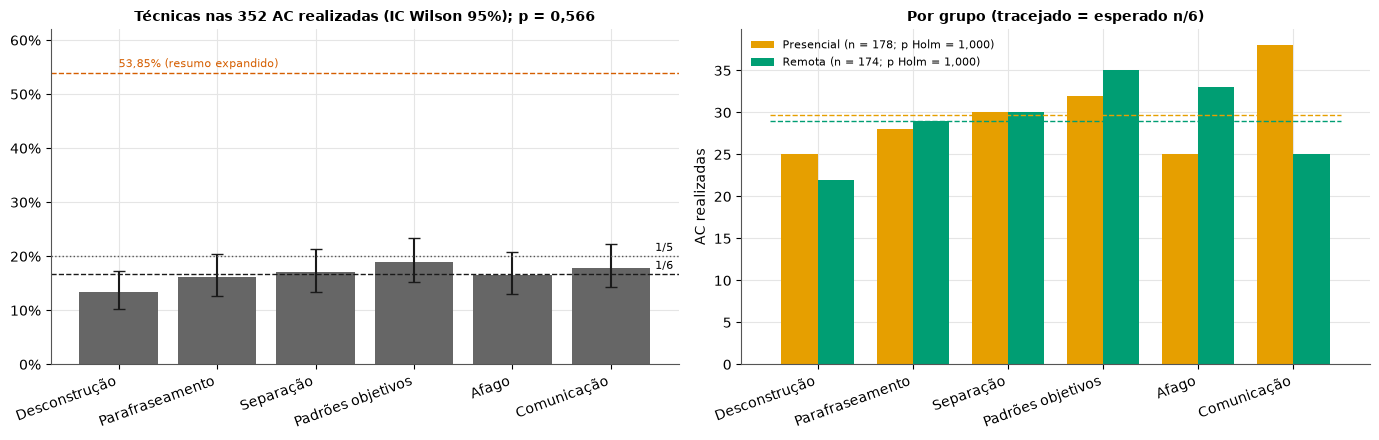

In [58]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cont_tot = ac['tecnica_curta'].value_counts().reindex(TECNICAS)
ic = [stats.binomtest(int(c), n_ac).proportion_ci(method='wilson') for c in cont_tot]
ax[0].bar(range(6), cont_tot / n_ac, color='#666666')
ax[0].errorbar(range(6), cont_tot / n_ac, yerr=[cont_tot / n_ac - [c.low for c in ic], [c.high for c in ic] - cont_tot / n_ac],
               fmt='none', ecolor=TINTA, capsize=4)
ax[0].axhline(1 / 6, color=TINTA, ls='--', lw=1); ax[0].text(5.45, 1 / 6 + 0.01, '1/6', fontsize=8)
ax[0].axhline(1 / 5, color=TINTA_2, ls=':', lw=1); ax[0].text(5.45, 1 / 5 + 0.01, '1/5', fontsize=8)
ax[0].axhline(0.5385, color='#D55E00', ls='--', lw=1); ax[0].text(0, 0.55, '53,85% (resumo expandido)', color='#D55E00', fontsize=8)
ax[0].set_xticks(range(6), TECNICAS, rotation=20, ha='right'); ax[0].set_ylim(0, 0.62)
ax[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax[0].set_title(f'Técnicas nas {n_ac} AC realizadas (IC Wilson 95%); p = {p_br(tab_tec.iloc[0]["p exato (Monte Carlo)"])}', fontsize=10)
w = 0.38
for j, g in enumerate(['Presencial', 'Remota']):
    c = ac.loc[ac.grupo.eq(g), 'tecnica_curta'].value_counts().reindex(TECNICAS)
    ax[1].bar(np.arange(6) + (j - 0.5) * w, c, width=w, color=CORES_GRUPO[g],
              label=f'{g} (n = {c.sum()}; p Holm = {p_br(tab_tec.loc[g, "p MC (Holm)"])})')
    ax[1].hlines(c.sum() / 6, -0.5, 5.5, color=CORES_GRUPO[g], ls='--', lw=1)
ax[1].set_xticks(range(6), TECNICAS, rotation=20, ha='right'); ax[1].set_ylabel('AC realizadas')
ax[1].set_title('Por grupo (tracejado = esperado n/6)', fontsize=10); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Leitura. O sorteio das técnicas é compatível com um sorteio uniforme entre seis técnicas; o "53,85%" do resumo expandido não se confirma.**

- **Aderência a 1/6:** nas 352 AC realizadas, X² = 3,91 com 5 g.l., p = 0,563 (Monte Carlo 0,567). Por grupo: Presencial p = 0,54 e Remota p = 0,55 (Holm = 1,0). As frequências vão de 47 a 67, dentro da variação esperada.
- **"Padrões objetivos":** 67/352 = **19,0%** (IC de Wilson 15,3% a 23,5%), compatível com 1/6 (p = 0,225) e também com 1/5 (p = 0,690), mas incompatível com 53,85% (p < 0,001). O valor do resumo não pode ser reproduzido com nenhum recorte da planilha atual: pode ter vindo de uma tabela dinâmica com outro denominador ou de uma versão anterior dos dados.
- **5 ou 6 técnicas?** A planilha registra seis técnicas, inclusive "Análise da comunicação verbal e não-verbal" (63 audiências; 17,9%). A anotação do professor ("o esperado era 1/5 = 20,0%") parte da lista de cinco técnicas do resumo expandido; o protocolo efetivamente executado usou seis, e o esperado é 1/6 ≈ 16,7%. Excluída a sexta técnica, o teste com 5 categorias também não rejeita (p = 0,466). O texto do resumo deve ser corrigido para seis técnicas.
- **Consequência.** Como o sorteio parece ter funcionado, a comparação de técnicas dentro das AC é um experimento aninhado legítimo; mas com 17 acordos distribuídos em seis técnicas (de 0 a 6 por técnica) o poder é muito baixo (Parte V).

### 2.5.4 (d) Sentenças datadas em fim de semana

**Pergunta.** Se os atos fossem praticados só em dias úteis, nenhuma sentença teria data de sábado ou domingo. A planilha tem desfechos datados em fins de semana (`sentenca_fim_semana`, anomalia A16). Duas referências:

- **"só dias úteis"** (p₀ = 0): basta um caso para refutar; não há teste a fazer, só a contagem;
- **"datas uniformes nos 7 dias"** (p₀ = 2/7 ≈ 28,6%): o que se esperaria se a data da sentença fosse indiferente ao dia da semana (por exemplo, assinatura eletrônica remota no PJe, que funciona todos os dias).

**Teste:** binomial exato bilateral, H0: p = 2/7; H1: p ≠ 2/7, no total dos desfechos e por tipo de desfecho (Holm, 4 tipos). Complemento: a distribuição dos desfechos pelos 7 dias (qui-quadrado de aderência à uniforme). A leitura jurídica: a data registrada é a da **assinatura eletrônica** do ato; sentenças em fim de semana indicam trabalho do magistrado fora do expediente (comum em gabinetes com acervo controlado), não erro de registro, mas a coluna deve ser conferida no PJe.

,k,n,p̂,H0: p,IC95% Clopper-Pearson,IC95% Wilson,p,p (Holm)
Proporção,,,,,,,,
Fim de semana — todos os desfechos,135,732,"18,4%","28,6%","15,7% a 21,4%","15,8% a 21,4%","< 0,001","< 0,001"
Fim de semana — Homologação,9,81,"11,1%","28,6%","5,2% a 20,0%","6,0% a 19,8%","< 0,001","< 0,001"
Fim de semana — Mérito,90,341,"26,4%","28,6%","21,8% a 31,4%","22,0% a 31,3%","0,402","0,402"
Fim de semana — Sem mérito,36,286,"12,6%","28,6%","9,0% a 17,0%","9,2% a 16,9%","< 0,001","< 0,001"
Fim de semana — Redistribuição,0,24,"0,0%","28,6%","0,0% a 14,2%","0,0% a 13,8%","< 0,001","< 0,001"


Desfechos por dia da semana: {'seg': 90, 'ter': 186, 'qua': 149, 'qui': 84, 'sex': 88, 'sáb': 70, 'dom': 65}; aderência à uniforme nos 7 dias: X² = 117,4 (6 g.l.), p = < 0,001


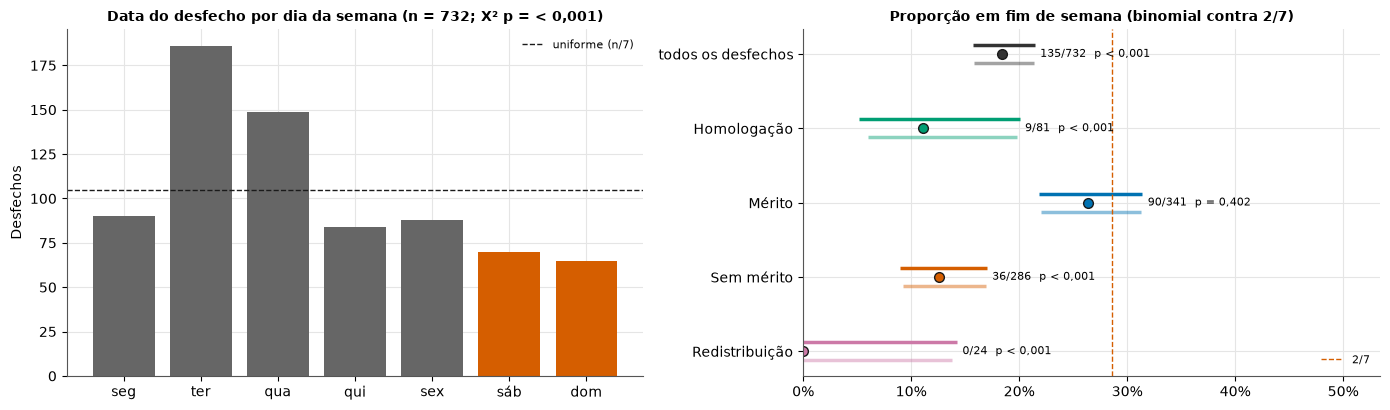

In [59]:
desf = d2[d2['encerrado']].copy()
desf['dia_sem'] = desf['dt_sentenca'].dt.dayofweek
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
linhas = [linha_binomial('Fim de semana — todos os desfechos', desf.dia_sem.ge(5).sum(), len(desf), 2 / 7)]
for t in ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição']:
    s = desf[desf.tipo_desfecho.eq(t)]
    linhas.append(linha_binomial(f'Fim de semana — {t}', s.dia_sem.ge(5).sum(), len(s), 2 / 7))
tab_fds = pd.DataFrame(linhas)
tab_fds['p (Holm)'] = np.r_[tab_fds['p'].iloc[0], multipletests(tab_fds['p'].iloc[1:], method='holm')[1]]
display(tab_fds.assign(**{'p̂': tab_fds['p̂'].map(pct_br), 'H0: p': tab_fds['H0: p'].map(pct_br),
                          'IC95% Clopper-Pearson': tab_fds['IC95% Clopper-Pearson'].map(fmt_ic),
                          'IC95% Wilson': tab_fds['IC95% Wilson'].map(fmt_ic),
                          'p': tab_fds['p'].map(p_br), 'p (Holm)': tab_fds['p (Holm)'].map(p_br)}).set_index('Proporção'))
cont_dia = desf['dia_sem'].value_counts().reindex(range(7), fill_value=0)
x2_dia = stats.chisquare(cont_dia)
print(f'Desfechos por dia da semana: {dict(zip(DIAS, cont_dia.tolist()))}; '
      f'aderência à uniforme nos 7 dias: X² = {fmt_br(x2_dia.statistic, 1)} (6 g.l.), p = {p_br(x2_dia.pvalue)}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(range(7), cont_dia, color=['#666666'] * 5 + ['#D55E00'] * 2)
ax[0].axhline(len(desf) / 7, color=TINTA, ls='--', lw=1, label='uniforme (n/7)')
ax[0].set_xticks(range(7), DIAS); ax[0].set_ylabel('Desfechos'); ax[0].legend(fontsize=8)
ax[0].set_title(f'Data do desfecho por dia da semana (n = {len(desf)}; X² p = {p_br(x2_dia.pvalue)})', fontsize=10)
forest(ax[1], tab_fds, [(2 / 7, '2/7', '--')], 'Proporção em fim de semana (binomial contra 2/7)',
       ['#333333', CORES_DESFECHO['Homologação'], CORES_DESFECHO['Mérito'], CORES_DESFECHO['Sem mérito'],
        CORES_DESFECHO['Redistribuição']])
plt.tight_layout()
plt.show()

**Leitura.**

- **Há desfechos em fins de semana: 135 de 732 (18,4%; IC95% 15,7% a 21,4%).** Se a regra fosse "só dias úteis", qualquer caso a refutaria. A proporção é, porém, menor que a de uma data indiferente ao dia da semana (2/7 = 28,6%; p < 0,001).
- **Depende do tipo de ato.** As sentenças de **mérito** são assinadas em fins de semana na proporção de uma data uniforme (26,4%; p = 0,402): o magistrado redige e assina os julgamentos também aos sábados e domingos. Homologações (11,1%), extinções sem mérito (12,6%) e redistribuições (0 de 24) concentram-se nos dias úteis (p < 0,001 após Holm), o que é coerente com atos de rotina preparados pela secretaria.
- **Dias da semana:** a distribuição dos desfechos está longe da uniforme (X² = 117,4; 6 g.l.; p < 0,001), com um pico na terça-feira (186) e menos atos na segunda (90).
- **Leitura jurídica.** A data registrada é a da **assinatura eletrônica** no PJe, que funciona todos os dias. As sentenças de fim de semana não indicam erro de registro; indicam o ritmo de trabalho do gabinete e confirmam que o momento da sentença está sob controle direto do juiz-pesquisador, limitação de validade interna já apontada (ausência de cegamento). Uma conferência por amostragem no PJe é recomendável.

## 2.6 Análise bivariada

Esta seção é **descritiva**: mostra como o tempo e as categóricas se associam, com medidas de tamanho de efeito, mas sem testes de hipótese (Parte III) nem modelos (Partes IV e V). Duas cautelas atravessam toda a seção:

1. **Toda comparação de tempos entre sentenciados é condicional.** Um grupo com mais processos ativos tem, entre os sentenciados, uma seleção mais "rápida". A comparação correta é a das curvas de sobrevivência (Parte IV).
2. **Variáveis pós-sorteio** (AC realizada, híbrida, técnica, acordo, tipo de desfecho) não são causas exógenas do tempo: elas acontecem durante o processo e, em parte, *definem* o seu fim.

### 2.6.1 Tempo até a sentença × fatores (sentenciados)

Boxplots verticais com o n de cada caixa; o losango é a média. Para cada fator, a tabela traz n, mediana, IIQ e média, e a razão de correlação **η²** = SQ entre / SQ total (a fração da variância dos tempos dos sentenciados "explicada" pelo fator; tamanho de efeito descritivo, sem teste).

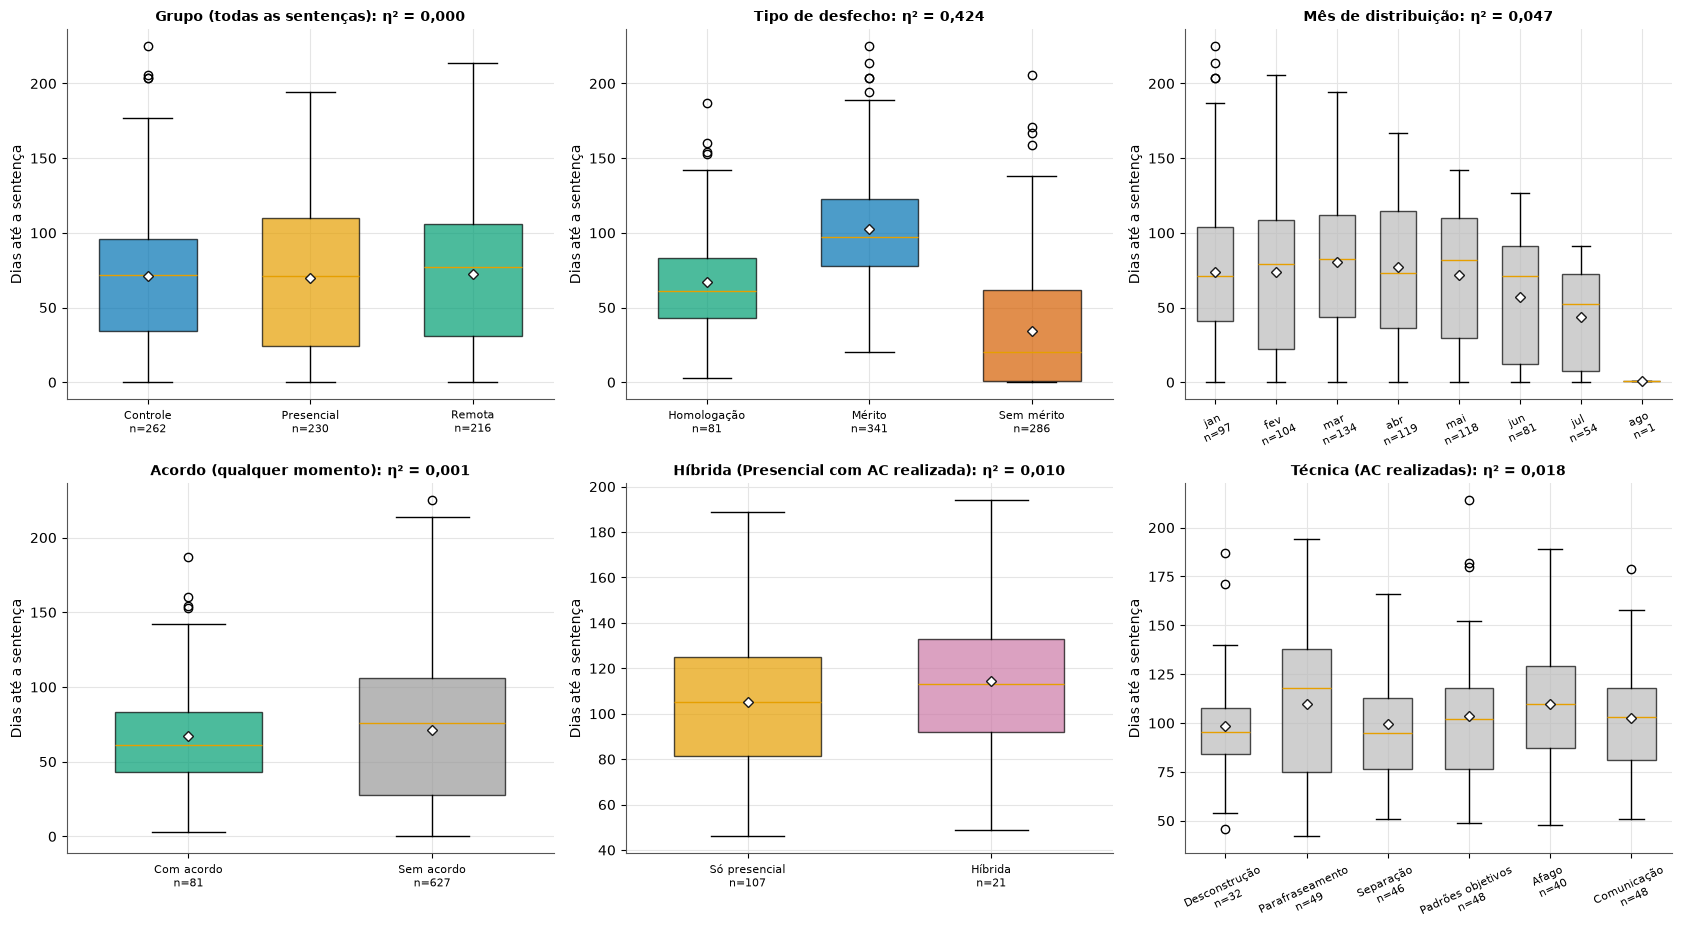

n  mediana    Q1     Q3  média
Fator               Nível                                              
Grupo               Controle           262     72.0  34.2   96.0   71.0
                    Presencial         230     71.0  24.2  110.0   69.8
                    Remota             216     77.0  31.2  106.2   72.2
Tipo de desfecho    Homologação         81     61.0  43.0   83.0   67.4
                    Mérito             341     97.0  78.0  123.0  102.3
                    Sem mérito         286     20.5   1.0   61.8   34.7
Mês de distribuição jan                 97     71.0  41.0  104.0   74.2
                    fev                104     79.5  22.5  108.5   73.8
                    mar                134     82.5  43.5  112.0   80.2
                    abr                119     73.0  36.5  114.5   77.2
                    mai                118     82.0  29.5  110.0   71.7
                    jun                 81     71.0  12.0   91.0   57.3
                    jul                 54     52.5   7.2   72.8   43.5
                    ago                  1      1.0   1.0    1.0    1.0
Acordo              Com acordo          81     61.0  43.0   83.0   67.4
                    Sem acordo         627     76.0  28.0  106.0   71.4
Híbrida             Só presencial      107    105.0  81.5  125.0  105.4
                    Híbrida             21    113.0  92.0  133.0  114.5
Técnica             Desconstrução       32     95.5  84.2  107.5   98.4
                    Parafraseamento     49    118.0  75.0  138.0  109.7
                    Separação           46     95.0  76.5  112.8   99.3
                    Padrões objetivos   48    102.0  76.8  117.8  103.6
                    Afago               40    110.0  87.5  129.2  109.8
                    Comunicação         48    103.0  81.0  118.0  102.5

In [60]:
def eta2(y, g):
    y = pd.Series(np.asarray(y, float)); g = pd.Series(np.asarray(g, object))
    ok = g.notna() & y.notna(); y, g = y[ok], g[ok]
    sqt = ((y - y.mean()) ** 2).sum()
    sqe = y.groupby(g).apply(lambda v: len(v) * (v.mean() - y.mean()) ** 2).sum()
    return sqe / sqt


sent['acordo_txt'] = sent['acordo'].map({True: 'Com acordo', False: 'Sem acordo'})
sent['hibrida_txt'] = sent['hibrida'].map({True: 'Híbrida', False: 'Só presencial'})
FATORES = {   # fator: (coluna, subconjunto, ordem dos níveis, cores, título)
    'Grupo': ('grupo', sent, ORDEM_GRUPO, CORES_GRUPO, 'Grupo (todas as sentenças)'),
    'Tipo de desfecho': ('tipo_desfecho', sent, ['Homologação', 'Mérito', 'Sem mérito'], CORES_DESFECHO, 'Tipo de desfecho'),
    'Mês de distribuição': ('mes_distribuicao', sent, MESES, None, 'Mês de distribuição'),
    'Acordo': ('acordo_txt', sent, ['Com acordo', 'Sem acordo'], {'Com acordo': '#009E73', 'Sem acordo': '#999999'}, 'Acordo (qualquer momento)'),
    'Híbrida': ('hibrida_txt', sent[sent.grupo.eq('Presencial') & sent.ac_realizada.fillna(False).astype(bool)],
                ['Só presencial', 'Híbrida'], {'Só presencial': CORES_GRUPO['Presencial'], 'Híbrida': '#CC79A7'},
                'Híbrida (Presencial com AC realizada)'),
    'Técnica': ('tecnica_curta', sent[sent.ac_realizada.fillna(False).astype(bool)], TECNICAS, None, 'Técnica (AC realizadas)'),
}
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
resumo_fatores, eta_fatores = [], {}
for a, (nome, (col, df, niveis, cores, titulo)) in zip(ax.flat, FATORES.items()):
    grupos = [df.loc[df[col].astype(object).eq(nv), 'T'].to_numpy(float) for nv in niveis]
    bp = a.boxplot(grupos, showmeans=True, widths=0.6, patch_artist=True,
                   meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor=TINTA, ms=5))
    for p, nv in zip(bp['boxes'], niveis):
        p.set_facecolor((cores or {}).get(nv, '#bbbbbb')); p.set_alpha(0.7)
    a.set_xticks(range(1, len(niveis) + 1), [f'{nv}\nn={len(gv)}' for nv, gv in zip(niveis, grupos)], fontsize=8,
                 rotation=0 if len(niveis) < 6 else 25)
    eta_fatores[nome] = eta2(df['T'], df[col].astype(object))
    a.set_title(f'{titulo}: η² = {fmt_br(eta_fatores[nome], 3)}', fontsize=10)
    a.set_ylabel('Dias até a sentença')
    for nv, gv in zip(niveis, grupos):
        resumo_fatores.append({'Fator': nome, 'Nível': nv, 'n': len(gv), 'mediana': np.median(gv) if len(gv) else np.nan,
                               'Q1': np.percentile(gv, 25) if len(gv) else np.nan, 'Q3': np.percentile(gv, 75) if len(gv) else np.nan,
                               'média': gv.mean() if len(gv) else np.nan})
plt.tight_layout()
plt.show()
with pd.option_context('display.max_rows', 100):
    display(pd.DataFrame(resumo_fatores).set_index(['Fator', 'Nível']).round(1))

**Tempo × tipo de desfecho dentro de cada grupo.** Como o tipo de desfecho é o principal determinante do tempo, a tabela cruza grupo e tipo: medianas e n de cada célula. Se as medianas por tipo forem parecidas entre os grupos, a diferença global entre grupos vem da **composição** dos desfechos (mais extinções rápidas aqui, mais mérito ali), e não de um rito "mais rápido" para o mesmo tipo de processo.

In [61]:
tab_gt = sent.groupby(['grupo', 'tipo_desfecho'], observed=True)['T'].agg(['count', 'median', 'mean']).unstack('tipo_desfecho')
tab_gt = tab_gt.loc[:, (slice(None), ['Homologação', 'Mérito', 'Sem mérito'])]
display(tab_gt.round(1))

count                        median                          mean                  
tipo_desfecho Homologação Mérito Sem mérito Homologação Mérito Sem mérito Homologação Mérito Sem mérito
grupo                                                                                                  
Controle               21    162         79        61.0   83.0        9.0        69.8   91.1       30.0
Presencial             25     96        109        57.0  112.5       24.0        66.4  114.4       31.3
Remota                 35     83         98        62.0  106.0       28.5        66.7  110.1       42.1

**Leitura. Entre os sentenciados, o grupo quase não explica o tempo; o tipo de desfecho explica muito, e ele difere entre os grupos.**

- **Grupo:** medianas de 72 (Controle), 71 (Presencial) e 77 dias (Remota); η² = 0,000. Comparar os tempos dos sentenciados por grupo não mostra diferença, mas essa comparação é condicional e enviesada (os tratados têm mais ativos ainda sem sentença).
- **Tipo de desfecho:** η² = 0,424. Mérito tem mediana de 97 dias; homologação, 61; sem mérito, 20,5.
- **Dentro de cada tipo, os tratados são mais lentos.** A mediana das sentenças de mérito é de **83 dias no Controle**, contra **112,5 na Presencial** e **106 na Remota** (médias 91,1 / 114,4 / 110,1); a das extinções sem mérito é de 9, 24 e 28,5 dias. Nas homologações, as medianas são próximas (61, 57 e 62). Como os tratados têm muito mais extinções sem mérito precoces (seção 2.5.2), a mistura dos tipos "compensa" o atraso dos julgamentos de mérito, e as medianas globais ficam iguais. É um caso típico de **efeito de composição** (paradoxo de Simpson), e o tempo "a mais" de 25 a 30 dias no mérito é compatível com a etapa adicional da audiência.
- **Mês:** η² = 0,047; as medianas caem nos meses tardios (jul.: 52,5 dias), por puro efeito de censura (só os rápidos já terminaram).
- **Acordo:** os processos com acordo terminam em 61 dias (mediana), contra 76 sem acordo; η² = 0,001, porque o grupo "sem acordo" mistura extinções imediatas e méritos longos.
- **Híbrida** (Presencial com AC): 113 contra 105 dias (n = 21 e 107; η² = 0,010). **Técnica** (AC realizadas): medianas de 95 a 118 dias, η² = 0,018. Ambas são variáveis pós-sorteio com poucos casos: diferenças descritivas, sem valor causal.

### 2.6.2 Proporção acumulada de sentenças por grupo no calendário

Para cada data do calendário, a fração de cada grupo já sentenciada (sentenças acumuladas ÷ tamanho do grupo) e, em tracejado, a fração já distribuída. É uma visão de **gestão** do acervo (quanto do trabalho de cada rito já foi concluído), não uma curva de sobrevivência: mistura processos de idades diferentes e depende do ritmo de entrada de cada grupo (por exemplo, a concentração de Remotas em julho).

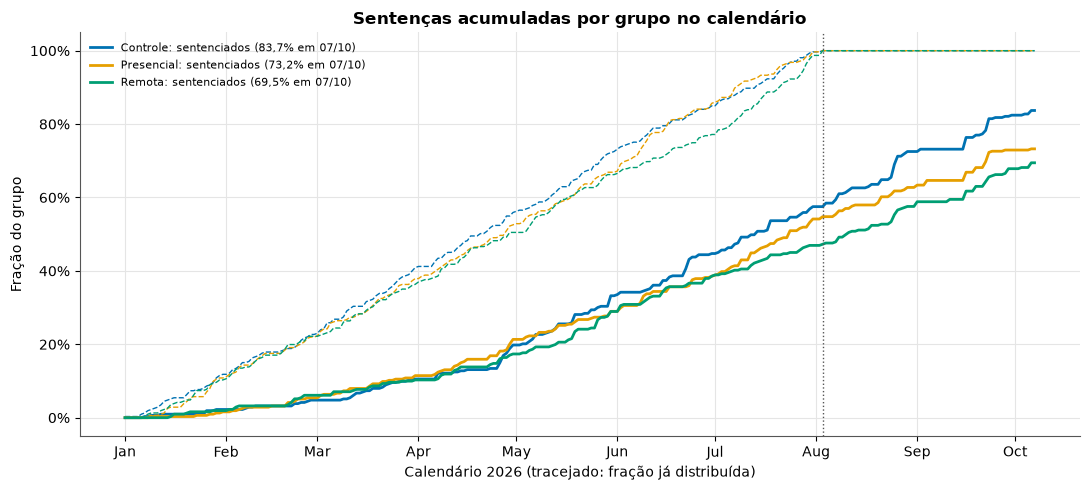

In [62]:
dias_cal = pd.date_range(DATA_INICIO, DATA_CORTE, freq='D')
fig, ax = plt.subplots(figsize=(11, 5))
for g in ORDEM_GRUPO:
    s = d2[d2.grupo.eq(g)]
    n_g = len(s)
    sent_ac = np.searchsorted(np.sort(s.loc[s.E.eq(1), 'dt_sentenca'].to_numpy()), dias_cal.to_numpy(), side='right') / n_g
    dist_ac = np.searchsorted(np.sort(s['dt_distribuicao'].to_numpy()), dias_cal.to_numpy(), side='right') / n_g
    ax.plot(dias_cal, sent_ac, color=CORES_GRUPO[g], lw=2, label=f'{g}: sentenciados ({pct_br(sent_ac[-1])} em 07/10)')
    ax.plot(dias_cal, dist_ac, color=CORES_GRUPO[g], lw=1, ls='--')
ax.axvline(FIM_RECRUTAMENTO, color=TINTA_2, ls=':', lw=1)
ax.set_ylabel('Fração do grupo'); ax.set_xlabel('Calendário 2026 (tracejado: fração já distribuída)')
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%b'))
ax.set_title('Sentenças acumuladas por grupo no calendário'); ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

**Leitura.** Em 07/10/2026, o Controle tinha 83,7% dos seus processos sentenciados (262/313), contra 73,2% da Presencial (230/314) e 69,5% da Remota (216/311). As curvas de sentenças acumuladas andam juntas até maio e se separam a partir de junho, com o Controle à frente. Parte dessa distância é calendário: as linhas tracejadas mostram que a Remota recebeu mais processos no fim (julho), que ainda não tiveram tempo de terminar. Outra parte pode ser efeito do rito (a etapa da audiência). Separar as duas coisas exige comparar processos **da mesma idade**, que é o que fazem o Kaplan-Meier e o Cox com o mês como covariável (Parte IV). A proporção de encerrados por grupo em uma data fixa, usada no notebook do professor (χ² de grupo × situação, E19), não faz essa separação.

### 2.6.3 Tabelas cruzadas e gráficos de mosaico

Para cada par, três versões: contagens, % na linha (distribuição do desfecho *dentro* de cada grupo: a leitura de interesse quando o grupo é a "causa") e % na coluna (de onde vêm os casos de cada categoria). O **mosaico** representa a tabela por áreas: a largura de cada coluna é proporcional ao tamanho do grupo e a altura de cada retângulo, à % na linha; se não houvesse associação, os retângulos se alinhariam em faixas horizontais. A significância e os resíduos ajustados são da Parte III.

- **grupo × tipo de desfecho** (938; inclui Ativo e Redistribuição como situações em 07/10);
- **grupo × acordo** (acordo em qualquer momento; os ativos ficam numa categoria própria, "indefinido");
- **grupo × mês de distribuição** (o calendário do sorteio);
- **técnica × acordo na AC** (352 AC realizadas).

In [63]:
def cruzada(linha, coluna, titulo):
    ct = pd.crosstab(linha, coluna)
    lin = 100 * ct.div(ct.sum(axis=1), axis=0)
    col = 100 * ct.div(ct.sum(axis=0), axis=1)
    display(Markdown(f'**{titulo}**'))
    display(pd.concat({'n': ct, '% na linha': lin.round(1), '% na coluna': col.round(1)}, axis=1))
    return ct

d2['acordo_cat'] = d2['acordo'].map({True: 'Com acordo', False: 'Sem acordo'}).fillna('Indefinido (ativo)')
ac['acordo_ac_txt'] = ac['acordo_ac'].map({True: 'Acordo na AC', False: 'Sem acordo na AC'})
ct_desf = cruzada(d2['grupo'], d2['tipo_desfecho'], 'Grupo × tipo de desfecho')
ct_acordo = cruzada(d2['grupo'], d2['acordo_cat'], 'Grupo × acordo (qualquer momento)')
ct_mes = cruzada(d2['grupo'], d2['mes_distribuicao'], 'Grupo × mês de distribuição')
ct_tec = cruzada(ac['tecnica_curta'].cat.remove_unused_categories(), ac['acordo_ac_txt'], 'Técnica × acordo na AC (AC realizadas)')

**Grupo × tipo de desfecho**

n                                         % na linha                                        % na coluna                                       
tipo_desfecho Homologação Mérito Sem mérito Redistribuição Ativo Homologação Mérito Sem mérito Redistribuição Ativo Homologação Mérito Sem mérito Redistribuição Ativo
grupo                                                                                                                                                                 
Controle               21    162         79              5    46         6.7   51.8       25.2            1.6  14.7        25.9   47.5       27.6           20.8  22.3
Presencial             25     96        109             10    74         8.0   30.6       34.7            3.2  23.6        30.9   28.2       38.1           41.7  35.9
Remota                 35     83         98              9    86        11.3   26.7       31.5            2.9  27.7        43.2   24.3       34.3           37.5  41.7

**Grupo × acordo (qualquer momento)**

n                               % na linha                               % na coluna                              
acordo_cat Com acordo Indefinido (ativo) Sem acordo Com acordo Indefinido (ativo) Sem acordo  Com acordo Indefinido (ativo) Sem acordo
grupo                                                                                                                                 
Controle           21                 46        246        6.7               14.7       78.6        25.9               22.4       37.7
Presencial         25                 74        215        8.0               23.6       68.5        30.9               36.1       33.0
Remota             35                 85        191       11.3               27.3       61.4        43.2               41.5       29.3

**Grupo × mês de distribuição**

n                             % na linha                                          % na coluna                                          
mes_distribuicao jan fev mar abr mai jun jul ago        jan   fev   mar   abr   mai   jun   jul  ago         jan   fev   mar   abr   mai   jun   jul   ago
grupo                                                                                                                                                     
Controle          37  34  57  47  52  39  46   1       11.8  10.9  18.2  15.0  16.6  12.5  14.7  0.3        35.9  32.1  37.7  34.3  35.6  29.5  29.3  16.7
Presencial        34  35  50  46  45  59  44   1       10.8  11.1  15.9  14.6  14.3  18.8  14.0  0.3        33.0  33.0  33.1  33.6  30.8  44.7  28.0  16.7
Remota            32  37  44  44  49  34  67   4       10.3  11.9  14.1  14.1  15.8  10.9  21.5  1.3        31.1  34.9  29.1  32.1  33.6  25.8  42.7  66.7

**Técnica × acordo na AC (AC realizadas)**

n                    % na linha                   % na coluna                 
acordo_ac_txt     Acordo na AC Sem acordo na AC Acordo na AC Sem acordo na AC Acordo na AC Sem acordo na AC
tecnica_curta                                                                                              
Desconstrução                2               45          4.3             95.7         11.8             13.4
Parafraseamento              6               51         10.5             89.5         35.3             15.2
Separação                    5               55          8.3             91.7         29.4             16.4
Padrões objetivos            2               65          3.0             97.0         11.8             19.4
Afago                        0               58          0.0            100.0          0.0             17.3
Comunicação                  2               61          3.2             96.8         11.8             18.2

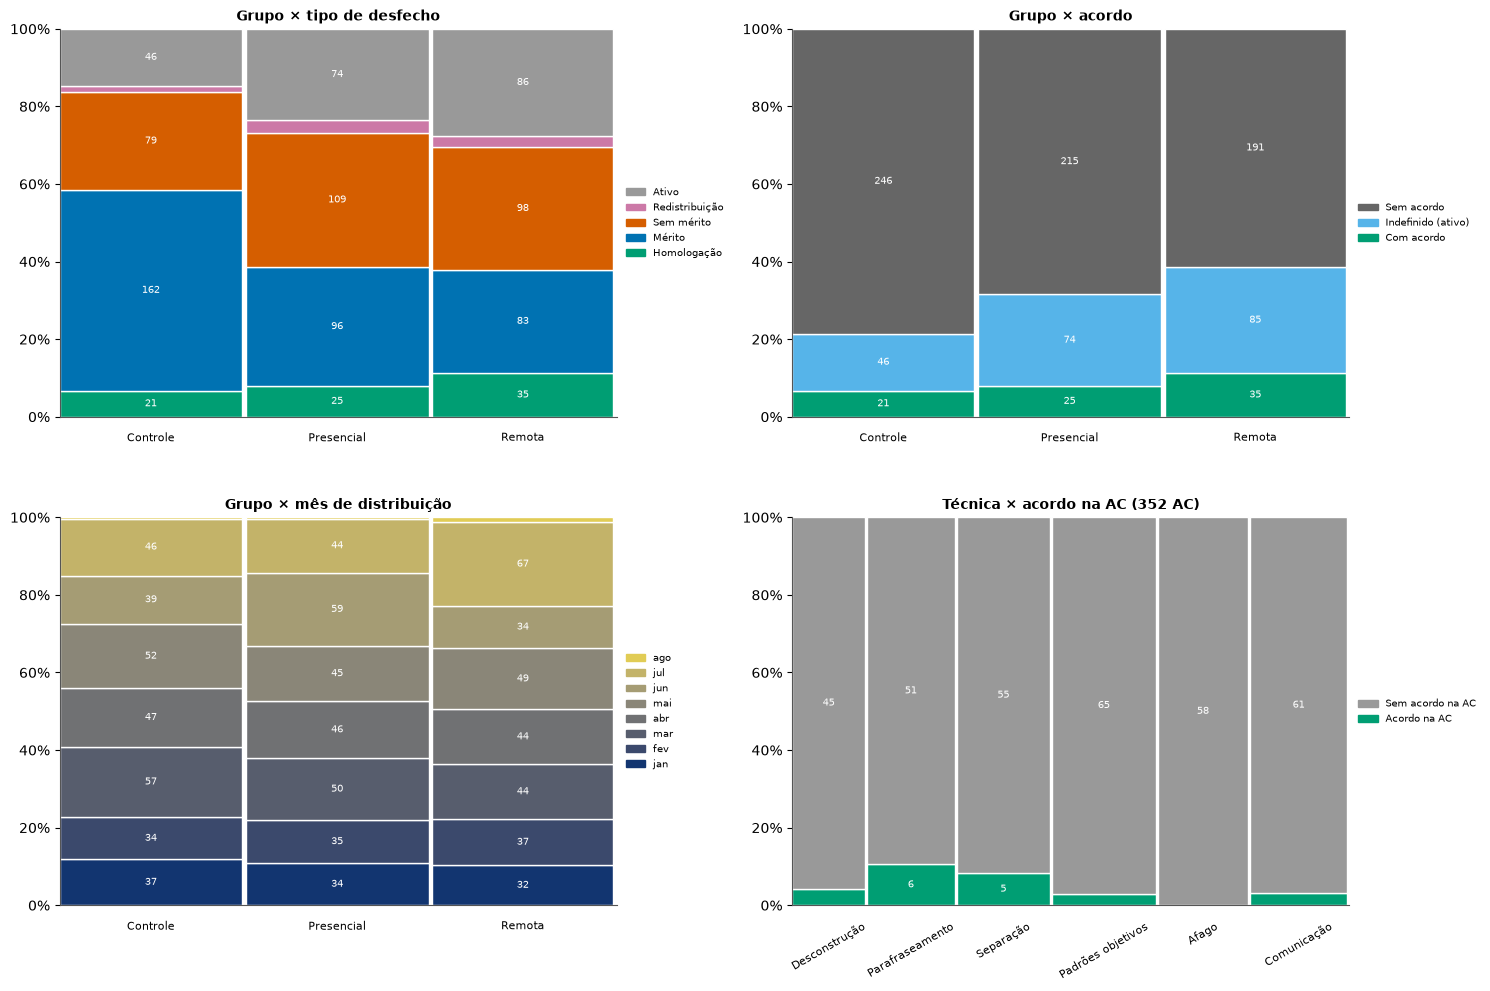

In [64]:
def mosaico(ax, ct, cores_col, titulo):
    # Mosaico manual: largura = tamanho da linha; altura = % na linha
    tot = ct.to_numpy().sum()
    x0 = 0
    for lin in ct.index:
        larg = ct.loc[lin].sum() / tot
        y0 = 0
        for colu in ct.columns:
            h = ct.loc[lin, colu] / ct.loc[lin].sum()
            ax.add_patch(mpl.patches.Rectangle((x0, y0), larg * 0.98, h, color=cores_col[colu], ec='white', lw=1))
            if h > 0.045:
                ax.text(x0 + larg * 0.49, y0 + h / 2, f'{int(ct.loc[lin, colu])}', ha='center', va='center', fontsize=7, color='white')
            y0 += h
        ax.text(x0 + larg * 0.49, -0.04, str(lin), ha='center', va='top', fontsize=8, rotation=0 if len(ct.index) <= 4 else 30)
        x0 += larg
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([]); ax.grid(False)
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
    ax.legend(handles=[mpl.patches.Patch(color=cores_col[c], label=str(c)) for c in ct.columns][::-1],
              loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=7)
    ax.set_title(titulo, fontsize=10)

cores_mes = dict(zip(MESES, sns.color_palette('cividis', len(MESES)).as_hex()))
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
mosaico(ax[0, 0], ct_desf, CORES_DESFECHO, 'Grupo × tipo de desfecho')
mosaico(ax[0, 1], ct_acordo, {'Com acordo': '#009E73', 'Sem acordo': '#666666', 'Indefinido (ativo)': '#56B4E9'}, 'Grupo × acordo')
mosaico(ax[1, 0], ct_mes, cores_mes, 'Grupo × mês de distribuição')
mosaico(ax[1, 1], ct_tec, {'Acordo na AC': '#009E73', 'Sem acordo na AC': '#999999'}, 'Técnica × acordo na AC (352 AC)')
plt.tight_layout(h_pad=4)
plt.show()

**Leitura (as associações são testadas na Parte III).**

- **Grupo × tipo de desfecho.** Na % na linha, o Controle tem 51,8% de sentenças de mérito, contra 30,6% (Presencial) e 26,7% (Remota); e menos extinções sem mérito (25,2% contra 34,7% e 31,5%). Os ativos são 14,7%, 23,6% e 27,7%. Na % na coluna, 47,5% de todas as sentenças de mérito vêm do Controle, e 43,2% das homologações vêm da Remota. No mosaico, as faixas não se alinham: a estrutura de desfechos muda com o rito.
- **Grupo × acordo.** Com acordo: 6,7% (Controle), 8,0% (Presencial) e 11,3% (Remota) dos processos; a categoria "indefinido" (ativos) cresce na mesma ordem, o que torna qualquer comparação de taxas de acordo sobre os distribuídos sensível à censura.
- **Grupo × mês.** A composição é parecida de janeiro a maio (cada grupo entre 29% e 38% de cada mês). As exceções são junho, com 44,7% de Presencial, e julho, com 42,7% de Remota (seção 2.5.1).
- **Técnica × acordo na AC.** As taxas de acordo vão de 0% (Afago, 0/58) a 10,5% (Parafraseamento, 6/57) e 8,3% (Separação, 5/60). As demais ficam entre 3,0% e 4,3%. Com 17 acordos no total, as diferenças são frágeis (células com 0 a 6 eventos).

### 2.6.4 Matriz de associação: a substituta correta da matriz de correlações do professor

**O problema da matriz original (questão 2.7; E6, E16).** O notebook do professor calculou uma matriz de correlação de Spearman entre as colunas `DURAÇÃO-SENT2`, `DURAÇÃO-SORT`, `DURAÇÃO-PROC` e `DURAÇÃO-TECN`. As três primeiras são **a mesma fórmula** repetida, e a quarta é a mesma duração apagada onde não houve técnica: a matriz dá r = 1 em todos os pares por construção (tautologia), não por achado empírico. Além disso, as demais variáveis do banco são **nominais** (grupo, desfecho, técnica, acordo, híbrida), e o coeficiente de Pearson ou Spearman sobre códigos numéricos de categorias não tem sentido. A célula abaixo reproduz o resultado tautológico a partir dos dados brutos.

**A matriz correta** usa, para cada par, a medida adequada aos níveis de mensuração:

| Par | Medida | Faixa |
|---|---|---|
| nominal × nominal | **V de Cramér com correção de viés** (Bergsma, 2013): corrige a inflação do V em tabelas grandes com n moderado | 0 a 1 |
| tempo (sentenciados) × nominal | **razão de correlação η** = √(SQ entre / SQ total) | 0 a 1 |
| ordinal × tempo | **Spearman ρ** e **Kendall τ_b** (seção 2.6.5) | −1 a 1 |

Cada par usa os casos com as duas variáveis definidas (exclusão aos pares). **Associações estruturais** (por exemplo, grupo × AC realizada: o Controle nunca tem AC) aparecem fortes por definição, e não são achados.

In [65]:
if 'dados_brutos' in globals():
    _brutos = dados_brutos
else:
    _brutos = pd.read_excel(BRUTO, sheet_name='Processos', header=1, engine='openpyxl')
cols_dur = ['DURAÇÃO-SENT2', 'DURAÇÃO-SORT', 'DURAÇÃO-PROC', 'DURAÇÃO-TECN']
matriz_prof = _brutos[cols_dur].apply(pd.to_numeric, errors='coerce').corr(method='spearman')
display(Markdown('**Matriz do notebook do professor (Spearman sobre as quatro colunas de duração): tautológica**'))
display(matriz_prof.round(4))
print('Linhas em que as colunas coincidem com DURAÇÃO-PROC:',
      {c: int((_brutos[c] == _brutos['DURAÇÃO-PROC']).sum()) for c in cols_dur}, '| não nulas:',
      {c: int(_brutos[c].notna().sum()) for c in cols_dur})

**Matriz do notebook do professor (Spearman sobre as quatro colunas de duração): tautológica**

,DURAÇÃO-SENT2,DURAÇÃO-SORT,DURAÇÃO-PROC,DURAÇÃO-TECN
DURAÇÃO-SENT2,1.0,1.0,1.0,1.0
DURAÇÃO-SORT,1.0,1.0,1.0,1.0
DURAÇÃO-PROC,1.0,1.0,1.0,1.0
DURAÇÃO-TECN,1.0,1.0,1.0,1.0


Linhas em que as colunas coincidem com DURAÇÃO-PROC: {'DURAÇÃO-SENT2': 943, 'DURAÇÃO-SORT': 943, 'DURAÇÃO-PROC': 943, 'DURAÇÃO-TECN': 428} | não nulas: {'DURAÇÃO-SENT2': 943, 'DURAÇÃO-SORT': 943, 'DURAÇÃO-PROC': 943, 'DURAÇÃO-TECN': 428}


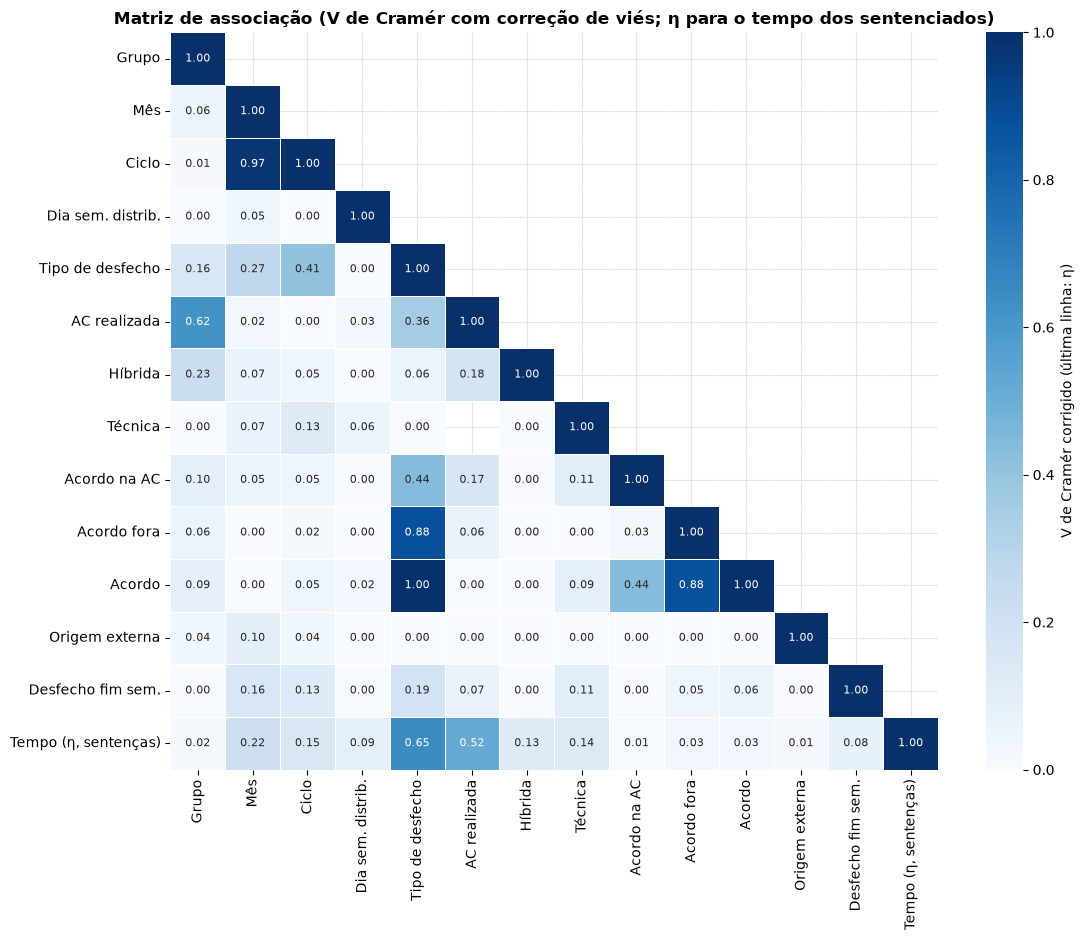

,,associação
Acordo,Tipo de desfecho,0.998
Ciclo,Mês,0.973
Acordo,Acordo fora,0.877
Acordo fora,Tipo de desfecho,0.875
"Tempo (η, sentenças)",Tipo de desfecho,0.651
AC realizada,Grupo,0.624
"Tempo (η, sentenças)",AC realizada,0.523
Acordo,Acordo na AC,0.436
Acordo na AC,Tipo de desfecho,0.435
Tipo de desfecho,Ciclo,0.408


In [66]:
def cramer_v_corrigido(x, y):
    ok = x.notna() & y.notna()
    ct = pd.crosstab(x[ok].astype(str), y[ok].astype(str))
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    n = ct.to_numpy().sum()
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    phi2 = chi2 / n
    r, c = ct.shape
    phi2c = max(0, phi2 - (c - 1) * (r - 1) / (n - 1))
    rc, cc = r - (r - 1) ** 2 / (n - 1), c - (c - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / min(rc - 1, cc - 1)) if min(rc, cc) > 1 else np.nan

VARS_ASSOC = {'grupo': 'Grupo', 'mes_distribuicao': 'Mês', 'ciclo': 'Ciclo', 'dia_semana_distribuicao': 'Dia sem. distrib.',
              'tipo_desfecho': 'Tipo de desfecho', 'ac_realizada': 'AC realizada', 'hibrida': 'Híbrida',
              'tecnica_curta': 'Técnica', 'acordo_ac': 'Acordo na AC', 'acordo_fora': 'Acordo fora',
              'acordo': 'Acordo', 'origem_externa': 'Origem externa', 'sentenca_fim_semana': 'Desfecho fim sem.'}
nomes = list(VARS_ASSOC.values())
mat_v = pd.DataFrame(np.nan, index=nomes + ['Tempo (η, sentenças)'], columns=nomes + ['Tempo (η, sentenças)'])
for i, (vi, ni) in enumerate(VARS_ASSOC.items()):
    for vj, nj in list(VARS_ASSOC.items())[i:]:
        val = 1.0 if vi == vj else cramer_v_corrigido(d2[vi].astype(object), d2[vj].astype(object))
        mat_v.loc[ni, nj] = mat_v.loc[nj, ni] = val
    eta = np.sqrt(eta2(sent['T'], sent[vi].astype(object))) if sent[vi].astype(object).nunique() > 1 else np.nan
    mat_v.loc[ni, 'Tempo (η, sentenças)'] = mat_v.loc['Tempo (η, sentenças)', ni] = eta
mat_v.loc['Tempo (η, sentenças)', 'Tempo (η, sentenças)'] = 1.0

fig, ax = plt.subplots(figsize=(11.5, 9.5))
mascara = np.triu(np.ones_like(mat_v, dtype=bool), k=1)
sns.heatmap(mat_v.astype(float), mask=mascara, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax,
            cbar_kws={'label': 'V de Cramér corrigido (última linha: η)'}, annot_kws={'fontsize': 8}, linewidths=0.5)
ax.set_title('Matriz de associação (V de Cramér com correção de viés; η para o tempo dos sentenciados)')
plt.tight_layout()
plt.show()
pares = (mat_v.where(~mascara & ~np.eye(len(mat_v), dtype=bool)).stack().sort_values(ascending=False))
display(pares.head(15).round(3).rename('associação').to_frame())

**Leitura. A matriz do professor era tautológica; a matriz correta separa associações estruturais de associações empíricas.**

- **Reprodução do erro (E6, E16).** As quatro colunas de duração da planilha coincidem em todas as linhas em que existem (943, 943, 943 e 428), e a matriz de Spearman entre elas dá 1,0 em todas as células: é a mesma variável, não uma correlação. Por isso a resposta à questão 2.7 é **não**: a matriz inicial não é adequada.
- **Associações estruturais (fortes por definição):** acordo × tipo de desfecho (V = 1,00: acordo ⇔ homologação); ciclo × mês (0,97); acordo × acordo fora (0,88); grupo × AC realizada (0,62: o Controle não tem AC); grupo × híbrida (0,23). A célula técnica × AC realizada fica vazia porque a técnica só existe quando há AC. Nenhuma delas é achado.
- **Associações empíricas relevantes:**
  - **grupo × tipo de desfecho, V = 0,16** (fraca a moderada): o efeito do rito sobre a composição dos desfechos (seções 2.5.2 e 2.6.3);
  - **tipo de desfecho × ciclo (0,41) e × mês (0,27):** efeito da censura (os meses tardios ainda não têm sentenças de mérito);
  - **tempo × tipo de desfecho, η = 0,65**, e **tempo × AC realizada, η = 0,52:** a etapa processual define o tempo;
  - **tempo × mês, η = 0,22:** censura de novo;
  - **tempo × grupo, η = 0,02:** desprezível entre os sentenciados (mas ver o efeito de composição na seção 2.6.1);
  - **grupo × mês, V = 0,06:** fraca, mas com as concentrações de junho e julho vistas acima;
  - **desfecho em fim de semana × tipo, V = 0,19** (seção 2.5.4).
- **Leitura geral.** As variáveis pós-sorteio (AC, acordo, tipo de desfecho) estão fortemente associadas ao tempo, e o grupo se associa ao tempo **através** delas. Isso orienta a modelagem: o efeito total do rito se estima sem essas variáveis (Parte IV); os mecanismos, com riscos competitivos e análises restritas às AC.

### 2.6.5 Ordem de chegada × tempo (questão 2.7)

**É possível investigar?** Sim: a ordem de chegada é uma variável **ordinal** (1 = primeiro distribuído), equivalente à data de distribuição, e o tempo é quantitativo; o par admite **Spearman ρ** e **Kendall τ_b** (robustos a não normalidade e a empates), nunca Pearson sobre os códigos. **Mas a censura cria uma correlação negativa espúria**: os processos que chegaram tarde têm seguimento curto (65 dias para os de agosto), então só podem aparecer como sentenciados se forem rápidos, e, se ativos, o seu tempo observado é pequeno. O tempo observado é limitado por cima pela "diagonal" `followup` = 07/10/2026 − distribuição.

Três versões, para separar o artefato do efeito:

1. **Todos os tempos observados** (mistura sentenças e censuras): inválida, mostrada para expor o artefato;
2. **Só os sentenciados**: condicional, enviesada pelo mesmo mecanismo;
3. **Tempo truncado em 65 dias**, min(tempo, 65), para os 938: como **todos** os processos têm pelo menos 65 dias de seguimento, essa variável é observada sem censura para todos (o redistribuído antes de 65 dias conta pelo seu tempo); é a comparação **justa** dentro de uma janela comum.

No painel da esquerda, a curva LOWESS (regressão local, fração de 0,3) mostra a tendência e a cor distingue sentenças de censurados; a linha laranja é o teto imposto pelo seguimento. No da direita, a versão 3 é resumida como a proporção de processos sentenciados em até 65 dias, por mês de distribuição e grupo, com o ρ de Spearman de cada grupo na legenda. O teste formal (Cox com a ordem ou o mês como covariável) fica para as Partes IV e V.

,n,Spearman ρ,p (ρ),Kendall τ_b,p (τ)
Versão,,,,,
Todos os tempos observados (inválido),938,-0.041,"0,211",-0.050,"0,024"
Só sentenciados (condicional),708,-0.118,"0,002",-0.082,"0,001"
"min(tempo, 65) — todos, janela comum",938,0.138,"< 0,001",0.105,"< 0,001"
Seguimento máximo (followup) — referência,938,-1.000,"< 0,001",-0.997,"< 0,001"
"min(tempo, 65) — Controle",313,0.034,"0,555",0.027,"0,529"
"min(tempo, 65) — Presencial",314,0.155,"0,006",0.118,"0,005"
"min(tempo, 65) — Remota",311,0.216,"< 0,001",0.165,"< 0,001"


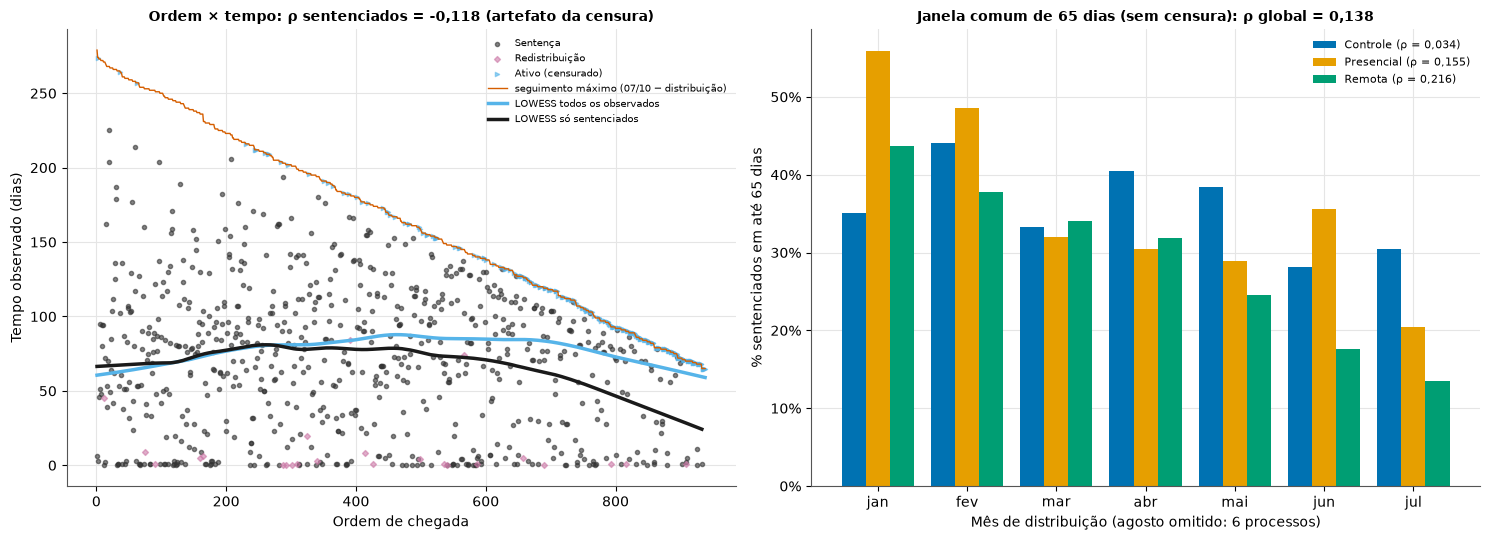

Sentenciados em até 65 dias: 32,5% dos 938; por ciclo: {'1º ciclo': '38,1%', '2º ciclo': '26,5%'}


In [67]:
ordem = d2['ordem_chegada'].astype(float)
d2['T65'] = np.minimum(d2['T'], 65)
versoes = {'Todos os tempos observados (inválido)': (ordem, d2['T']),
           'Só sentenciados (condicional)': (sent['ordem_chegada'].astype(float), sent['T']),
           'min(tempo, 65) — todos, janela comum': (ordem, d2['T65']),
           'Seguimento máximo (followup) — referência': (ordem, d2['followup'].astype(float))}
linhas = []
for nome, (xo, yt) in versoes.items():
    rho = stats.spearmanr(xo, yt); tau = stats.kendalltau(xo, yt)
    linhas.append({'Versão': nome, 'n': len(xo), 'Spearman ρ': rho.statistic, 'p (ρ)': p_br(rho.pvalue),
                   'Kendall τ_b': tau.statistic, 'p (τ)': p_br(tau.pvalue)})
for g in ORDEM_GRUPO:
    m = d2.grupo.eq(g)
    rho = stats.spearmanr(ordem[m], d2.loc[m, 'T65']); tau = stats.kendalltau(ordem[m], d2.loc[m, 'T65'])
    linhas.append({'Versão': f'min(tempo, 65) — {g}', 'n': int(m.sum()), 'Spearman ρ': rho.statistic,
                   'p (ρ)': p_br(rho.pvalue), 'Kendall τ_b': tau.statistic, 'p (τ)': p_br(tau.pvalue)})
tab_ordem = pd.DataFrame(linhas).set_index('Versão')
display(tab_ordem.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for s, cor, mk in [('Sentença', '#333333', 'o'), ('Redistribuição', '#CC79A7', 'D'), ('Ativo (censurado)', '#56B4E9', '>')]:
    m = d2.status.eq(s)
    ax[0].scatter(ordem[m], d2.loc[m, 'T'], s=9, color=cor, marker=mk, alpha=0.6, label=s)
ax[0].plot(ordem.sort_values(), d2.loc[ordem.sort_values().index, 'followup'], color='#D55E00', lw=1,
           label='seguimento máximo (07/10 − distribuição)')
for nome, (xo, yt), cor in [('LOWESS todos os observados', versoes['Todos os tempos observados (inválido)'], '#56B4E9'),
                            ('LOWESS só sentenciados', versoes['Só sentenciados (condicional)'], TINTA)]:
    lw_ = lowess(yt.to_numpy(float), xo.to_numpy(float), frac=0.3)
    ax[0].plot(lw_[:, 0], lw_[:, 1], color=cor, lw=2.5, label=nome)
ax[0].set_xlabel('Ordem de chegada'); ax[0].set_ylabel('Tempo observado (dias)')
ax[0].set_title(f'Ordem × tempo: ρ sentenciados = {fmt_br(tab_ordem.iloc[1]["Spearman ρ"], 3)} (artefato da censura)', fontsize=10)
ax[0].legend(fontsize=7, loc='upper right')
d2['sent65'] = d2['T'].le(65) & d2['E'].eq(1)
prop65 = d2.groupby(['mes_distribuicao', 'grupo'], observed=True)['sent65'].mean().unstack().reindex(columns=ORDEM_GRUPO)
prop65 = prop65.drop(index='ago')   # 6 processos
x = np.arange(len(prop65)); w = 0.27
for j, g in enumerate(ORDEM_GRUPO):
    ax[1].bar(x + (j - 1) * w, prop65[g], width=w, color=CORES_GRUPO[g],
              label=f'{g} (ρ = {fmt_br(tab_ordem.loc[f"min(tempo, 65) — {g}", "Spearman ρ"], 3)})')
ax[1].set_xticks(x, prop65.index); ax[1].set_xlabel('Mês de distribuição (agosto omitido: 6 processos)')
ax[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax[1].set_ylabel('% sentenciados em até 65 dias')
ax[1].set_title(f'Janela comum de 65 dias (sem censura): ρ global = {fmt_br(tab_ordem.iloc[2]["Spearman ρ"], 3)}', fontsize=10)
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f'Sentenciados em até 65 dias: {pct_br((d2["T"].le(65) & d2.E.eq(1)).mean())} dos 938; '
      f'por ciclo: {(d2.assign(s65=d2["T"].le(65) & d2.E.eq(1)).groupby("ciclo", observed=True)["s65"].mean().map(pct_br).to_dict())}')

**Leitura (questão 2.7). A correlação negativa entre ordem de chegada e tempo é artefato; na janela comum, ela se inverte.**

- **Versões ingênuas.** Com todos os tempos observados, ρ = −0,041 (p = 0,211; τ_b = −0,050, p = 0,024). Só com os sentenciados, ρ = **−0,118** (p = 0,002; τ_b = −0,082). O sinal negativo é o esperado pelo mecanismo da censura: no gráfico da esquerda, os pontos ficam sob o "teto" do seguimento máximo (ρ = −1 entre ordem e seguimento, por construção), e a curva LOWESS dos sentenciados cai depois da posição 600, porque os processos de junho e julho só aparecem como sentenciados se forem rápidos.
- **Versão justa: min(tempo, 65).** Como todos os processos têm pelo menos 65 dias de seguimento, essa variável é observada para todos, sem censura. O sinal se **inverte**: ρ = **+0,138** (p < 0,001; τ_b = +0,105). Os processos que chegaram depois demoraram mais nos primeiros 65 dias: 38,1% dos do 1º ciclo foram sentenciados nesse prazo, contra 26,5% dos do 2º ciclo.
- **E isso só nos tratados.** No Controle, ρ = 0,034 (p = 0,555); na Presencial, ρ = 0,155 (p = 0,006); na Remota, ρ = 0,216 (p < 0,001). O gráfico da direita mostra a fração sentenciada em até 65 dias caindo de janeiro (44% na Remota, 56% na Presencial) para julho (13% e 20%), enquanto o Controle oscila entre 28% e 44% sem tendência. A leitura mais provável é o **congestionamento da pauta de audiências**: à medida que o experimento avançou, a fila de AC (presenciais até 22/10 e remotas até 24/11) alongou o início dos processos tratados, o que não aconteceu no rito sem audiência.
- **Resposta à questão 2.7.** É possível investigar a relação entre a ordem de chegada e a duração, com Spearman ou Kendall (a ordem é ordinal), mas não sobre `duracao_proc` bruta, que mistura censurados; é preciso uma janela comum (como aqui) ou um modelo de sobrevivência com a ordem ou o mês como covariável (Partes IV e V). O resultado aponta uma **interação entre rito e calendário**, relevante para a validade interna: o efeito da AC obrigatória sobre o tempo parece ter crescido ao longo do experimento.

## 2.7 Síntese exploratória

A tabela reúne os achados da Parte II, a medida que os sustenta e o encaminhamento para as partes seguintes.

In [68]:
melhor_aic = tab_ajuste['AIC'].idxmin()
melhor_param = tab_ajuste.drop(index='Exponencial por partes')['AIC'].idxmin()
sintese = pd.DataFrame([
    ('Variável-alvo', f'{len(sent)} sentenças, {(d2.evento_cr == 0).sum()} ativos e {(d2.evento_cr == 2).sum()} redistribuições; seguimento de 65 a 279 dias',
     'Tempo censurado: análise de sobrevivência (Parte IV)'),
    ('Médias da pesquisa', f'78,46 e 75,2 reproduzidas como médias "mistas" (sentenças + ativos) com corte em 07/10 '
     f'({fmt_br(tab_medias.loc["Todos", "Mista, 944 linhas, corte 07/10 (planilha: 78,46)"], 2)}) e 23/09 '
     f'({fmt_br(tab_medias.loc["Todos", "Mista, 944 linhas, corte 23/09 (resumo: 75,2)"], 2)}); só sentenciados = {fmt_br(sent["T"].mean(), 2)}; '
     f'mediana do KM = {fmt_br(kmf_total.median_survival_time_)}',
     'Nenhuma estima a duração; substituir por mediana do KM e RMST (Parte IV)'),
    ('Distribuição das sentenças', f'mediana {fmt_br(tab_desc.loc["mediana", "Sentenças (condicional)"])} d '
     f'(IC95% {fmt_br(tab_desc.loc["IC95% mediana (inf.)", "Sentenças (condicional)"])}–{fmt_br(tab_desc.loc["IC95% mediana (sup.)", "Sentenças (condicional)"])}); '
     f'assimetria {fmt_br(tab_desc.loc["assimetria", "Sentenças (condicional)"], 2)}; curtose {fmt_br(tab_desc.loc["curtose (excesso)", "Sentenças (condicional)"], 2)}',
     'Bimodal (extinções precoces × mérito)'),
    ('Normalidade', f'{(tab_norm["Decisão (5%)"] == "rejeita H0").sum()} de {len(tab_norm)} testes rejeitam H0 (Holm)',
     'Testes não paramétricos na Parte III'),
    ('Ajuste com censura', f'menor AIC: {melhor_aic}; melhor paramétrico: {melhor_param}',
     'Risco não monótono (pico inicial, vale, subida): nenhum AFT padrão ajusta bem; preferir Cox, KM e RMST'),
    ('Sorteio dos grupos', f'313/314/311: P(divisão tão equilibrada) = {fmt_br(tab_equilibrio.iloc[1]["P(divisão tão equilibrada) exata (esq.)"], 4)}',
     'Aleatorização com totais equilibrados (não blocos pequenos): documentar; corridas na Parte III'),
    ('Índice de conciliação', f'{tab_bin.iloc[0]["k"]}/{tab_bin.iloc[0]["n"]} = {pct_br(tab_bin.iloc[0]["p̂"])} das sentenças '
     f'({p_txt(tab_bin.iloc[0]["p"])} contra 13,3%)', 'Comparação entre grupos na Parte III; riscos competitivos na Parte IV'),
    ('Sem mérito', f'Controle {pct_br(tab_sm.iloc[0]["p̂"])} × Presencial {pct_br(tab_sm.iloc[1]["p̂"])} × Remota {pct_br(tab_sm.iloc[2]["p̂"])} das sentenças',
     'Excesso concentrado em extinções precoces sem AC; testar na Parte III e conferir motivos no PJe'),
    ('Acordo na AC', f'{int(ac.acordo_ac.sum())}/{len(ac)} = {pct_br(ac.acordo_ac.mean())} das AC realizadas',
     'Logit restrito às AC na Parte V'),
    ('Técnicas', f'Padrões objetivos = {pct_br(k_po / n_ac)} (não 53,85%); aderência a 1/6: p = {p_br(tab_tec.iloc[0]["p exato (Monte Carlo)"])}',
     'Sorteio das técnicas compatível com uniforme'),
    ('Fim de semana', f'{pct_br(tab_fds.iloc[0]["p̂"])} dos desfechos ({p_txt(tab_fds.iloc[0]["p"])} contra 2/7)',
     'Data = assinatura eletrônica; conferir no PJe'),
    ('Ordem × tempo', f'ρ sentenciados = {fmt_br(tab_ordem.iloc[1]["Spearman ρ"], 3)}; ρ na janela de 65 d = {fmt_br(tab_ordem.iloc[2]["Spearman ρ"], 3)}',
     'Cox com mês/ordem (Partes IV e V)'),
], columns=['Tema', 'Resultado', 'Encaminhamento'])
with pd.option_context('display.max_colwidth', 140):
    display(sintese.set_index('Tema'))

,Resultado,Encaminhamento
Tema,,
Variável-alvo,"708 sentenças, 206 ativos e 24 redistribuições; seguimento de 65 a 279 dias",Tempo censurado: análise de sobrevivência (Parte IV)
Médias da pesquisa,"78,46 e 75,2 reproduzidas como médias ""mistas"" (sentenças + ativos) com corte em 07/10 (78,45) e 23/09 (75,15); só sentenciados = 70,98;...",Nenhuma estima a duração; substituir por mediana do KM e RMST (Parte IV)
Distribuição das sentenças,"mediana 73,5 d (IC95% 70,0–78,0); assimetria 0,21; curtose -0,56",Bimodal (extinções precoces × mérito)
Normalidade,17 de 20 testes rejeitam H0 (Holm),Testes não paramétricos na Parte III
Ajuste com censura,menor AIC: Exponencial por partes; melhor paramétrico: Gama generalizada,"Risco não monótono (pico inicial, vale, subida): nenhum AFT padrão ajusta bem; preferir Cox, KM e RMST"
Sorteio dos grupos,"313/314/311: P(divisão tão equilibrada) = 0,0105",Aleatorização com totais equilibrados (não blocos pequenos): documentar; corridas na Parte III
Índice de conciliação,"81/708 = 11,4% das sentenças (p = 0,150 contra 13,3%)",Comparação entre grupos na Parte III; riscos competitivos na Parte IV
Sem mérito,"Controle 30,2% × Presencial 47,4% × Remota 45,4% das sentenças",Excesso concentrado em extinções precoces sem AC; testar na Parte III e conferir motivos no PJe
Acordo na AC,"17/352 = 4,8% das AC realizadas",Logit restrito às AC na Parte V


**Síntese da Parte II.**

1. **A variável-alvo é censurada.** São 708 sentenças, 206 ativos e 24 redistribuições, com seguimento de 65 a 279 dias que depende do mês de entrada. Todas as médias divulgadas (78,46 e 75,2) foram reconstituídas como médias "mistas" de durações completas e tempos parciais, e crescem com a data de corte; a mediana com censura (Kaplan-Meier) é de 89 dias.
2. **A distribuição é bimodal** (extinções imediatas × julgamentos de mérito por volta de 100 dias), não normal (17 de 20 testes rejeitam após Holm) e com risco não monótono: pico inicial, vale entre 15 e 60 dias e platô depois de 90. Nenhuma distribuição paramétrica usual se ajusta bem; a gama generalizada é a melhor delas e a exponencial por partes, a melhor de todas. Isso favorece métodos não paramétricos e semiparamétricos.
3. **O sorteio dos grupos** produziu totais equilibrados demais para uma aleatorização simples (P = 1,05%), sem a regularidade de blocos pequenos, e com concentrações em junho (Presencial) e julho (Remota). Isso deve ser documentado, e o mês deve entrar nos modelos. **O sorteio das técnicas** é compatível com o uniforme entre seis técnicas; o "53,85%" do resumo expandido não se confirma.
4. **Proporções.** O índice de conciliação (homologações ÷ sentenças) é de 11,4%, compatível com o histórico de 13,3%; o acordo na AC é de 4,8% das audiências. Os tratados têm 15 a 17 pontos percentuais a mais de extinções sem mérito, concentradas nos primeiros dias e sem audiência.
5. **Relações bivariadas.** Entre os sentenciados, o grupo não explica o tempo (η² = 0,000), mas, dentro de cada tipo de desfecho, os tratados são mais lentos (mérito: 83 dias no Controle, contra 106 a 112,5 nos tratados). Na janela comum de 65 dias, os tratados ficaram mais lentos ao longo do calendário, e o Controle não.

**Hipóteses levadas às Partes III a V:** (i) a AC obrigatória alonga o tempo até a sentença de mérito e muda a composição dos desfechos; (ii) o efeito cresce com o calendário (pauta); (iii) o efeito sobre o acordo, se existe, vem dos acordos fora da audiência. As três exigem comparar processos da mesma idade, com censura, o que só a análise de sobrevivência faz.